# Dual-Skip v4 — chạy trực tiếp và xem kết quả

Chạy lần lượt các cell trong Jupyter hoặc VS Code. Notebook sử dụng các module trong
**method2/src**: giữ cả thư mục `method2` bên cạnh notebook. Không cần API/server.

**Chạy thật là mặc định.** Mặc định lấy mẫu DocLayNet 50 ảnh và chạy 20 ảnh đầu.
Để dùng ảnh/PDF riêng, đặt `USE_DOCLAYNET_SAMPLE=False` và điền `INPUT_PATH`.
Lần đầu cần tải trọng số
PaddleOCR và GLM-OCR, hoặc trỏ tới model đã lưu cục bộ. Paddle chạy GPU 0 (cần paddlepaddle-gpu),
GLM xử lý từng crop bằng CUDA FP16; có thể đổi `GLM_DEVICE="cpu"` nếu thiếu VRAM.

## 1. Xác định thư mục và chuẩn bị thư viện

In [1]:
import sys
from pathlib import Path

candidates = [p for base in (Path.cwd(), *Path.cwd().parents)
              for p in (base, base / "method2")]
METHOD2_ROOT = next((p.resolve() for p in candidates
                    if (p / "src/pipeline.py").is_file()
                    and (p / "configs/default.yaml").is_file()), None)
if METHOD2_ROOT is None:
    raise RuntimeError("Mở notebook từ thư mục repository hoặc method2.")
existing_src = sys.modules.get("src")
if existing_src is not None:
    origin = getattr(existing_src, "__file__", None)
    if origin is None or Path(origin).resolve().parent != METHOD2_ROOT / "src":
        raise RuntimeError("Kernel đã import package src khác. Restart Kernel rồi chạy lại.")
if str(METHOD2_ROOT) not in sys.path:
    sys.path.insert(0, str(METHOD2_ROOT))
print("method2:", METHOD2_ROOT)
print("Python kernel:", sys.executable)


method2: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2
Python kernel: c:\Users\ACER\AppData\Local\Programs\Python\Python312\python.exe


In [2]:
# Chỉ bật nếu cần cài các thư viện còn thiếu. Không cài/thay bản torch CUDA ở đây.
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-r",
                           str(METHOD2_ROOT / "requirements-notebook.txt")])
    print("Cài xong. Nếu kernel đã import phiên bản cũ, Restart Kernel trước khi chạy tiếp.")


### Cài Paddle GPU (chạy một lần khi chuyển từ CPU)

Chạy cell dependency chung trước, sau đó bật `INSTALL_PADDLE_GPU=True` ở cell dưới.
Cell dùng đúng Python của kernel, gỡ bản Paddle CPU/GPU cũ rồi cài bản GPU CUDA 12.6;
không thay PyTorch. Nếu đã nạp Paddle, Restart Kernel trước khi cài. Cài xong phải
Restart Kernel và đặt lại cờ thành `False` trước khi Run All.

Lệnh theo [hướng dẫn Windows chính thức của Paddle](https://github.com/PaddlePaddle/docs/blob/develop/docs/install/pip/windows-pip_en.md).
GPU 4 GB có thể thiếu VRAM khi chạy đồng thời Paddle và GLM.


In [3]:
# Chạy sau cell cài dependency chung; chỉ bật khi cần chuyển Paddle CPU sang GPU.
# Restart Kernel trước nếu đã nạp Paddle, và Restart Kernel sau khi cài xong.
INSTALL_PADDLE_GPU = False
PADDLE_GPU_VERSION = "3.2.2"
PADDLE_GPU_INDEX = "https://www.paddlepaddle.org.cn/packages/stable/cu126/"
if INSTALL_PADDLE_GPU:
    import subprocess
    import sys
    if "paddle" in sys.modules:
        raise RuntimeError("Paddle đã được nạp. Restart Kernel rồi chạy cell này trước khi nạp mô hình.")
    subprocess.check_call([sys.executable, "-m", "pip", "uninstall", "-y",
                           "paddlepaddle", "paddlepaddle-gpu"])
    subprocess.check_call([sys.executable, "-m", "pip", "install",
                           f"paddlepaddle-gpu=={PADDLE_GPU_VERSION}", "-i", PADDLE_GPU_INDEX])
    print("Đã cài Paddle GPU. Restart Kernel, giữ INSTALL_PADDLE_GPU=False khi chạy lại.")
else:
    print("Bỏ qua cài Paddle GPU. Đổi INSTALL_PADDLE_GPU=True nếu đang dùng bản CPU.")


Bỏ qua cài Paddle GPU. Đổi INSTALL_PADDLE_GPU=True nếu đang dùng bản CPU.


In [4]:
import importlib.metadata as metadata
from IPython.display import display, Markdown, HTML
import pandas as pd
import torch

packages = ["torch", "transformers", "paddlepaddle", "paddlepaddle-gpu", "paddleocr", "Pillow",
            "matplotlib", "pandas", "PyMuPDF", "ipykernel"]
versions = []
for package in packages:
    try:
        version = metadata.version(package)
    except metadata.PackageNotFoundError:
        version = "CHƯA CÀI — bật cell cài thư viện ở trên"
    versions.append({"thư viện": package, "phiên bản": version})
display(pd.DataFrame(versions))
if torch.cuda.is_available():
    free, total = torch.cuda.mem_get_info()
    print(f"GPU: {torch.cuda.get_device_name(0)} | trống {free / 2**30:.2f}/{total / 2**30:.2f} GiB")
else:
    print("CUDA không khả dụng: GLM auto sẽ chạy CPU, có thể chậm hơn.")


,thư viện,phiên bản
0,torch,2.11.0+cu128
1,transformers,5.20.1
2,paddlepaddle,CHƯA CÀI — bật cell cài thư viện ở trên
3,paddlepaddle-gpu,3.2.2
4,paddleocr,3.7.0
5,Pillow,12.3.0
6,matplotlib,3.10.8
7,pandas,2.3.3
8,PyMuPDF,1.28.0
9,ipykernel,7.1.0


GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU | trống 3.22/4.00 GiB


## 2. Cấu hình

`PAGES=None` chạy tất cả các trang PDF; `[1, 3]` chạy trang 1 và 3. Ảnh chỉ có trang 1.
Đường dẫn tương đối được tính từ thư mục làm việc của kernel; nên dùng đường dẫn tuyệt đối.
`MAX_REGION_PREVIEWS=None` để xem tất cả crop. Thay model/device thì chạy lại cell khởi tạo.

In [5]:
USE_DOCLAYNET_SAMPLE = True
DOCLAYNET_DOWNLOAD_COUNT = 50
DOCLAYNET_RUN_COUNT = 20
DOCLAYNET_SPLIT = "test"
DOCLAYNET_SAMPLE_DIR = METHOD2_ROOT / "outputs" / f"doclaynet_sample_{DOCLAYNET_SPLIT}"
INPUT_PATH = r""  # Ví dụ: r"D:\Tai lieu\trang.png" hoặc r"D:\Tai lieu\bao cao.pdf"
PAGES = None
PDF_DPI = 150
GLM_MODEL = "zai-org/GLM-OCR"  # Hoặc đường dẫn thư mục model đã tải
GLM_DEVICE = "auto"          # "auto", "cuda", "cpu"
GLM_MAX_CROP_EDGE = 1280
GLM_MAX_NEW_TOKENS = 1024
MAX_REGION_PREVIEWS = 20
SAVE_OUTPUTS = True
OUTPUT_ROOT = METHOD2_ROOT / "outputs/notebook_residual_glm"
MOCK_MODE = False            # Chỉ bật để kiểm tra luồng; không OCR nội dung thật

CLASSIFY_UNLABELED_REGIONS = True  # GLM classifies residual regions with page context


### Tải mẫu DocLayNet nhẹ: 50 ảnh, chạy thử 20 ảnh

Cell này gọi script `scripts/download_datasets/download_doclaynet.py` của repository ở chế độ
`--lightweight`: chỉ tải ảnh và annotation được chọn, không tải cả shard parquet.
Dữ liệu đã có được tái sử dụng. Mặc định lấy 50 ảnh đầu của split test và chạy 20 ảnh đầu,
phù hợp kiểm tra luồng; đây không phải mẫu ngẫu nhiên đại diện để kết luận benchmark.

In [6]:
if USE_DOCLAYNET_SAMPLE:
    import json
    import subprocess

    DOCLAYNET_SAMPLE_DIR = Path(DOCLAYNET_SAMPLE_DIR).expanduser().resolve()
    if not 1 <= DOCLAYNET_RUN_COUNT <= DOCLAYNET_DOWNLOAD_COUNT <= 1000:
        raise ValueError("Cần 1 <= số ảnh chạy <= số ảnh tải <= 1000.")
    download_script = METHOD2_ROOT.parent / "scripts/download_datasets/download_doclaynet.py"
    if not download_script.is_file():
        raise FileNotFoundError(f"Thiếu script tải DocLayNet: {download_script}")
    subprocess.run([sys.executable, str(download_script), "--lightweight", "--splits", DOCLAYNET_SPLIT,
        "--max-images", str(DOCLAYNET_DOWNLOAD_COUNT), "--sample-output-dir", str(DOCLAYNET_SAMPLE_DIR)],
        check=True)
    sample_manifest = json.loads((DOCLAYNET_SAMPLE_DIR / "annotations" / f"{DOCLAYNET_SPLIT}.json")
                                 .read_text(encoding="utf-8"))
    sample_records = sample_manifest["images"][:DOCLAYNET_RUN_COUNT]
    if len(sample_records) != DOCLAYNET_RUN_COUNT:
        raise ValueError("Chưa đủ ảnh mẫu; chạy lại cell tải dữ liệu.")
    doclaynet_run_paths = [DOCLAYNET_SAMPLE_DIR / "images" / record["file_name"] for record in sample_records]
    if not all(path.is_file() for path in doclaynet_run_paths):
        raise FileNotFoundError("Thiếu ảnh mẫu; chạy lại cell tải dữ liệu để bổ sung.")
    print(f"Đã chuẩn bị {len(sample_manifest['images'])} ảnh; sẽ chạy {len(doclaynet_run_paths)} ảnh.")
    display(pd.DataFrame(sample_records)[["id", "file_name", "width", "height"]])
else:
    print("Dùng INPUT_PATH; bỏ qua tải DocLayNet.")


Đã chuẩn bị 50 ảnh; sẽ chạy 20 ảnh.


,id,file_name,width,height
0,1,1.png,1025,1025
1,2,2.png,1025,1025
2,3,3.png,1025,1025
3,4,4.png,1025,1025
4,5,5.png,1025,1025
5,6,6.png,1025,1025
6,7,7.png,1025,1025
7,8,8.png,1025,1025
8,9,9.png,1025,1025
9,10,10.png,1025,1025


## 3. Nạp ảnh/PDF và xem trang đầu đã chọn

Tài liệu: 1.png | trang đầu được chọn: 1


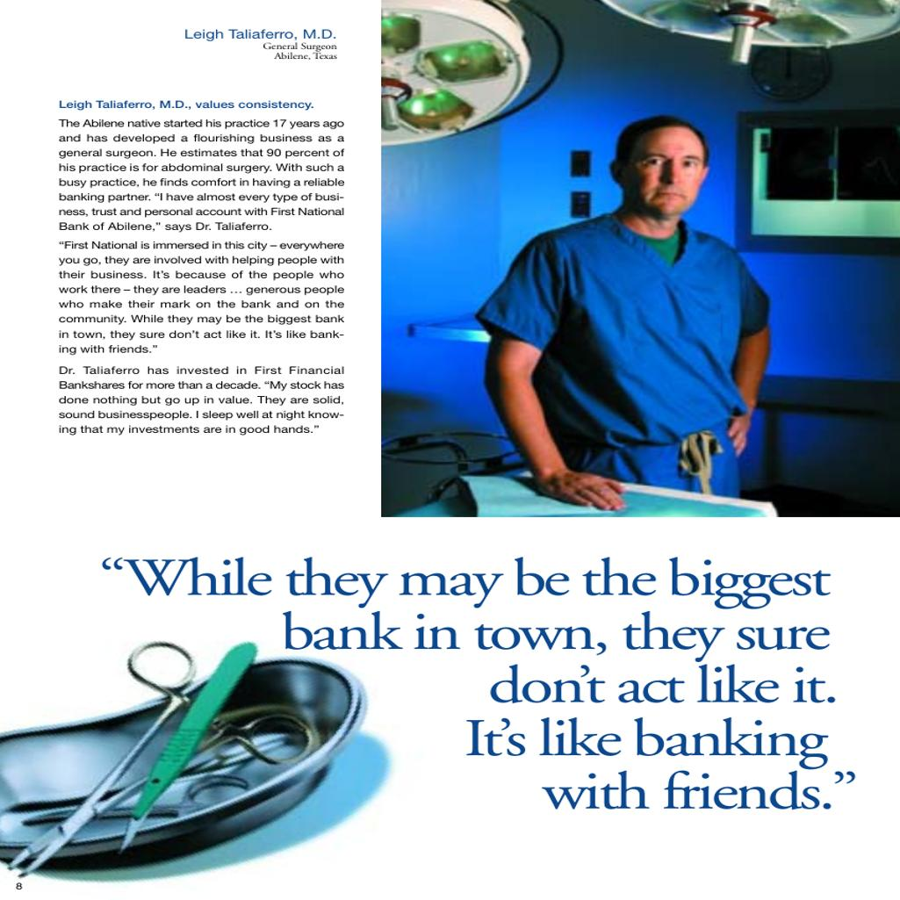

In [7]:
import itertools
import cv2
from PIL import Image
from src.document_io import iter_document_pages

if not USE_DOCLAYNET_SAMPLE and not str(INPUT_PATH).strip():
    raise ValueError("Hãy điền INPUT_PATH trong cell cấu hình trước.")
if "page_iterator" in globals():
    page_iterator.close()
input_paths = doclaynet_run_paths if USE_DOCLAYNET_SAMPLE else [Path(INPUT_PATH).expanduser().resolve()]
def selected_document_pages():
    for input_path in input_paths:
        yield from iter_document_pages(input_path, None if USE_DOCLAYNET_SAMPLE else PAGES, dpi=PDF_DPI)
page_iterator = selected_document_pages()
first_page = next(page_iterator)
document_path = first_page.source_path
document_pages = itertools.chain([first_page], page_iterator)
print(f"Tài liệu: {document_path.name} | trang đầu được chọn: {first_page.page_number}")
preview = Image.fromarray(cv2.cvtColor(first_page.image, cv2.COLOR_BGR2RGB))
preview.thumbnail((900, 1000))
display(preview)


## 4. Khởi tạo mô hình — nạp một lần, tái sử dụng cho mọi trang

PaddleOCR chạy GPU 0 cùng GLM, cần cài paddlepaddle-gpu. GPU 4 GB có thể thiếu VRAM. Bộ nhớ GPU còn phụ thuộc kích thước crop và
lượng token sinh. Nếu OOM, đóng mô hình ở cell cuối, đổi sang CPU hoặc giảm hai giới hạn
GLM rồi chạy lại cell này. Không tự chuyển sang mock khi mô hình lỗi.

In [8]:
import asyncio
import json
import gc
from src.pipeline import load_config, parse_page
from src.runtime import create_adapters, close_adapters

config = load_config({
    "models": {"semantic_parser": GLM_MODEL},
    "routing": {"classify_unlabeled_regions": CLASSIFY_UNLABELED_REGIONS},
    "inference": {"device": GLM_DEVICE, "max_crop_edge": GLM_MAX_CROP_EDGE,
                  "max_new_tokens": GLM_MAX_NEW_TOKENS, "max_in_flight": 1},
})
new_key = json.dumps({"models": config["models"], "inference": config["inference"],
                      "mock": MOCK_MODE}, sort_keys=True)
if globals().get("adapters_key") != new_key or "adapters" not in globals():
    if "adapters" in globals():
        close_adapters(adapters)
        del adapters
        gc.collect()
    adapters = create_adapters(config, mock_mode=MOCK_MODE)
    adapters_key = new_key
# Windows: isolate Paddle CUDA DLLs in a local child process.
if not MOCK_MODE and hasattr(adapters[0], "initialize"):
    await asyncio.to_thread(adapters[0].initialize)
try:
    await asyncio.to_thread(adapters[-1].initialize)
except Exception:
    display(Markdown("**Nạp GLM thất bại.** Xem lỗi bên dưới. Nếu thiếu VRAM, đổi "
                     '`GLM_DEVICE="cpu"` rồi chạy lại cell khởi tạo.'))
    raise
print("GLM:", adapters[-1].device, "| PaddleOCR: GPU 0 (gpu:0)")
if MOCK_MODE:
    display(Markdown("### MOCK — mọi nội dung nhận dạng là dữ liệu giả lập, không phải kết quả thật."))


c:\Users\ACER\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1024 20:03:02.861000 21564 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Loading weights: 100%|██████████| 510/510 [00:02<00:00, 176.42it/s]


GLM: cuda | PaddleOCR: GPU 0 (gpu:0)


### Thử một crop residual trước khi chạy batch

Sau khi nạp GLM, bật `RUN_TARGET_PROBE=True` để thử riêng `recovered:1` của `1.png`.
Cell hiển thị chính ảnh gửi cho GLM, OCR theo prompt chuẩn và JSON phân loại; dùng hai
lượt suy luận riêng để chẩn đoán, không đổi các kết quả đã lưu hay tự chấp nhận nhãn.
Chỉnh đường dẫn nếu dùng tài liệu khác. Mặc định tắt khi Run All.


In [9]:
# Thử đúng một vùng trước khi chạy cả batch; dùng GLM đã nạp, không nạp model thứ hai.
RUN_TARGET_PROBE = False
PROBE_RESULT = METHOD2_ROOT / "outputs/notebook_residual_glm/1/page_0001/result.json"
PROBE_IMAGE = METHOD2_ROOT / "outputs/doclaynet_sample_test/images/1.png"
PROBE_REGION = "recovered:1"
if RUN_TARGET_PROBE:
    import cv2
    import numpy as np
    from PIL import Image
    from src.schemas.region import LayoutRegion
    from src.semantic.residual_labeling import build_target_crop
    from src.semantic.residual_prompt import build_classification_prompt, parse_classification_with_note
    from src.semantic.probe_scheduler import ProbeScheduler
    from src.semantic.evidence_features import calculate_content_consistency
    saved = json.loads(PROBE_RESULT.read_text(encoding="utf-8"))
    record = next(r for r in saved["final_regions"] if r["id"] == PROBE_REGION)
    image = cv2.imdecode(np.fromfile(str(PROBE_IMAGE), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Không đọc được ảnh: {PROBE_IMAGE}")
    region = LayoutRegion(id=PROBE_REGION, bbox=record["bbox_final"], label="residual")
    target = build_target_crop(image, region.bbox)
    display(Image.fromarray(cv2.cvtColor(target, cv2.COLOR_BGR2RGB)))
    display(Markdown("**OCR đang có:** " + record["content"]))
    prompt = build_classification_prompt(region, (image.shape[1], image.shape[0]), record["content"])
    probe_evidence = await ProbeScheduler(2, 1).run(adapters[-1], [
        ("probe:target_ocr", target, "Text Recognition:"),
        ("classify:probe_target", target, prompt),
    ])
    probe_report = {"region": PROBE_REGION, "mode": "MOCK" if MOCK_MODE else "REAL",
                    "scope": "diagnostic only; no relabel acceptance or saved results modified",
                    "reference_ocr": record["content"], "evidence": [e.model_dump() for e in probe_evidence]}
    if probe_evidence[1].status == "ok":
        try:
            classified, note = parse_classification_with_note(probe_evidence[1].content)
            probe_report.update(proposed_label=classified.label, target_text=classified.text, normalization=note,
                transcript_agreement=calculate_content_consistency(classified.text, [record["content"]]))
        except ValueError as exc:
            probe_report["parse_error"] = str(exc)
    display(HTML("<details open><summary>Đầu ra thô và đối chiếu crop</summary><pre>" +
                 __import__("html").escape(json.dumps(probe_report, ensure_ascii=False, indent=2)) + "</pre></details>"))
    probe_dir = METHOD2_ROOT / "outputs/residual_target_probe"
    probe_dir.mkdir(parents=True, exist_ok=True)
    cv2.imencode(".png", target)[1].tofile(str(probe_dir / "target.png"))
    (probe_dir / "probe.json").write_text(json.dumps(probe_report, ensure_ascii=False, indent=2), encoding="utf-8")


## 5. Chạy Dual-Skip và hiển thị đầy đủ từng trang

Mỗi trang được hiển thị và xuất file ngay khi hoàn tất. JSON giữ đầy đủ bằng chứng và nguồn gốc.
Trang lỗi có thông báo và dòng trạng thái riêng. Để chạy lại tài liệu, chạy lại cell nạp ảnh/PDF trước.

**1.png · trang 1 · 23.3s · Hoàn tất: 8 vùng; 7 lượt GLM.**

## Trang 1

**8 vùng · 33 dòng · 7 lượt suy luận GLM**

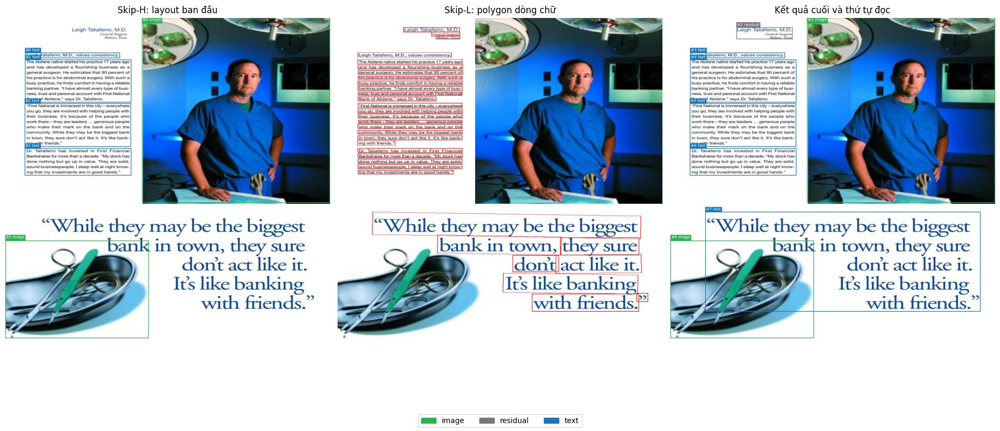

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B4,image,"(431, 0, 1024, 585)",B4,0,False,Dr.
1,2,recovered:1,residual,"(208, 31, 385, 68)",recovered:1,3,True,"Leigh Taliaferro,M.D.\nGeneral Surgeon\nAbilen..."
2,3,B0,text,"(62, 111, 361, 128)",B0,1,True,"Leigh Taliaferro, M.D., values consistency."
3,4,B1,text,"(62, 133, 397, 268)",B1,8,True,The Abilene native started his practice 17 yea...
4,5,B2,text,"(61, 271, 396, 408)",B2,8,True,"""First National is immersed in this city-every..."
5,6,B3,text,"(61, 413, 397, 499)",B3,5,False,Dr.Taliaferro has invested in First Financial\...
6,7,recovered:0,text,"(110, 614, 978, 929)",recovered:0,8,False,"""While they may be the biggest\nbank in town,\..."
7,8,B5,image,"(0, 705, 452, 1013)",B5,0,False,bank


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B0,B0,text,0.7425,0.7425,0.0000,insufficient_score_gain_or_confidence
1,KEEP,abstained,B1,B1,text,0.7503,0.7503,0.0000,insufficient_score_gain_or_confidence
2,KEEP,abstained,B2,B2,text,0.7517,0.7517,0.0000,insufficient_score_gain_or_confidence
3,RELABEL,accepted,recovered:0,recovered:0,text,0.7550,0.9581,0.2031,glm_residual_classification; body_text_positio...
4,KEEP,abstained,recovered:1,recovered:1,residual,0.7550,0.7550,0.0000,classification_spatial_mismatch:text; insuffic...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,normalized_json:removed_redundant_final_quote,text,ok,"While they may be the biggest\nbank in town, t...",
1,recovered:1,1,,text,ok,"Leigh Taliaferro, M.D.\nGeneral Surgeon\nAbile...",


### Nội dung tài liệu

Dr.

Leigh Taliaferro,M.D.
General Surgeon
Abilene,Texas

Leigh Taliaferro, M.D., values consistency.

The Abilene native started his practice 17 years ago
and has developed a flourishing business as a
general surgeon.He estimates that 9o percent of
hispracticeisforabdominal surgery.Withsucha
busy practice,he finds comfort in having a reliable
banking partner."I have almost every type of busi-
ness,trust and personal account withFirstNational
Bank of Abilene,”says Dr. Taliaferro.

"First National is immersed in this city-everywhere
you go,they are involved with helping people with
their business.lt's because of the people who
workthere-theyare leaders....generous people
who make their mark on the bank and on the
community. While they may be the biggest bank
in town,they sure don't act like it. lt's like bank-
ing with friends.

Dr.Taliaferro has invested in First Financial
Bankshares for more than a decade."My stock has
done nothing but go up in value. They are solid.
sound businesspeople.I sleep well at night know-
ing that my investments are in good hands."

"While they may be the biggest
bank in town,
they sure
act like it.
don't
It's like banking
”
with friends.

bank

### Crop và nội dung từng vùng

**1. B4 — image**

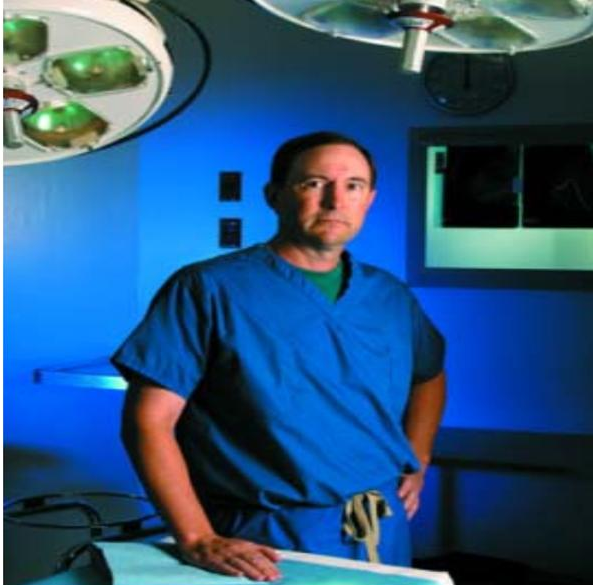

Dr.

**2. recovered:1 — residual**

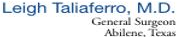

Leigh Taliaferro,M.D.
General Surgeon
Abilene,Texas

**3. B0 — text**

Leigh Taliaferro, M.D., values consistency.

**4. B1 — text**

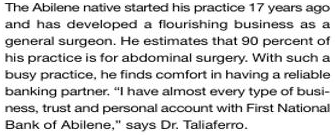

The Abilene native started his practice 17 years ago
and has developed a flourishing business as a
general surgeon.He estimates that 9o percent of
hispracticeisforabdominal surgery.Withsucha
busy practice,he finds comfort in having a reliable
banking partner."I have almost every type of busi-
ness,trust and personal account withFirstNational
Bank of Abilene,”says Dr. Taliaferro.

**5. B2 — text**

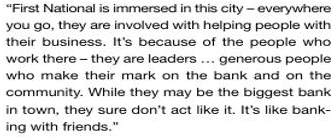

"First National is immersed in this city-everywhere
you go,they are involved with helping people with
their business.lt's because of the people who
workthere-theyare leaders....generous people
who make their mark on the bank and on the
community. While they may be the biggest bank
in town,they sure don't act like it. lt's like bank-
ing with friends.

**6. B3 — text**

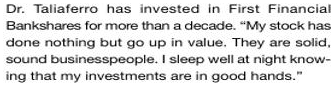

Dr.Taliaferro has invested in First Financial
Bankshares for more than a decade."My stock has
done nothing but go up in value. They are solid.
sound businesspeople.I sleep well at night know-
ing that my investments are in good hands."

**7. recovered:0 — text**

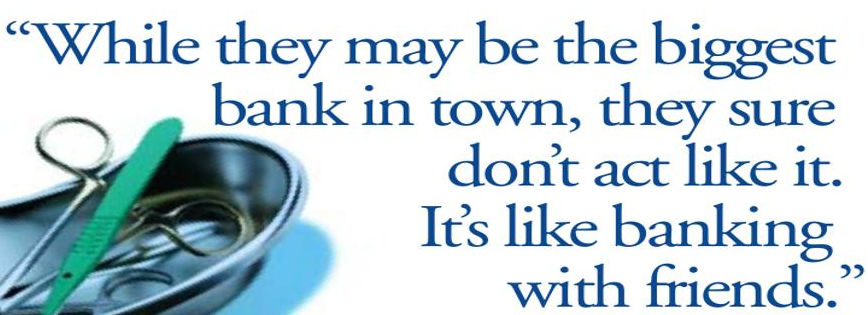

"While they may be the biggest
bank in town,
they sure
act like it.
don't
It's like banking
”
with friends.

**8. B5 — image**

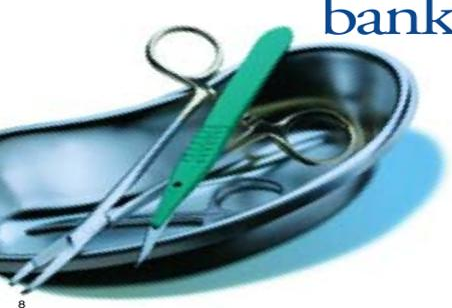

bank

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\1\page_0001


**2.png · trang 1 · 55.3s · Hoàn tất: 12 vùng; 10 lượt GLM.**

## Trang 1

**12 vùng · 131 dòng · 10 lượt suy luận GLM**

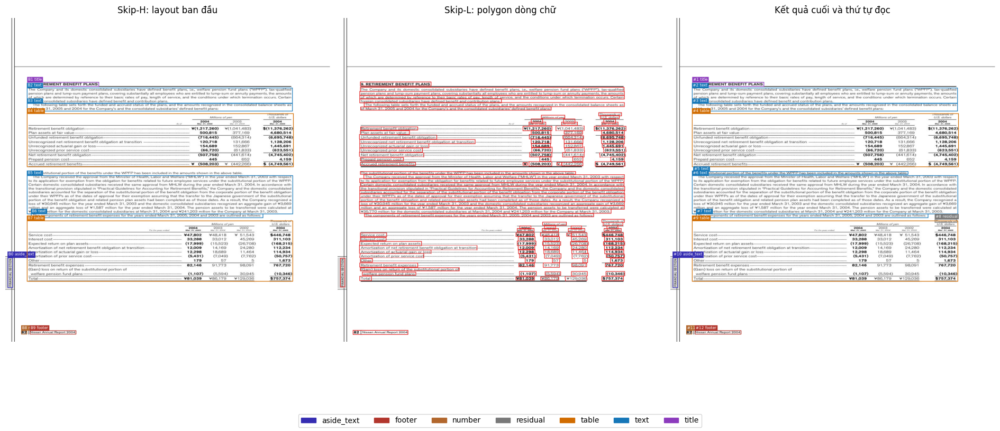

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B1,title,"(69, 204, 295, 218)",B1,1,False,9. RETIREMENT BENEFIT PLANS
1,2,B2,text,"(68, 222, 906, 271)",B2,4,True,The Company and its domestic consolidated subs...
2,3,B3,text,"(68, 271, 906, 296)",B3,2,True,The following table sets forth the funded and ...
3,4,B4,table,"(68, 303, 909, 472)",B4,47,False,"<table border=""1""><tr><td rowspan=""2""></td><td..."
4,5,recovered:1,text,"(72, 486, 750, 496)",recovered:1,1,False,The substitutional portion of the benefits und...
5,6,B5,text,"(68, 499, 907, 621)",B5,10,True,The Company received the approval from the Min...
6,7,B6,text,"(81, 620, 813, 633)",B6,1,True,The components of retirement benefit expenses ...
7,8,recovered:0,residual,"(834, 637, 904, 648)",recovered:0,1,True,Thousands of
8,9,B7,table,"(68, 642, 907, 834)",B7,62,False,"<table border=""1""><tr><td rowspan=""2""></td><td..."
9,10,B0,aside_text,"(7, 759, 23, 854)",B0,1,False,FINANCIAL SECTION


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B2,B2,text,0.7416,0.7416,0.0000,insufficient_score_gain_or_confidence
1,KEEP,abstained,B3,B3,text,0.7148,0.7201,0.0053,insufficient_score_gain_or_confidence
2,KEEP,abstained,B5,B5,text,0.7470,0.7470,0.0000,insufficient_score_gain_or_confidence
3,KEEP,abstained,B6,B6,text,0.7209,0.7209,0.0000,insufficient_score_gain_or_confidence
4,KEEP,abstained,recovered:0,recovered:0,residual,0.7550,0.7550,0.0000,classification_spatial_mismatch:text; classifi...
5,RELABEL,accepted,recovered:1,recovered:1,text,0.7550,0.9700,0.2150,glm_residual_classification; body_text_positio...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,verbatim target text,
1,recovered:1,1,,text,ok,The substitutional portion of the benefits und...,


... (2 outputs left out)

### Crop và nội dung từng vùng

**1. B1 — title**

9. RETIREMENT BENEFIT PLANS

**2. B2 — text**

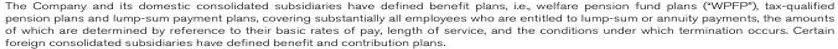

The Company and its domestic consolidated subsidiaries have defined benefit plans,i.e.welfare pension fund plans (WPFP),tax-qualfed
pension plans and lump-sum payment plans,covering substantially all employees who are entitled to lump-sum or annuity paymnents,the amounts
of which are deterrined by reference to their basic rates of pay,length of service,and the conditions under which termination occurs.Certain
foreign consolidated subsidiaries have defined benefit and contribution plans.

**3. B3 — text**

The following table sets forth the funded and accrued status of the plans,and the amounts recognized in the consolidated balance sheets as
of March 31.20o5 and2oo4for theCompany's and the consolidated subsidiaries’defined benefit plans:

**4. B4 — table**

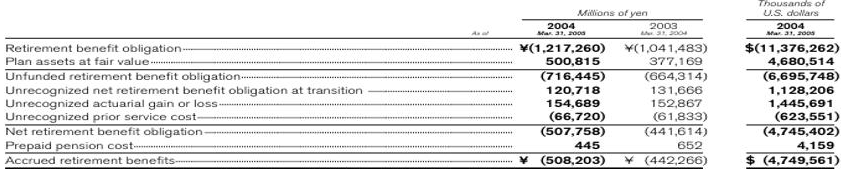

**5. recovered:1 — text**

The substitutional portion of the benefits under the WPFP has beenincluded in the amounts shownin the above table.

**6. B5 — text**

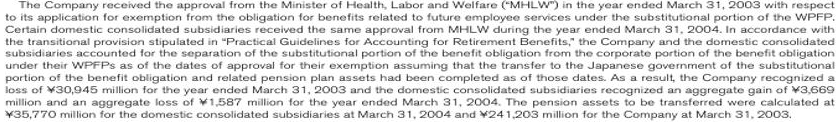

The Company received the approval from the Minister of Health,Labor and Welfare (MHLW")in the year ended March 31,2OO3 with respect
to its application for exemption from the obligation for benefits related to future employee services under the substitutional portion of the WPFP.
Certain domestic consolidated subsidiaries received the same approval from MHLW during the year endedMarch 31.2Oo4.In accordance with
the transitional provision stipulated in“Practical Guidelines for Accounting for Retirement Benefits,” the Company and the domestic consolidated
subsidiaries accounted far the separation of the substitutional portion of the benefit obligation frorm the corporate portion of the benefit obligation
under their WPFPs as of the dates of approval for their exemption assuming that the transfer to the Japanese government of the substitutional
portion of the benefit obligation and related pension plan assets had been completed as of those dates. As a result, the Company recognized a
loss of ￥30,945 million for the year ended March 31,2o03 and the domestic consolidated subsidiaries recognized an aggregate gain of ￥3.669
million and an aggregate loss of ￥1.587 million for the year ended March 31.20o4. The pension assets to be transferred were calculated at
￥35,77O million for the domestic consolidated subsidiaries at March 31,2OO4 and ￥241,2O3million for the Company at March 31,2003.

**7. B6 — text**

The components of retirement benefit expenses for the years ended March 31,20o5.20o4 and 2oo3 are outlined as follows:

**8. recovered:0 — residual**

Thousands of

**9. B7 — table**

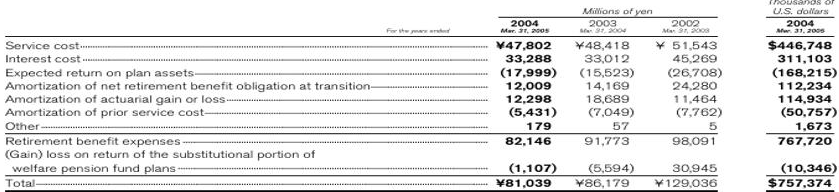

**10. B0 — aside_text**

FINANCIAL SECTION

**11. B8 — number**

82

**12. B9 — footer**

82Nissan Annual Report2004

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\2\page_0001


**3.png · trang 1 · 36.3s · Hoàn tất: 20 vùng; 18 lượt GLM.**

## Trang 1

**20 vùng · 50 dòng · 18 lượt suy luận GLM**

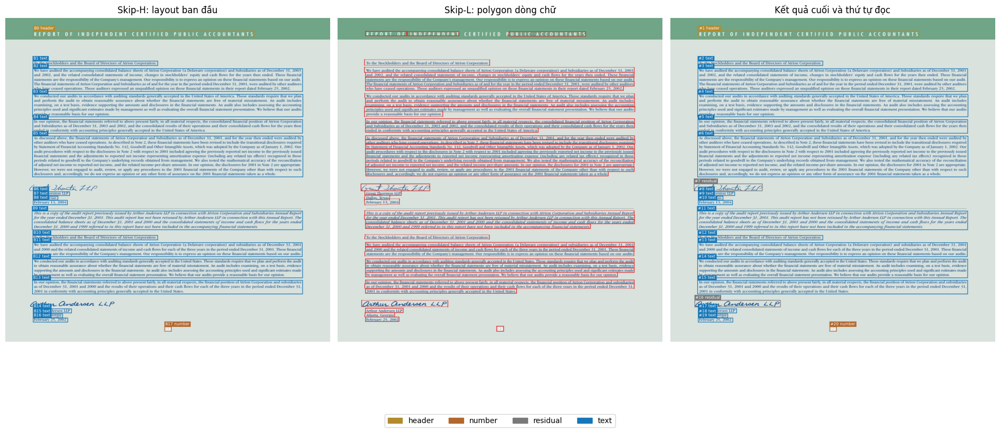

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B0,header,"(88, 42, 785, 63)",B0,3,False,REPORIOF\nINDEPENDENT\nUBLICACCOUNTANTS
1,2,B1,text,"(86, 137, 481, 152)",B1,1,True,TotheSockholdrandtheBoardofDirectorofAtioCorpn
2,3,B2,text,"(86, 161, 938, 234)",B2,5,True,WehaveauditetheaccomanconoliteblanceeofAtioCor...
3,4,B3,text,"(85, 242, 939, 314)",B3,5,True,We conducted ouraudits in accordancewith audit...
4,5,B4,text,"(86, 322, 938, 366)",B4,3,True,In our opinion.the financial statements referr...
5,6,B5,text,"(85, 374, 939, 504)",B5,9,True,"As discussed above,the financial statements of..."
6,7,recovered:1,residual,"(74, 525, 290, 548)",recovered:1,1,True,Gemt Ihomtn FLP
7,8,B6,text,"(87, 550, 203, 563)",B6,1,True,Grant Thornton LLP
8,9,B7,text,"(87, 564, 166, 577)",B7,1,True,"Dallas, Texas"
9,10,B8,text,"(87, 577, 196, 592)",B8,1,True,"February 13, 2004"


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B1,B1,text,0.6655,0.7002,0.0348,insufficient_score_gain_or_confidence
1,KEEP,abstained,B10,B10,text,0.7033,0.7233,0.0200,insufficient_score_gain_or_confidence
2,KEEP,abstained,B11,B11,text,0.7461,0.7461,0.0000,insufficient_score_gain_or_confidence
3,KEEP,abstained,B12,B12,text,0.7483,0.7483,0.0000,insufficient_score_gain_or_confidence
4,KEEP,abstained,B13,B13,text,0.7454,0.7454,0.0000,insufficient_score_gain_or_confidence
5,KEEP,abstained,B14,B14,text,0.7050,0.7250,0.0200,insufficient_score_gain_or_confidence
6,KEEP,abstained,B15,B15,text,0.6411,0.7250,0.0839,insufficient_score_gain_or_confidence
7,KEEP,abstained,B16,B16,text,0.6800,0.7250,0.0450,insufficient_score_gain_or_confidence
8,KEEP,abstained,B2,B2,text,0.7362,0.7362,0.0000,insufficient_score_gain_or_confidence
9,KEEP,abstained,B3,B3,text,0.7425,0.7425,0.0000,insufficient_score_gain_or_confidence


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,verbatim target text,
1,recovered:1,1,,text,ok,verbatim target text,


... (4 outputs left out)

REPORIOF
INDEPENDENT
UBLICACCOUNTANTS

**2. B1 — text**

TotheSockholdrandtheBoardofDirectorofAtioCorpn

**3. B2 — text**

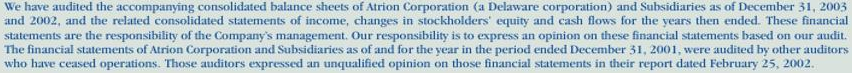

WehaveauditetheaccomanconoliteblanceeofAtioCororatioDlawarcorrationandubsdirieaofDcembe3
and 2002,and the related consolidated statements of income,changes in stockholdersequity and cash flows for the vears then ended. These financial
statements are theresponsibilityof the Company'smanagementOurresponsibility isto express an opinion on these financial statements based on ouraudi.
The financial statements of Atrion Corporation and Subsidiariesasof and forthevear in the period ended December 31201,wereaudited byotherauditors
who have ceased operations.Those auditors expressed an unqualified opinion on those financial statements in their report dated February 25,2002.

**4. B3 — text**

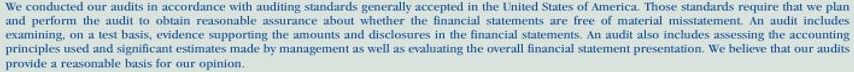

We conducted ouraudits in accordancewith auditingstandards generally accepted in the United States of AmericaThose standardsrequire that we plan
and perform the audit to obtain reasonable assurance about whether the financial statements are free of material misstatement. An audit includes
examiningon a test basis,evidence supporting the amounts and disclosures in the financial statements.An audit also includes assessing the accouning
principeuedansgicnstiatemadebmaagemetawllaevalutitovellfinaniasttmetresetatioebelivttuaui
provide a reasonable basis for our opinion.

**5. B4 — text**

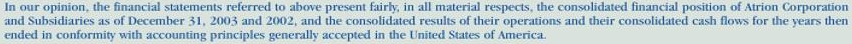

In our opinion.the financial statements referred to above present fairlyin al material respects,the consolidated financial position of Atrion Corporaion
and Subsidiaries as of December 31,2003 and 2002and the consolidated results of their operations and their consolidated cash flows for the years then
ended in conformity with accounting principles generally accepted in the United States of America

**6. B5 — text**

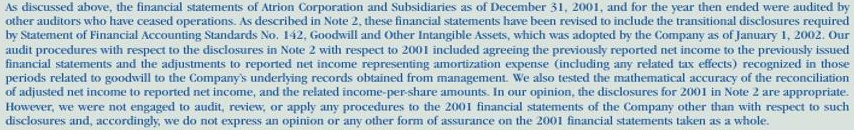

As discussed above,the financial statements of Atrion Corporation and Subsidiaries as of December 31,2001,and for the year then ended were audited by
otherauditorswho have ceased operationsAs described inNote 2.these financial statements have been revised to include the transitional disclosures reguired
by Statement of Financial Accounting Standards No.142,Goodwill and Other Intangible Assets,which was adopted by the Company as of January120.Our
audit procedures withrespect to the disclosures in Note 2 with respect to 20ol included agreeing thepreviously reported net income to the previously issued
financial statements and the adjustments to reported net income representing amortization expense (including anyrelated tax effects)recognized in those
periodsrelated to goodwill to the Companys underlying records obtained from management.We also tested the mathematical accuracy of the reconciliation
of adjusted netincome to reported net income,and the related income-per-share amounts.In our opinion,the disclosures for20ol in Note2 are appropriate.
However, we were not engaged to audit,review,or apply any procedures to the 2ooI financial statements of the Company other than with respect to such
disclosures and,accordinglywe do not express an opinion or any other form of assurance on the 20o1 financial statements taken as awhole

**7. recovered:1 — residual**

Gemt Ihomtn FLP

**8. B6 — text**

Grant Thornton LLP

**9. B7 — text**

Dallas, Texas

**10. B8 — text**

February 13, 2004

**11. B9 — text**

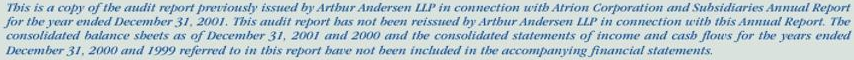

Tbisisacopyof tbeauditreportpreviously issuedbyArtburAndersenLLPinconnectionwitbAtrionCorporationand SubsidiariesAnnualReport
for tbe year ended December 3l.20ol.This audit report bas not been reissued by Artbur Andersen LLP in connection witb tbis Annual Report.Tbe
consolidated balance sbeets as of December 3l.20ol and 2ooo and tbe consolidated statements of income and casb flows for tbe vears ended
December3i.2ooo and1999 referred to in tbis report bave not been inchuded in tbe accompanyingfinancial statements

**12. B10 — text**

To the Stockholders and the Board of Directors of Atrion Corporation

**13. B11 — text**

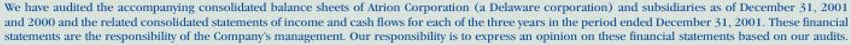

We have audited the accompanying consolidated balance sheets of Atrion Corporation (a Delaware corporation)and subsidiaries as of December 31,2001
and 2ooo and the related consolidated statements of income and cash flows for each of the three years in the period ended December 31,20o1.These financial
statementsaretheresponsibilityoftheCompanysmanagementOurresponsibilityistoexpressanopiniononthesefinancialstatements basedonouraudits.

**14. B12 — text**

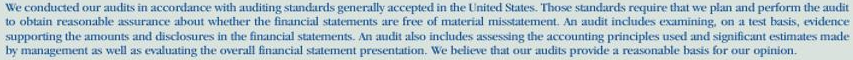

We conducted our auditsin accordancewith auditingstandardsgenerallyaccepted in the United States.Those standards require thatwe plan and perform the audit
to obtain reasonable assurance about whether the financial statements arefree of material misstatementAn audit includes examining,on a test hasis,evidence
supporting theamountsand disclosures in thefinancial statementsAnaudit alsoincludesassessingtheaccounting principlesused and significantestimatesmade
bymanagement as well asevaluating the overall financial statement presentation.We believe that ourauditsprovideareasonable basis forour opinion

**15. B13 — text**

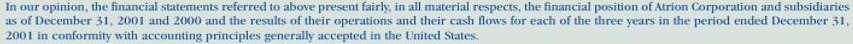

In our opinion,the financial statements referred to above presentfairlyin all material respectsthe financial position of Atrion Corporation and subsidiaries
as of December 31201 and 2000 and the results of their operations and their cash flows for each of the threeyears in the period ended December31.
2001 in conformity with accounting principles generally accepted in the United States.

**16. recovered:0 — residual**

Arthur Anderoen LhP

**17. B14 — text**

Arthur Andersen LLP

**18. B15 — text**

... (5 outputs left out)

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\3\page_0001


**4.png · trang 1 · 17.8s · Hoàn tất: 16 vùng; 12 lượt GLM.**

## Trang 1

**16 vùng · 50 dòng · 12 lượt suy luận GLM**

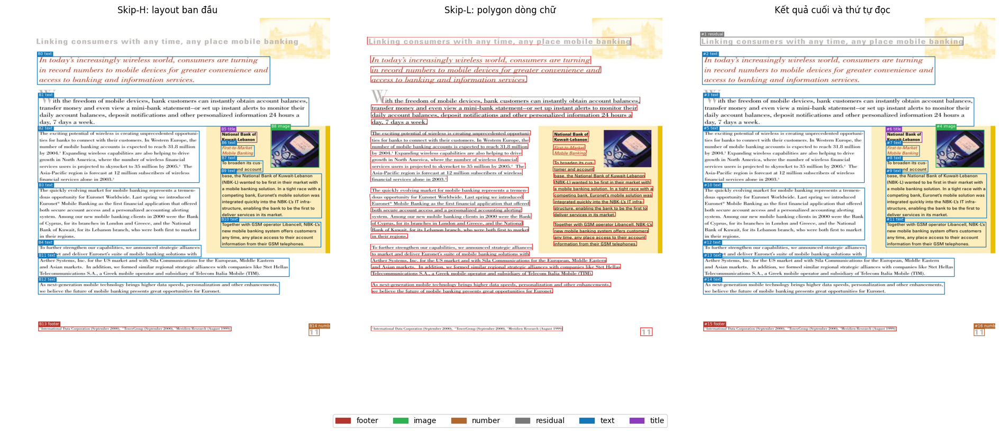

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,recovered:0,residual,"(94, 61, 924, 88)",recovered:0,1,True,"Linking consumers with any time,any place mobi..."
1,2,B0,text,"(100, 123, 835, 212)",B0,3,True,"In today's increasingly wireless world, consum..."
2,3,B1,text,"(103, 253, 958, 344)",B1,4,True,"ith the freedom of mobile devices,bank custome..."
3,4,B8,image,"(837, 355, 990, 474)",B8,0,False,NOKIA\n310\nCALL\n310
4,5,B2,text,"(102, 358, 612, 522)",B2,8,True,The exciting potential ofwireless is creating ...
5,6,B5,title,"(679, 361, 794, 395)",B5,2,False,National Bank of\nKuwait-Lebanon
6,7,B6,text,"(680, 404, 786, 439)",B6,2,True,First-to-Market\nMobile Banking
7,8,B7,text,"(680, 452, 813, 489)",B7,2,True,To broaden its cus-\ntomer and account
8,9,B9,text,"(679, 493, 998, 634)",B9,7,True,"base, the National Bank of Kuwait-Lebanon\n(NB..."
9,10,B3,text,"(103, 538, 613, 703)",B3,8,True,Thequicklyevolvingmarketformobilebankingrepres...


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B0,B0,text,0.7446,0.7446,0.0000,insufficient_score_gain_or_confidence
1,KEEP,abstained,B1,B1,text,0.7416,0.7416,0.0000,insufficient_score_gain_or_confidence
2,KEEP,abstained,B10,B10,text,0.7488,0.7488,0.0000,insufficient_score_gain_or_confidence
3,KEEP,abstained,B11,B11,text,0.7467,0.7467,0.0000,insufficient_score_gain_or_confidence
4,KEEP,abstained,B2,B2,text,0.7519,0.7519,0.0000,insufficient_score_gain_or_confidence
5,KEEP,abstained,B3,B3,text,0.7497,0.7497,0.0000,insufficient_score_gain_or_confidence
6,KEEP,abstained,B4,B4,text,0.7205,0.7234,0.0029,insufficient_score_gain_or_confidence
7,KEEP,abstained,B6,B6,text,0.7175,0.7250,0.0075,insufficient_score_gain_or_confidence
8,KEEP,abstained,B7,B7,text,0.7282,0.7282,0.0000,insufficient_score_gain_or_confidence
9,KEEP,abstained,B9,B9,text,0.7479,0.7479,0.0000,insufficient_score_gain_or_confidence


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,"Linking consumers with any time,any place mobi...",


... (2 outputs left out)

### Crop và nội dung từng vùng

**1. recovered:0 — residual**

Linking consumers with any time,any place mobile banking

**2. B0 — text**

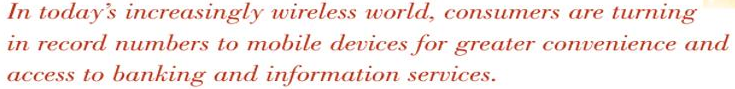

In today's increasingly wireless world, consumers are turning
in record numbers to mobile devices for greaterconvenience and
access to banking and information services.

**3. B1 — text**

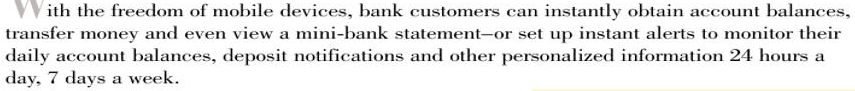

ith the freedom of mobile devices,bank customers can instantly obtain accountbalances,
transfermoneyandeven view a mini-bank statement-orsetup instantalerts to monitortheir
daily account balances,depositnotifications and other personalized information 24 hours a
day,7 days a week.

**4. B8 — image**

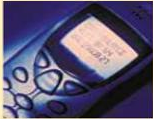

NOKIA
310
CALL
310

**5. B2 — text**

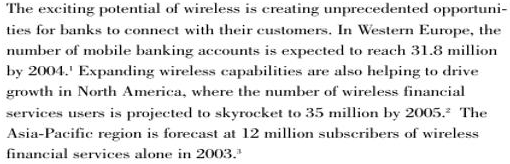

The exciting potential ofwireless is creating unprecedented opportuni-
tiesforbankstoconnectwiththeircustomers.InWesternEurope,the
numberofmobile banking accounts is expected to reach 31.8million
by2004.Expandingwirelesscapabilitiesarealsohelpingtodrive
growthinNorthAmerica,wherethenumberofwirelessfinancial
services users is projected to skyrocket to35million by 2005.²The
AsiaPacificregionisforecastat12millionsubscribersofwireless
financial services alone in 2003.3

**6. B5 — title**

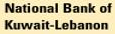

National Bank of
Kuwait-Lebanon

**7. B6 — text**

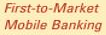

First-to-Market
Mobile Banking

**8. B7 — text**

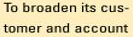

To broaden its cus-
tomer and account

**9. B9 — text**

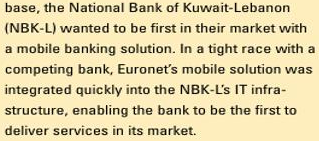

base, the National Bank of Kuwait-Lebanon
(NBK-L)wanted to be first in their market with
a mobile banking solution.In a tight race with a
competing bank, Euronet's mobile solution was
integrated quickly into the NBK-L's IT infra-
structure,enabling the bank to be the first to
deliver services in its market.

**10. B3 — text**

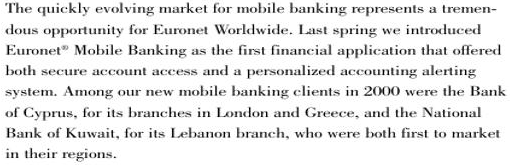

Thequicklyevolvingmarketformobilebankingrepresentsa tremen-
dousopportunityforEuronetWorldwide.Last spring we introduced
EuronetMobileBankingasthefirstfinancialapplicationthatoffered
both secure accountaccess and a personalized accounting alerting
system. Among ournew mobile bankingclients in 2000 were the Bank
ofCyprus,foritsbranchesinLondonandGreece,andtheNational
Bank of Kuwait,for its Lebanon branch,who were both first to market
in theirregions.

**11. B10 — text**

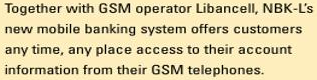

Together with GSM operator Libancell,NBK-L's
new mobile banking system offers customers
any time,any place access to their account
information from their GSM telephones.

**12. B4 — text**

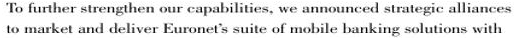

To furtherstrengthenourcapabilities,we announcedstrategicalliances
tomarketanddeliverEuronet’ssuiteofmobilebankingsolutionswith

**13. B11 — text**

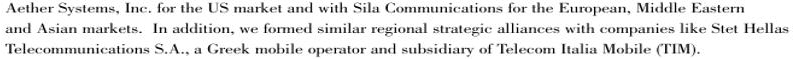

AetherSystems,Inc.fortheUSmarketandwithSilaCommunicationsfortheEuropean,MiddleEastern
andAsianmarkets.Inaddition,weformedsimilarregionalstrategicalliances withcompanieslikeStetHellas
TelecommunicationsS.A.,aGreekmobileoperatorandsubsidiaryofTelecomItaliaMobile(TIM).

**14. B12 — text**

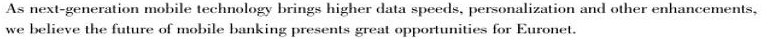

Asnext-generationmobiletechnologybringshigherdataspeeds,personalizationandotherenhancements,
webelievethe futureofmobilebanking presents greatopportunitiesforEuronet.

**15. B13 — footer**

1InternationalDataCorporation(September200O),TowerGroup(September200O),MeridienResearch(August1999)

**16. B14 — number**

11

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\4\page_0001


**5.png · trang 1 · 106.7s · Hoàn tất: 18 vùng; 16 lượt GLM.**

## Trang 1

**18 vùng · 219 dòng · 16 lượt suy luận GLM**

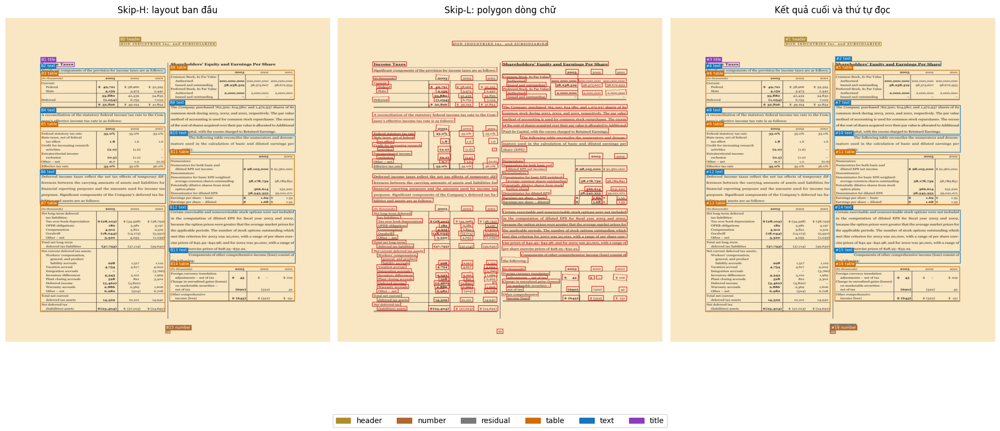

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B0,header,"(360, 77, 665, 90)",B0,1,False,HON INDUSTRIES INC.AND SUBSIDIARIES
1,2,recovered:1,text,"(520, 138, 854, 153)",recovered:1,1,False,Shareholders' Equity and Earnings Per Share
2,3,B1,title,"(111, 141, 218, 156)",B1,1,False,Income Taxes
3,4,B2,text,"(110, 161, 504, 176)",B2,1,True,Significantcomponentsoftheprovision for income...
4,5,B8,table,"(518, 166, 912, 260)",B8,17,False,<table><thead><tr><th></th><th>2003</th><th>20...
5,6,B3,table,"(111, 185, 504, 285)",B3,23,False,"<table><thead><tr><th colspan=""2"">(In thousand..."
6,7,B9,text,"(517, 277, 915, 369)",B9,5,True,The Company purchased 762.30o: 614.58o: and 1....
7,8,B4,text,"(110, 301, 504, 335)",B4,2,True,A reconciliation of thestatutory federal incom...
8,9,B5,table,"(110, 345, 504, 479)",B5,29,False,"<table border=""1""><tr><td></td><td>2003</td><t..."
9,10,B10,text,"(517, 373, 915, 426)",B10,3,True,The following table reconciles the numerators ...


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B10,B10,text,0.7282,0.7282,0.0000,insufficient_score_gain_or_confidence
1,KEEP,abstained,B12,B12,text,0.7407,0.7407,0.0000,insufficient_score_gain_or_confidence
2,KEEP,abstained,B13,B13,text,0.7175,0.7250,0.0075,insufficient_score_gain_or_confidence
3,KEEP,abstained,B2,B2,text,0.6675,0.7250,0.0575,insufficient_score_gain_or_confidence
4,KEEP,abstained,B4,B4,text,0.7175,0.7240,0.0065,insufficient_score_gain_or_confidence
5,KEEP,abstained,B6,B6,text,0.7400,0.7400,0.0000,insufficient_score_gain_or_confidence
6,KEEP,abstained,B9,B9,text,0.7389,0.7389,0.0000,insufficient_score_gain_or_confidence
7,KEEP,abstained,recovered:0,recovered:0,residual,0.7550,0.7550,0.0000,classification_spatial_mismatch:text; classifi...
8,RELABEL,accepted,recovered:1,recovered:1,text,0.7550,0.9700,0.2150,glm_residual_classification; body_text_positio...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,verbatim target text,
1,recovered:1,1,,text,ok,Shareholders' Equity and Earnings Per Share,


... (8 outputs left out)

Income Taxes

**4. B2 — text**

Significantcomponentsoftheprovision for income taxesare as follows:

**5. B8 — table**

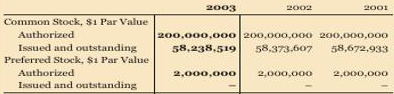

,2003,2002,2001
"Common Stock, $1 Par Value",,,
Authorized Issued and outstanding,"200,000,00058,238,519","200,000,000","200,000,000"
"Preferred Stock, $1 Par Value",,"58,373,607","58,672,933"
Authorized Issued and outstanding,"2,000,000","2,000,000","2,000,000"
,-,-,-


**6. B3 — table**

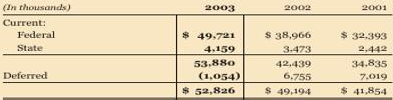

**7. B9 — text**

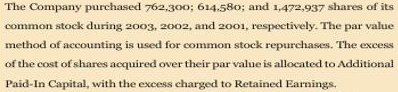

The Company purchased 762.30o: 614.58o: and 1.472.937 shares of its
common stock during 2oo3, 20o2,and 2oo1,respectively.The par value
method of accounting is used for common stock repurchases.The excess
ofthecostofsharesacquiredovertheirparvalueisallocatedtoAdditional
Paid-ICaaltescdoReEring

**8. B4 — text**

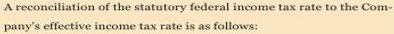

A reconciliation of thestatutory federal income taxrate to the Com-
pany's effective income tax rate is as follows:

**9. B5 — table**

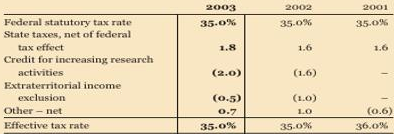

,2003,2002,2001
Federal statutory tax rate,35.0%,35.0%,35.0%
"State taxes, net of federal tax effect",1.8,1.6,1.6
Credit for increasing research activities,(2.0),(1.6),-
Extraterritorial income exclusion,(0.5),(1.0),-
Other-net,0.7,1.0,(0.6)
Effective tax rate,35.0%,35.0%,36.0%


**10. B10 — text**

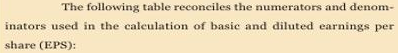

The following table reconciles the numerators and denom-
inators used in the caleulation of basic and diluted earnings per
share (EPS):

**11. B11 — table**

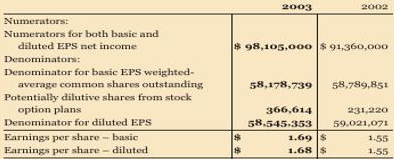

,2003,2002
Numerators:,,
Numerators for both basic and diluted EPS net income,"$98,105,000","$91,360,000"
Denominators:,,
Denominator for basic EPS weighted-average common shares outstanding,"58,178,739","58,789,851"
Potentially dilutive shares from stock option plans,"366,614","231,220"
Denominator for diluted EPS,"58,545,353","59,021,071"
Earnings per share-basic,$1.69,$1.55
Earnings per share-diluted,$1.68,$1.55


**12. B6 — text**

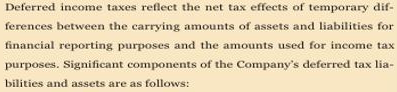

Deferred income taxes reflect the net tax effects of temporary dif
ferences between the carrying amounts of assets and liabilities for
financial reporting purposes and the amounts used for income tax
purposes.igificatcomonetoftheCompanydeferedal
bilities and assets are as follows:

**13. B7 — table**

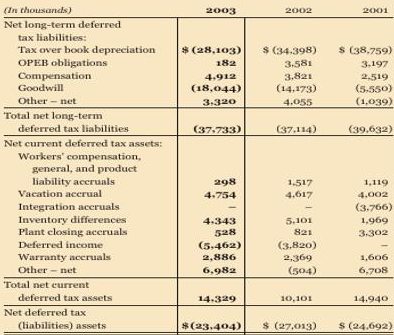

(In thousands),2003,2002,2001
Net long-term deferred tax liabilities:,,,
Tax over book depreciation,"$(28,103)","$ (34,398)","$ (38,759)"
OPEB obligations,182,"3,581","3,197"
Compensation,"4,912","3,821","2,519"
Goodwill,"(18,044)","(14,173)","(5,530)"
Other – net,"3,320","4,055","(1,039)"
Total net long-term deferred tax liabilities,"(37,733)","(37,114)","(39,632)"
Net current deferred tax assets:,,,
"Workers’ compensation, general, and product liability accruals",298,"1,517","1,119"
Vacation accrual,"4,754","4,617","4,002"


**14. B12 — text**

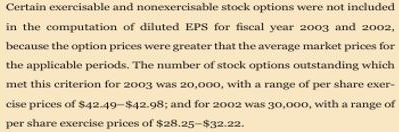

Certain exercisable and nonexercisable stock options were not included
in the computation of diluted EPS for fiscal year 2oo3 and 2002,
because the option prices were greater that the average market prices for
the applicable periods.The number of stock options outstanding which
met this criterion for 2oo3 was 20.o0o,with a range of per share exer-
cise prices of $42.49-$42.98; and for 2002 was 30,000,with a range of
per share exercise prices of $28.25-$32.22.

**15. B13 — text**

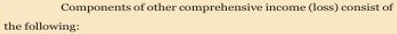

Components ofother comprehensive income (loss)consist of
the following:

**16. B14 — table**

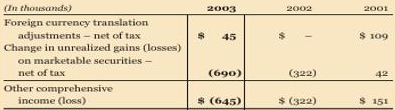

(In thousands),2003,2002,2001
Foreign currency translation adjustments - net of tax,$45,$-,$109
Change in unrealized gains (losses) on marketable securities - net of tax,(690),(322),42
Other comprehensive income (loss),$(645),$(322),$151


**17. recovered:0 — residual**

49

**18. B15 — number**

49

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\5\page_0001


**6.png · trang 1 · 107.5s · Hoàn tất: 12 vùng; 8 lượt GLM.**

## Trang 1

**12 vùng · 116 dòng · 8 lượt suy luận GLM**

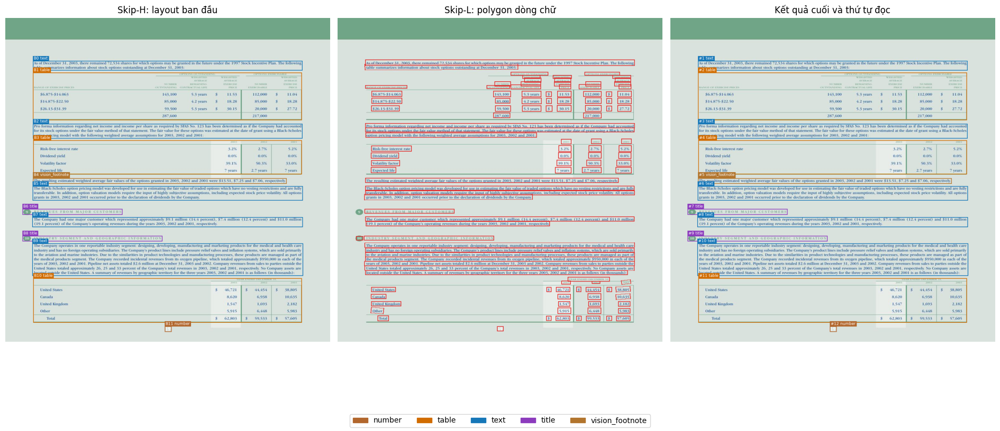

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B0,text,"(87, 137, 937, 167)",B0,2,True,AsofDeembr12teremaie73haresorwhicotiomabranted...
1,2,B1,table,"(87, 174, 935, 324)",B1,45,False,"<table border=""1""><tr><td rowspan=""3"">RANGE OF..."
2,3,B2,text,"(87, 336, 937, 382)",B2,3,True,Pro forma information regarding net income and...
3,4,B3,table,"(88, 388, 935, 495)",B3,19,False,"<table border=""1""><tr><td></td><td>2003</td><t..."
4,5,B4,vision_footnote,"(87, 508, 887, 525)",B4,1,False,The resulting estimated weighted average fair ...
5,6,B5,text,"(86, 533, 938, 578)",B5,3,True,The Black-Scholes option pricing model was dev...
6,7,B6,title,"(54, 605, 369, 623)",B6,1,False,REVENUES FROM MAIOR CUSTOMERS
7,8,B7,text,"(85, 631, 938, 662)",B7,2,True,The Company had one major customer which repre...
8,9,B8,title,"(54, 690, 495, 707)",B8,2,False,INDUSTRY SEGMENT AND GEOGRAPHICINFORMATION\n10
9,10,B9,text,"(85, 714, 939, 816)",B9,7,True,The Company operates in one reportable industr...


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B0,B0,text,0.7153,0.7153,0.0,content_loss_or_hallucination; insufficient_sc...
1,KEEP,abstained,B2,B2,text,0.7383,0.7383,0.0,insufficient_score_gain_or_confidence
2,KEEP,abstained,B5,B5,text,0.7458,0.7458,0.0,insufficient_score_gain_or_confidence
3,KEEP,abstained,B7,B7,text,0.7300,0.7300,0.0,insufficient_score_gain_or_confidence
4,KEEP,abstained,B9,B9,text,0.7461,0.7461,0.0,insufficient_score_gain_or_confidence


### Nội dung tài liệu

AsofDeembr12teremaie73haresorwhicotiomabrantedintefutureundt1tockIcntivlaThllowin
tablesumareirtioaouockiutntDcembr

<table><tbody><tr><td rowspan="3">RANGE OF EXERCISE PRICES</td><td colspan="3">OPTIONS OUTSTANDING</td><td colspan="2">OPTIONS EXERCISABLE</td></tr><tr><td rowspan="2">NUMBER OUTSTANDING</td><td rowspan="2">WEIGHTED AVERAGE REMAINING CONTRACTUAL LIFE</td><td rowspan="2">WEIGHTED AVERAGE EXERCISLE PRICE</td><td rowspan="2">NUMBER EXERCISABLE</td><td rowspan="2">WEIGHTED AVERAGE EXERCISLE PRICE</td></tr><tr></tr><tr><td>$6.875-$14.063</td><td>143,100</td><td>5.3 years</td><td>$11.53</td><td>112,000</td><td>$11.04</td></tr><tr><td>$14.875-$22.50</td><td>85,000</td><td>4.2 years</td><td>$18.28</td><td>85,000</td><td>$18.28</td></tr><tr><td>$26.13-$31.39</td><td>59,500</td><td>5.3 years</td><td>$30.15</td><td>20,000</td><td>$27.72</td></tr><tr><td></td><td>287,600</td><td></td><td></td><td>217,000</td><td></td></tr></tbody></table>

Pro forma information regarding net income and income per share as required bv SFAs No.123 has been determined as if the Company had accounted
for its stock options under the fair value method of that statement.The fair value for these options was estimated at the date of grant using a Black-Scholes
option pricing model with the following weighted average assumptions for 2003,2002 and 2001

<table><tbody><tr><td></td><td>2003</td><td>2002</td><td>2001</td></tr><tr><td>Risk-free interest rate</td><td>3.2%</td><td>2.7%</td><td>5.2%</td></tr><tr><td>Dividend yield</td><td>0.0%</td><td>0.0%</td><td>0.0%</td></tr><tr><td>Volatility factor</td><td>39.1%</td><td>50.3%</td><td>33.0%</td></tr><tr><td>Expected life</td><td>7 years</td><td>2.7 years</td><td>7 years</td></tr></tbody></table>

The resulting estimated weighted average fair valuesof the options granted in 2003.2002 and 2001 were $13.51.$7.25 and $7.06,respectively.

The Black-Scholes option pricing model was developed for use in estimating the fair value of traded options which have no vesting restrictions and are fully
transferable. In addition,option valuation models require the input of highly subjective assumptions,including expected stock price volatility.All options
grantsin200302and2ccurrediortothdeclaatioofdividendbtheman

# REVENUES FROM MAIOR CUSTOMERS

The Company had one major customer which represented approximately $9.1million (14.4 percent),$7.4million (12.4 percent)and $11.0million
(19.1percent)of the Company's operating revenues during the years 2003,2002 and 2001,respectivel

# INDUSTRY SEGMENT AND GEOGRAPHICINFORMATION
10

The Company operates in one reportable industry segment: designingdevelopingmanufacturing and marketing products for the medical and health care
industry and has no foreign operating subsidiaries.The Companys product lines include pressure relief valves and inflation systems,which are sold primarily
to the aviation and marine industries.Due to the similarities in product technologies and manufacturing processes,these products are managed as part of
the medical products segment. The Company recorded incidental revenues from its oxygen pipeline,which totaled approximately $950,00o in eachofthe
yearsof20032002and2001.Pipelinenet assetstotaled $2.6millionat December312003and2002.Companyrevenuesfromsalestopartiesoutsidethe
United States totaled approximately 26,25 and 33 percent of the Companys total revenues in20032002 and2001,respectivelyNo Company asesare
located outside the United States.A summary of revenues by geographic territory for the three years 2003.2002 and 200l is as follows (in thousands):

<table><tbody><tr><td rowspan="2"></td><td colspan="3">YEAR ENDED DECEMBER 31</td></tr><tr><td>2003</td><td>2002</td><td>2001</td></tr><tr><td>United States</td><td>46,721</td><td>44,454</td><td>38,805</td></tr><tr><td>Canada</td><td>8,620</td><td>6,938</td><td>10,635</td></tr><tr><td>United Kingdom</td><td>1,547</td><td>1,693</td><td>2,182</td></tr><tr><td>Other</td><td>5,915</td><td>6,448</td><td>5,983</td></tr><tr><td>Total</td><td>62,803</td><td>59,533</td><td>57,605</td></tr></tbody></table>

19

### Crop và nội dung từng vùng

**1. B0 — text**

AsofDeembr12teremaie73haresorwhicotiomabrantedintefutureundt1tockIcntivlaThllowin
tablesumareirtioaouockiutntDcembr

**2. B1 — table**

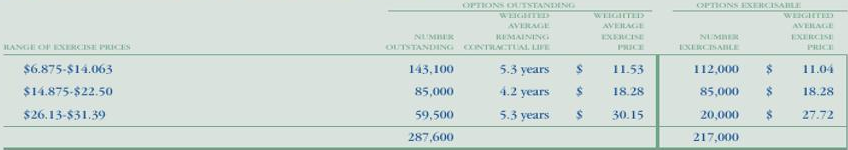

**3. B2 — text**

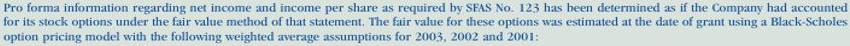

Pro forma information regarding net income and income per share as required bv SFAs No.123 has been determined as if the Company had accounted
for its stock options under the fair value method of that statement.The fair value for these options was estimated at the date of grant using a Black-Scholes
option pricing model with the following weighted average assumptions for 2003,2002 and 2001

**4. B3 — table**

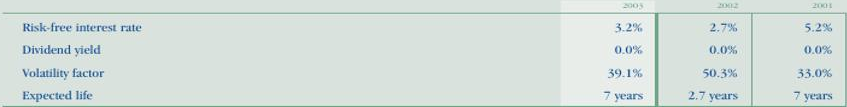

,2003,2002,2001
Risk-free interest rate,3.2%,2.7%,5.2%
Dividend yield,0.0%,0.0%,0.0%
Volatility factor,39.1%,50.3%,33.0%
Expected life,7 years,2.7 years,7 years


**5. B4 — vision_footnote**

The resulting estimated weighted average fair valuesof the options granted in 2003.2002 and 2001 were $13.51.$7.25 and $7.06,respectively.

**6. B5 — text**

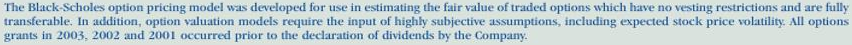

The Black-Scholes option pricing model was developed for use in estimating the fair value of traded options which have no vesting restrictions and are fully
transferable. In addition,option valuation models require the input of highly subjective assumptions,including expected stock price volatility.All options
grantsin200302and2ccurrediortothdeclaatioofdividendbtheman

**7. B6 — title**

REVENUES FROM MAIOR CUSTOMERS

**8. B7 — text**

The Company had one major customer which represented approximately $9.1million (14.4 percent),$7.4million (12.4 percent)and $11.0million
(19.1percent)of the Company's operating revenues during the years 2003,2002 and 2001,respectivel

**9. B8 — title**

INDUSTRY SEGMENT AND GEOGRAPHICINFORMATION
10

**10. B9 — text**

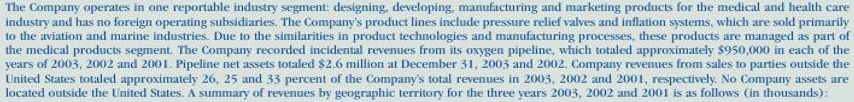

The Company operates in one reportable industry segment: designingdevelopingmanufacturing and marketing products for the medical and health care
industry and has no foreign operating subsidiaries.The Companys product lines include pressure relief valves and inflation systems,which are sold primarily
to the aviation and marine industries.Due to the similarities in product technologies and manufacturing processes,these products are managed as part of
the medical products segment. The Company recorded incidental revenues from its oxygen pipeline,which totaled approximately $950,00o in eachofthe
yearsof20032002and2001.Pipelinenet assetstotaled $2.6millionat December312003and2002.Companyrevenuesfromsalestopartiesoutsidethe
United States totaled approximately 26,25 and 33 percent of the Companys total revenues in20032002 and2001,respectivelyNo Company asesare
located outside the United States.A summary of revenues by geographic territory for the three years 2003.2002 and 200l is as follows (in thousands):

**11. B10 — table**

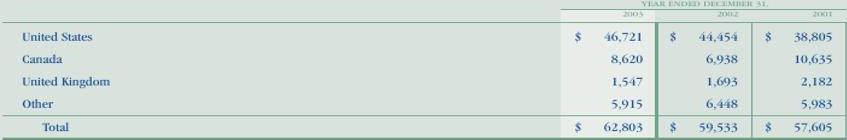

**12. B11 — number**

19

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\6\page_0001


**7.png · trang 1 · 18.1s · Hoàn tất: 17 vùng; 13 lượt GLM.**

## Trang 1

**17 vùng · 65 dòng · 13 lượt suy luận GLM**

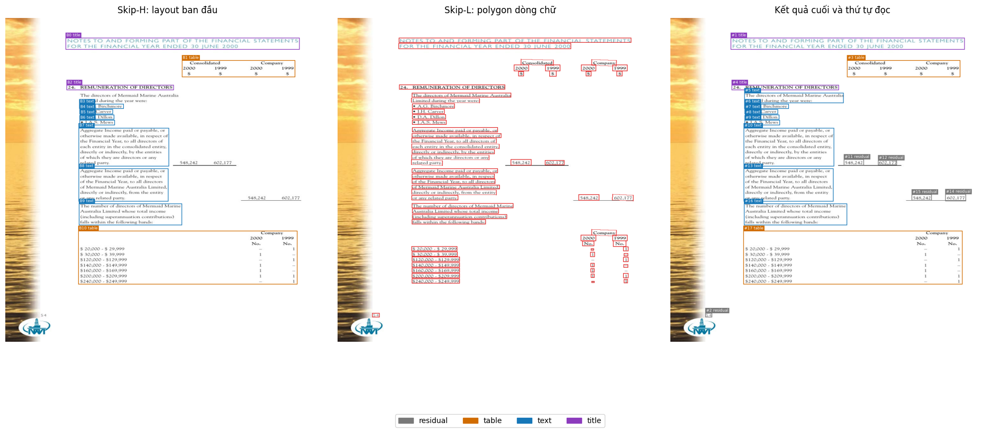

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B0,title,"(190, 64, 928, 101)",B0,2,False,NOTESTOANDFORMINGPARTOFTHEFINANCIALSTATEMENTS\...
1,2,recovered:0,residual,"(110, 934, 131, 947)",recovered:0,1,True,54
2,3,B1,table,"(557, 135, 914, 188)",B1,10,False,"<table border=""1""><tr><td colspan=""2"">Consolid..."
3,4,B2,title,"(193, 213, 531, 229)",B2,1,False,24.REMUNERATIONOFDIRECTORS
4,5,recovered:5,text,"(233, 238, 546, 270)",recovered:5,2,False,The directorsofMermaidMarineAustralia\nLimited...
5,6,B3,text,"(233, 273, 373, 288)",B3,1,True,A.G.Birchmore
6,7,B4,text,"(234, 290, 339, 305)",B4,1,True,J.H.Carver
7,8,B5,text,"(235, 307, 343, 322)",B5,1,True,D.A.Dillon
8,9,B6,text,"(234, 324, 345, 340)",B6,1,False,J.A.S.Mews
9,10,B7,text,"(231, 349, 516, 470)",B7,7,True,"Aggregate Income paidor payable,or\notherwise ..."


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B3,B3,text,0.7300,0.7300,0.000,insufficient_score_gain_or_confidence
1,KEEP,abstained,B4,B4,text,0.7300,0.7300,0.000,insufficient_score_gain_or_confidence
2,KEEP,abstained,B5,B5,text,0.7300,0.7300,0.000,insufficient_score_gain_or_confidence
3,KEEP,abstained,B7,B7,text,0.7479,0.7479,0.000,insufficient_score_gain_or_confidence
4,KEEP,abstained,B9,B9,text,0.7488,0.7488,0.000,insufficient_score_gain_or_confidence
5,KEEP,abstained,recovered:0,recovered:0,residual,0.7550,0.7550,0.000,classification_spatial_mismatch:text; classifi...
6,KEEP,abstained,recovered:1,recovered:1,residual,0.7550,0.7550,0.000,classification_spatial_mismatch:text; insuffic...
7,KEEP,abstained,recovered:2,recovered:2,residual,0.7550,0.7550,0.000,classification_spatial_mismatch:text; insuffic...
8,KEEP,abstained,recovered:3,recovered:3,residual,0.7550,0.7550,0.000,classification_spatial_mismatch:text; insuffic...
9,KEEP,abstained,recovered:4,recovered:4,residual,0.7550,0.7550,0.000,classification_spatial_mismatch:text; insuffic...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,verbatim target text,
1,recovered:1,1,,text,ok,"602,177",
2,recovered:2,1,,text,ok,"548,242",
3,recovered:3,1,,text,ok,"602,177",
4,recovered:4,1,,text,ok,"548,242",
5,recovered:5,1,,text,ok,The directors of Mermaid Marine Australia\nLim...,


### Nội dung tài liệu

# NOTESTOANDFORMINGPARTOFTHEFINANCIALSTATEMENTS
FORTHEFINANCIALYEARENDED3OJUNE2OOO

54

<table><tbody><tr><td colspan="2">Consolidated</td><td colspan="2">Company</td></tr><tr><td>2000</td><td>1999</td><td>2000</td><td>1999</td></tr><tr><td>$</td><td>$</td><td>$</td><td>$</td></tr></tbody></table>

# 24.REMUNERATIONOFDIRECTORS

The directorsofMermaidMarineAustralia
Limited during the year were:

A.G.Birchmore

J.H.Carver

D.A.Dillon

J.A.S.Mews

Aggregate Income paidor payable,or
otherwise made available,in respectof
the Financial Year,to all directors of
each entity in the consolidated entity.
directlyorindirectly,bytheentities
ofwhichtheyaredirectorsorany
related party.

548,242

602,177

Aggregate Income paidor payable,or
otherwisemadeavailable,inrespect
oftheFinancialYear,toalldirectors
ofMermaidMarineAustraliaLimited,
directlyor indirectly,fromthe entity
or any related party.

602,177

548,242

ThenumberofdirectorsofMermaidMarine
AustraliaLimited whose total income
(including superannuation contributions)
fallswithin thefollowingbands:

<table><tbody><tr><td rowspan="2"></td><td colspan="2">Company</td></tr><tr><td>2000 No.</td><td>1999 No.</td></tr><tr><td>$20,000- $29,999</td><td>-</td><td>1</td></tr><tr><td>$30,000- $39,999</td><td>1</td><td>-</td></tr><tr><td>$120,000- $129,999</td><td>-</td><td>1</td></tr><tr><td>$140,000- $149,999</td><td>1</td><td>-</td></tr><tr><td>$160,000- $169,999</td><td>1</td><td>-</td></tr><tr><td>$200,000- $209,999</td><td>1</td><td>1</td></tr><tr><td>$240,000- $249,999</td><td>-</td><td>1</td></tr></tbody></table>

### Crop và nội dung từng vùng

**1. B0 — title**

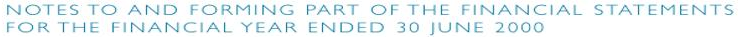

NOTESTOANDFORMINGPARTOFTHEFINANCIALSTATEMENTS
FORTHEFINANCIALYEARENDED3OJUNE2OOO

**2. recovered:0 — residual**

54

**3. B1 — table**

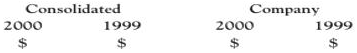

**4. B2 — title**

24.REMUNERATIONOFDIRECTORS

**5. recovered:5 — text**

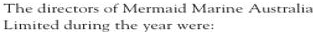

The directorsofMermaidMarineAustralia
Limited during the year were:

**6. B3 — text**

A.G.Birchmore

**7. B4 — text**

J.H.Carver

**8. B5 — text**

D.A.Dillon

**9. B6 — text**

J.A.S.Mews

**10. B7 — text**

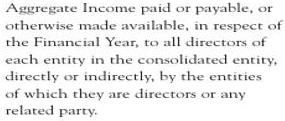

Aggregate Income paidor payable,or
otherwise made available,in respectof
the Financial Year,to all directors of
each entity in the consolidated entity.
directlyorindirectly,bytheentities
ofwhichtheyaredirectorsorany
related party.

**11. recovered:4 — residual**

548,242

**12. recovered:3 — residual**

602,177

**13. B8 — text**

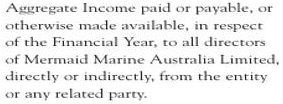

Aggregate Income paidor payable,or
otherwisemadeavailable,inrespect
oftheFinancialYear,toalldirectors
ofMermaidMarineAustraliaLimited,
directlyor indirectly,fromthe entity
or any related party.

**14. recovered:1 — residual**

602,177

**15. recovered:2 — residual**

548,242

**16. B9 — text**

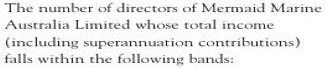

ThenumberofdirectorsofMermaidMarine
AustraliaLimited whose total income
(including superannuation contributions)
fallswithin thefollowingbands:

**17. B10 — table**

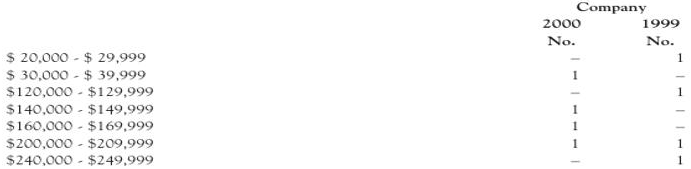

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\7\page_0001


**8.png · trang 1 · 44.6s · Hoàn tất: 12 vùng; 9 lượt GLM.**

## Trang 1

**12 vùng · 80 dòng · 9 lượt suy luận GLM**

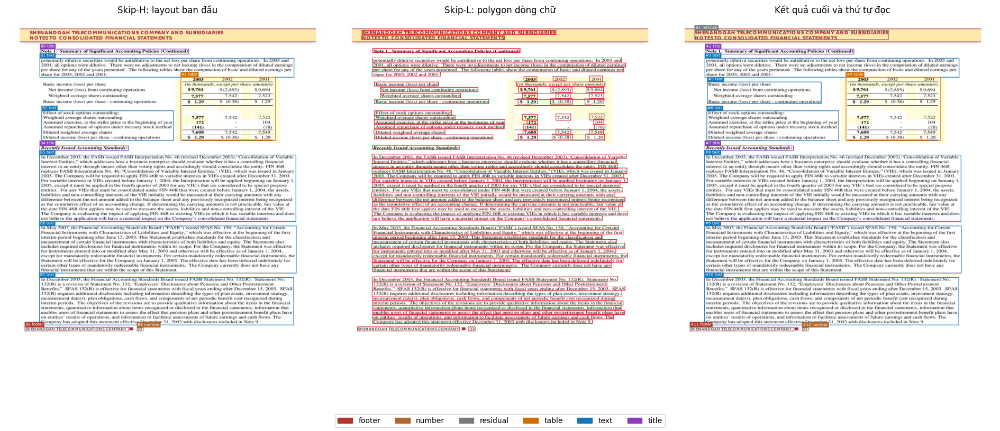

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,recovered:1,residual,"(76, 40, 688, 70)",recovered:1,2,True,SHENANDOAH TELECOMMUNICATIONSCOMPANYAND SUBSID...
1,2,B0,title,"(109, 99, 579, 116)",B0,1,False,Note 1.SummaryofSignificant Accounting Policie...
2,3,B1,text,"(108, 128, 911, 189)",B1,4,True,potentiallydilutive securitieswouldbe antidilu...
3,4,B3,table,"(553, 188, 853, 389)",B3,26,True,"<table border=""1""><tr><td>2003</td><td>2002</t..."
4,5,recovered:0,text,"(116, 203, 476, 272)",recovered:0,4,False,Basic income (loss) per share\nNet income (los...
5,6,B2,text,"(114, 294, 531, 389)",B2,6,False,Effectofstockoptionsoutstanding:\nWeightedaver...
6,7,B4,title,"(108, 405, 388, 421)",B4,1,False,Recently Issued Accounting Standards:
7,8,B5,text,"(107, 434, 917, 645)",B5,14,True,"In December 2003,the FASB issued FASB Interpre..."
8,9,B6,text,"(107, 658, 918, 808)",B6,10,True,"InMay2OO3,theFinancialAccountingStandardsBoard..."
9,10,B7,text,"(107, 821, 910, 972)",B7,10,True,"In December2003,theFinancialAccountingStandard..."


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B1,B1,text,0.7456,0.7456,0.000,insufficient_score_gain_or_confidence
1,KEEP,abstained,B3,B3,table,0.4017,0.4017,0.000,missing_line_coverage; split_geometry_mismatch...
2,KEEP,abstained,B5,B5,text,0.7505,0.7505,0.000,insufficient_score_gain_or_confidence
3,KEEP,abstained,B6,B6,text,0.7523,0.7523,0.000,insufficient_score_gain_or_confidence
4,KEEP,abstained,B7,B7,text,0.7488,0.7488,0.000,insufficient_score_gain_or_confidence
5,RELABEL,accepted,recovered:0,recovered:0,text,0.7550,0.9700,0.215,glm_residual_classification; body_text_positio...
6,KEEP,abstained,recovered:1,recovered:1,residual,0.7550,0.7550,0.000,classification_spatial_mismatch:text; insuffic...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,Basic income (loss) per share\nNet income (los...,
1,recovered:1,1,,text,ok,SHENANDOAH TELECOMMUNICATIONSCOMPANYAND SUBSID...,


... (4 outputs left out)

SHENANDOAH TELECOMMUNICATIONSCOMPANYAND SUBSIDIARIES
NOTESTOCONSOLIPATEDFINANCIALSTATEMENTS

**2. B0 — title**

Note 1.SummaryofSignificant Accounting Policies (Continued)

**3. B1 — text**

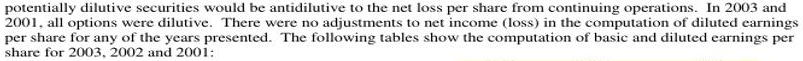

potentiallydilutive securitieswouldbe antidilutive tothe netloss pershare from continuing operations.In 203and
2001,alloptionsweredilutive.Therewerenoadjustmentstonetincome(loss)inthecomputationofdilutedearnings
pershareforanyoftheyearspresented.Thefollowingtables showthecomputationofbasicanddilutedearningsper
share for 2003,2002and2001:

**4. B3 — table**

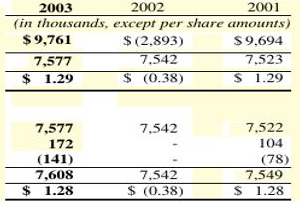

**5. recovered:0 — text**

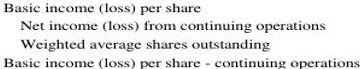

Basic income (loss) per share
Net income (loss)from continuing operations
Weighted average sharesoutstanding
Basic income (loss) per share -continuing operations

**6. B2 — text**

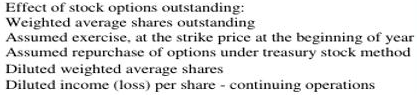

Effectofstockoptionsoutstanding:
Weightedaverage sharesoutstanding
Assumed exercise.at the strike price at the beginning of year
Assumedrepurchase ofoptionsundertreasury stockmethod
Diluted weighted average shares
Diluted income (loss) per share -continuing operations

**7. B4 — title**

Recently Issued Accounting Standards:

**8. B5 — text**

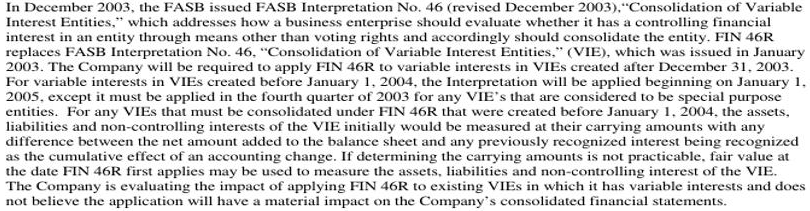

In December 2003,the FASB issued FASB Interpretation No.46(revised December 2003)."ConsolidationofVariable
InterestEntities,”which addresses how a business enterprise shouldevaluate whether ithas a controlling financial
interest inanentity throughmeansother than voting rightsand accordinglyshouldconsolidate the entity.FIN 46R
replacesFASBInterpretationNo.46,"ConsolidationofVariableInterestEntities,”(VIE),whichwas issuedinJanuary
2003.TheCompanywillberequiredtoapplyFIN46RtovariableinterestsinVIEscreatedafterDecember31,2003.
ForvariableinterestsinVIEscreatedbeforeJanuary1,2004,theInterpretationwillbeappliedbeginningonJanuary1,
2005,exceptitmustbeappliedinthefourthquarterof2003foranyViE’sthatareconsideredtobespecialpurpose
entities.ForanyVIEsthatmustbeconsolidatedunderFIN46RthatwerecreatedbeforeJanuary1,20O4,theassets,
liabilitiesandnon-controllinginterestsoftheVIEinitiallywouldbemeasuredattheircarryingamountswithany
differencebetweenthenetamountaddedtothebalancesheetandanypreviouslyrecognizedinterestbeingrecognized
as thecumulativeeffectofanaccountingchange.Ifdeterminingthecarryingamountsisnotpracticable,fairvalueat
the dateFIN 46Rfirstapplies maybe used tomeasure the assets,liabilities andnon-controlling interestoftheVIE.
The Company is evaluating theimpactofapplyingFIN 46Rto existingVIEsin whichithas variableinterestsanddoes
notbelievetheapplicationwillhave amaterialimpactontheCompany’sconsolidatedfinancialstatements.

**9. B6 — text**

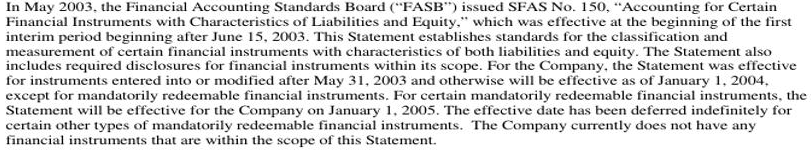

InMay2OO3,theFinancialAccountingStandardsBoard(“FASB")issuedSFASNo.15O,"AccountingforCertain
FinancialInstrumentswithCharacteristicsofLiabilitiesandEquity,whichwaseffectiveatthebeginningofthefirst
interimperiodbeginningafterJune15,20o3.ThisStatementestablishesstandardsfortheclassificationand
measurementofcertainfinancialinstrumentswithcharacteristicsofbothliabilitiesandequity.TheStatementalso
includesrequireddisclosuresforfinancialinstrumentswithinitsscope.FortheCompany,theStatementwaseffective
forinstrumentsenteredintoormodifiedafterMay31,2003andotherwisewillbeeffectiveasofJanuary1,2004,
exceptformandatorilyredeemablefinancialinstruments.Forcertainmandatorilyredeemablefinancialinstruments,the
StatementwillbeeffectivefortheCompanyonJanuary1.20O5.Theeffectivedate hasbeendeferredindefinitelyfor
certainothertypesofmandatorilyredeemablefinancialinstruments.TheCompany currentlydoesnothaveany
financialinstruments thatare within the scope ofthisStatement.

**10. B7 — text**

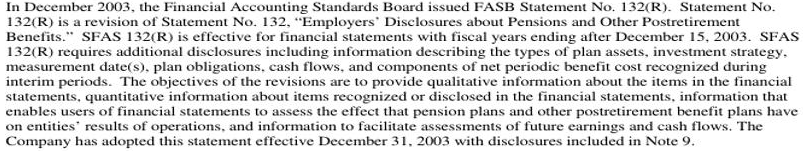

In December2003,theFinancialAccountingStandardsBoardissuedFASB StatementNo.132(R).Statement No.
132(R)is arevisionofStatementNo.132,"Employers’Disclosures aboutPensionsandOtherPostretirement
Benefits.”SFAS132(R)iseffectiveforfinancialstatementswithfiscalyearsendingafterDecember15,2003.SFAS
132(R)requiresadditionaldisclosuresincludinginformationdescribingthetypesofplanassets,investmentstrategy,
measurementdate(s),planobligations,cashflows,andcomponentsofnetperiodicbenefitcostrecognizedduring
interimperiods.Theobjectivesoftherevisionsaretoprovidequalitativeinformationabouttheitemsinthefinancial
statements,quantitativeinformationaboutitemsrecognizedordisclosedinthefinancialstatements,informationthat
enablesusersoffinancialstatementstoassesstheeffectthatpensionplansandotherpostretirementbenefitplanshave
on entities’results ofoperations,and information tofacilitate assessments offuture earnings and cash flows.The
Companyhasadoptedthis statementeffectiveDecember31,2003withdisclosuresincludedinNote9.

**11. B8 — footer**

SHENANDOAH TELECOMMUNICATIONSCOMPANY

**12. B9 — number**

22

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\8\page_0001


**9.png · trang 1 · 77.1s · Hoàn tất: 21 vùng; 15 lượt GLM.**

## Trang 1

**21 vùng · 165 dòng · 15 lượt suy luận GLM**

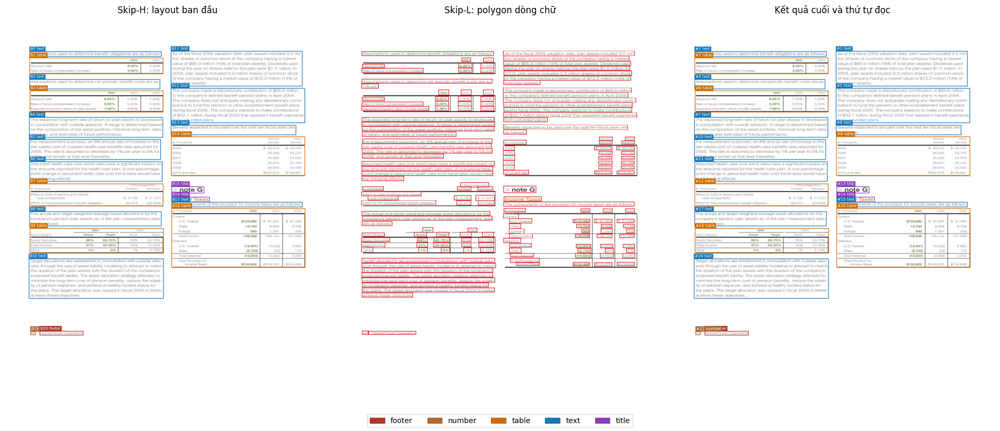

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B11,text,"(522, 106, 937, 217)",B11,7,True,As of the fiscal 2o4 valuation date. plan asse...
1,2,B0,text,"(76, 107, 492, 123)",B0,1,False,Assumptions used to determine benefit obligati...
2,3,B1,table,"(76, 127, 498, 178)",B1,8,False,"<table border=""1""><tr><td></td><td>2004</td><t..."
3,4,B2,text,"(76, 195, 488, 226)",B2,2,True,Assumptions used to determine net periodic ben...
4,5,B12,text,"(522, 223, 945, 333)",B12,7,True,The company made a discretionary contribution ...
5,6,B3,table,"(77, 231, 498, 299)",B3,15,False,"<table border=""1""><tr><td></td><td>2004</td><t..."
6,7,B4,text,"(75, 315, 497, 379)",B4,4,False,The expected long-term rate of return on plan ...
7,8,B13,text,"(522, 340, 917, 371)",B13,2,True,Benefits expected to be paid over the next ten...
8,9,B14,table,"(523, 376, 945, 500)",B14,23,False,"<table border=""1""><tr><td>(in Thousands)</td><..."
9,10,B5,text,"(75, 385, 490, 449)",B5,4,True,"For measurement purposes, an 8% annual rate of..."


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B10,B10,text,0.7488,0.7488,0.0,insufficient_score_gain_or_confidence
1,KEEP,abstained,B11,B11,text,0.7532,0.7532,0.0,insufficient_score_gain_or_confidence
2,KEEP,abstained,B12,B12,text,0.7496,0.7496,0.0,insufficient_score_gain_or_confidence
3,KEEP,abstained,B13,B13,text,0.7363,0.7363,0.0,insufficient_score_gain_or_confidence
4,KEEP,abstained,B17,B17,text,0.7300,0.7300,0.0,insufficient_score_gain_or_confidence
5,KEEP,abstained,B2,B2,text,0.7416,0.7416,0.0,insufficient_score_gain_or_confidence
6,KEEP,abstained,B5,B5,text,0.7425,0.7425,0.0,insufficient_score_gain_or_confidence
7,KEEP,abstained,B6,B6,text,0.7488,0.7488,0.0,insufficient_score_gain_or_confidence
8,KEEP,abstained,B8,B8,text,0.7461,0.7461,0.0,insufficient_score_gain_or_confidence


### Nội dung tài liệu

As of the fiscal 2o4 valuation date. plan assets included 3.2mil
lion shares of common stock of the company having a market
value of $95.9 million (16% of total plan assets).Dividends paid
during the year on shares held by the plan were $1.5 million. In
2003. plan assets included 3.3 million shares of common stock
of the company having amarket value of $72.2 million (14%of
total plan assets).

Assumptions used to determine benefit obligations are as folows:

<table><tbody><tr><td></td><td>2004</td><td>2003</td></tr><tr><td>Discount rate</td><td>6.25%</td><td>6.50%</td></tr><tr><td>Rate of future compensation increase</td><td>5.00%</td><td>5.00%</td></tr></tbody></table>

Assumptions used to determine net periodic benefit costs are as
follows:

The company made a discretionary contribution of $26.8 million
to the company's defined benefit pension plans in April 2004.
The company does not anticipate making any discretionary contri
butions to fund the pension or other postretirement benefit plans
during fiscal 2oo5. The company expects to make contributions
of $42.1 million during fiscal 2oo5 that represent benefit payments
from unfunded plans.

<table><tbody><tr><td></td><td>2004</td><td>2003</td><td>2002</td></tr><tr><td>Discount rate</td><td>6.50%</td><td>7.00%</td><td>7.25%</td></tr><tr><td>Rate of future compensation increase</td><td>5.00%</td><td>5.00%</td><td>5.00%</td></tr><tr><td>Expected long-term return on plan assets</td><td>7.90%</td><td>8.60%</td><td>9.50%</td></tr></tbody></table>

The expected long-term rate of return on plan assets is developed
in consultation with outside advisors. A range is determined based
on the composition of the asset portfalio.historical long-term rates
of retum,and estimates of future performance.

Benefits expected to be paid over the next ten fiscal years are
as follows:

<table><tbody><tr><td>(in Thousands)</td><td>Pension Benefits</td><td>Other Benefits</td></tr><tr><td>2005</td><td>$49,573</td><td>$25,735</td></tr><tr><td>2006</td><td>36,456</td><td>23,725</td></tr><tr><td>2007</td><td>35,285</td><td>24,503</td></tr><tr><td>2008</td><td>35,670</td><td>25,160</td></tr><tr><td>2009</td><td>36,654</td><td>25,595</td></tr><tr><td>2010 and later</td><td>$202,618</td><td>$128,881</td></tr></tbody></table>

For measurement purposes, an 8% annual rate of increase in the
per capita cost of covered health care benefits was assumed for
2005. The rate is assumed to decrease by 1% per year to 5% for
2008. and remain at that level thereafter.

Assumed heaith care cost trend rates have a significant impact on
the amounts reported for the health care plan. A one-percentage-
point change in assumed health care cost trend rates would have
the following efects:

<table><thead><tr><th>(In Thousands)</th><th>1-Percentage-Point Increase</th><th>Decrease</th></tr></thead><tbody><tr><td>Effect on total of service and interest cost components</td><td>$ 2,139</td><td>$ (1,707)</td></tr><tr><td>Effect on the postretirement benefit obligation</td><td>32,413</td><td>(24,694)</td></tr></tbody></table>

# &gt;note G

# Income Taxes

The components of the provision for income taxes are as follows:

<table><tbody><tr><td>(in Thousands)</td><td>2004</td><td>2003</td><td>2002</td></tr><tr><td>Current:</td><td></td><td></td><td></td></tr><tr><td>U.S. Federal</td><td>$133,882</td><td>$97,855</td><td>$91,590</td></tr><tr><td>State</td><td>13,794</td><td>8,908</td><td>9,798</td></tr><tr><td>Foreign</td><td>880</td><td>1,381</td><td>208</td></tr><tr><td>Total Current</td><td>148,556</td><td>108,144</td><td>101,596</td></tr><tr><td>Deferred:</td><td></td><td></td><td></td></tr><tr><td>U.S. Federal</td><td>(12,931)</td><td>(4,533)</td><td>2,882</td></tr><tr><td>State</td><td>(2,723)</td><td>(59)</td><td>170</td></tr><tr><td>Total Deferred</td><td>(15,654)</td><td>(4,592)</td><td>3,052</td></tr><tr><td>Total Provision for Income Taxes</td><td>$132,902</td><td>$103,552</td><td>$104,648</td></tr></tbody></table>

The actual and target weighted-average asset allocations for the
company's pension plan assets as of the plan measurement date
are as follows:

<table><thead><tr><th rowspan="2">Asset Category</th><th colspan="2">2004</th><th colspan="2">2003</th></tr><tr><th>Actual</th><th>Target</th><th>Actual</th><th>Target</th></tr></thead><tbody><tr><td>Equity Securities</td><td>68%</td><td>65-75%</td><td>65%</td><td>55-75%</td></tr><tr><td>Fixed Income</td><td>31%</td><td>25-35%</td><td>34%</td><td>15-35%</td></tr><tr><td>Other</td><td>1%</td><td>0%</td><td>1%</td><td>5-15%</td></tr></tbody></table>

Target allocations are established in consultation with outside advi
sors through the use of asset-liability modeling to attempt to match
the duration of the plan assets with the duration of the company's
prajected benefit liabillity. The asset allocation strategy attempts to
minimize the long-term cost of pension benefits,reduce the volatil-
ity of pension expense, and achieve a healthy funded status for
the plans. The target allocation was revised in fiscal 2oo4 to better
achieve these objectives

Hormel Foods Corporation

42

### Crop và nội dung từng vùng

**1. B11 — text**

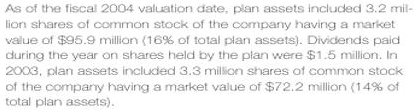

As of the fiscal 2o4 valuation date. plan assets included 3.2mil
lion shares of common stock of the company having a market
value of $95.9 million (16% of total plan assets).Dividends paid
during the year on shares held by the plan were $1.5 million. In
2003. plan assets included 3.3 million shares of common stock
of the company having amarket value of $72.2 million (14%of
total plan assets).

**2. B0 — text**

Assumptions used to determine benefit obligations are as folows:

**3. B1 — table**

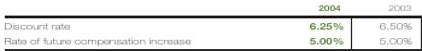

,2004,2003
Discount rate,6.25%,6.50%
Rate of future compensation increase,5.00%,5.00%


**4. B2 — text**

Assumptions used to determine net periodic benefit costs are as
follows:

**5. B12 — text**

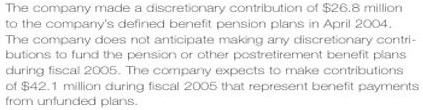

The company made a discretionary contribution of $26.8 million
to the company's defined benefit pension plans in April 2004.
The company does not anticipate making any discretionary contri
butions to fund the pension or other postretirement benefit plans
during fiscal 2oo5. The company expects to make contributions
of $42.1 million during fiscal 2oo5 that represent benefit payments
from unfunded plans.

**6. B3 — table**

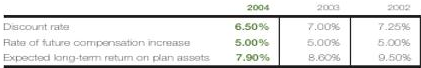

,2004,2003,2002
Discount rate,6.50%,7.00%,7.25%
Rate of future compensation increase,5.00%,5.00%,5.00%
Expected long-term return on plan assets,7.90%,8.60%,9.50%


**7. B4 — text**

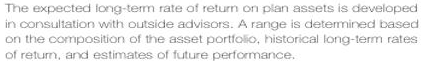

The expected long-term rate of return on plan assets is developed
in consultation with outside advisors. A range is determined based
on the composition of the asset portfalio.historical long-term rates
of retum,and estimates of future performance.

**8. B13 — text**

Benefits expected to be paid over the next ten fiscal years are
as follows:

**9. B14 — table**

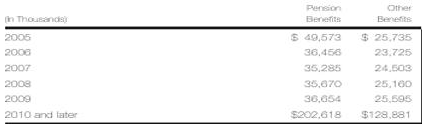

(in Thousands),Pension Benefits,Other Benefits
2005,"$49,573","$25,735"
2006,"36,456","23,725"
2007,"35,285","24,503"
2008,"35,670","25,160"
2009,"36,654","25,595"
2010 and later,"$202,618","$128,881"


**10. B5 — text**

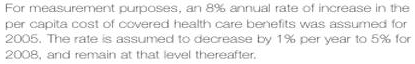

For measurement purposes, an 8% annual rate of increase in the
per capita cost of covered health care benefits was assumed for
2005. The rate is assumed to decrease by 1% per year to 5% for
2008. and remain at that level thereafter.

**11. B6 — text**

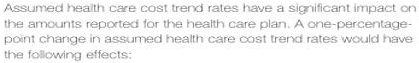

Assumed heaith care cost trend rates have a significant impact on
the amounts reported for the health care plan. A one-percentage-
point change in assumed health care cost trend rates would have
the following efects:

**12. B7 — table**

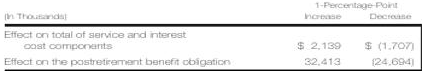

(In Thousands),1-Percentage-Point Increase,Decrease
Effect on total of service and interest cost components,"$ 2,139","$ (1,707)"
Effect on the postretirement benefit obligation,"32,413","(24,694)"


**13. B15 — title**

&gt;note G

**14. B16 — title**

Income Taxes

**15. B17 — text**

The components of the provision for income taxes are as follows:

**16. B18 — table**

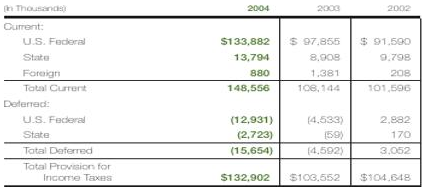

(in Thousands),2004,2003,2002
Current:,,,
U.S. Federal,"$133,882","$97,855","$91,590"
State,"13,794","8,908","9,798"
Foreign,880,"1,381",208
Total Current,"148,556","108,144","101,596"
Deferred:,,,
U.S. Federal,"(12,931)","(4,533)","2,882"
State,"(2,723)",(59),170
Total Deferred,"(15,654)","(4,592)","3,052"
Total Provision for Income Taxes,"$132,902","$103,552","$104,648"


**17. B8 — text**

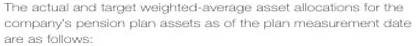

The actual and target weighted-average asset allocations for the
company's pension plan assets as of the plan measurement date
are as follows:

**18. B9 — table**

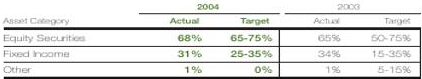

**19. B10 — text**

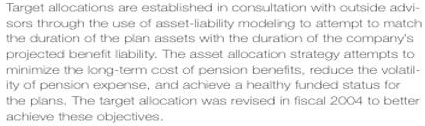

Target allocations are established in consultation with outside advi
sors through the use of asset-liability modeling to attempt to match
the duration of the plan assets with the duration of the company's
prajected benefit liabillity. The asset allocation strategy attempts to
minimize the long-term cost of pension benefits,reduce the volatil-
ity of pension expense, and achieve a healthy funded status for
the plans. The target allocation was revised in fiscal 2oo4 to better
achieve these objectives

**20. B20 — footer**

Hormel Foods Corporation

Đang xem 20/21 crop. Đặt MAX_REGION_PREVIEWS=None để xem toàn bộ.

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\9\page_0001


**10.png · trang 1 · 42.0s · Hoàn tất: 14 vùng; 11 lượt GLM.**

## Trang 1

**14 vùng · 89 dòng · 11 lượt suy luận GLM**

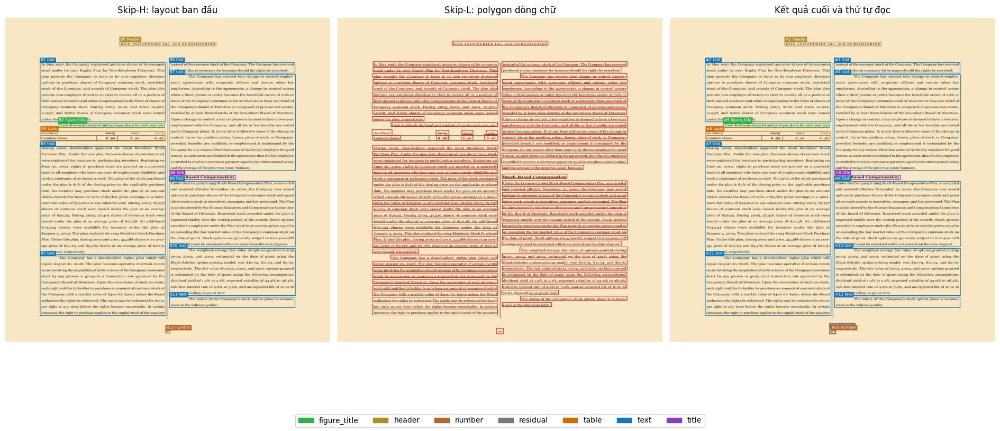

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B0,header,"(360, 77, 665, 90)",B0,1,False,HON INDUSTRIES InC. aND SUBSIDIARIES
1,2,B1,text,"(109, 142, 506, 330)",B1,10,True,"In May 197.the Company registered 4oo,ooo shar..."
2,3,B6,text,"(516, 142, 914, 176)",B6,2,True,insteadofthecommonstockoftheCompany.TheCompany...
3,4,B7,text,"(516, 180, 916, 484)",B7,16,True,The Company has entered into change in control...
4,5,B2,figure_title,"(166, 335, 503, 348)",B2,1,False,Cash dividends declared and paid per share for...
5,6,B3,table,"(111, 360, 504, 390)",B3,8,False,<table><thead><tr><th>(in dollars)</th><th>200...
6,7,B4,text,"(109, 407, 506, 749)",B4,18,True,"During 20o2, shareholders approved the 20o2 Me..."
7,8,B8,title,"(518, 498, 726, 512)",B8,1,False,Stock-Based Compensation
8,9,B9,text,"(516, 517, 915, 725)",B9,11,True,Underthe Company's199s Stock-Based Compensatio...
9,10,B10,text,"(516, 729, 915, 879)",B10,8,True,The weighted-average fair value ofoptions gran...


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B1,B1,text,0.7475,0.7475,0.0000,insufficient_score_gain_or_confidence
1,KEEP,abstained,B10,B10,text,0.7407,0.7407,0.0000,insufficient_score_gain_or_confidence
2,KEEP,abstained,B11,B11,text,0.7175,0.7193,0.0018,insufficient_score_gain_or_confidence
3,KEEP,abstained,B4,B4,text,0.7490,0.7490,0.0000,insufficient_score_gain_or_confidence
4,KEEP,abstained,B5,B5,text,0.7470,0.7470,0.0000,independent_transcripts_unavailable; insuffici...
5,KEEP,abstained,B6,B6,text,0.7175,0.7175,0.0000,content_loss_or_hallucination; insufficient_sc...
6,KEEP,abstained,B7,B7,text,0.7488,0.7488,0.0000,insufficient_score_gain_or_confidence
7,KEEP,abstained,B9,B9,text,0.7501,0.7501,0.0000,insufficient_score_gain_or_confidence
8,KEEP,abstained,recovered:0,recovered:0,residual,0.7550,0.7550,0.0000,classification_spatial_mismatch:text; classifi...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,verbatim target text,


... (2 outputs left out)

### Crop và nội dung từng vùng

**1. B0 — header**

HON INDUSTRIES InC. aND SUBSIDIARIES

**2. B1 — text**

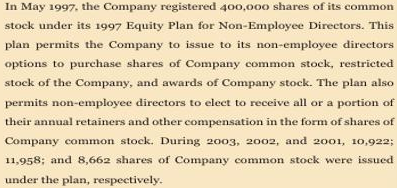

In May 197.the Company registered 4oo,ooo shares of its common
stock under its 1997 Equity Plan for Non-Employee Directors. This
plan permits the Company to issue to its non-employee directors
options to purchase shares of Company common stock, restricted
stock of the Company, and awards of Company stock. The plan also
permits non-employee directors to elect to receive all or a portion of
their annual retainers and other compensation in the form of shares of
Company common stock. During 2003,2002, and 2001,10,922;
11.958:and 8.662 shares of Company common stock were issued
under the plan,respectively.

**3. B6 — text**

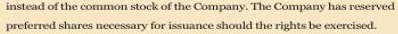

insteadofthecommonstockoftheCompany.TheCompanyhasreserved
prefereuoldeb

**4. B7 — text**

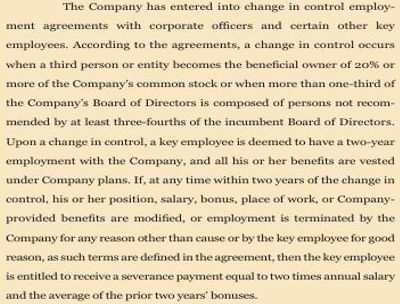

The Company has entered into change in control employ-
ment agreements with corporate officers and certain other key
employees. Aecording to the agreements, a change in control occurs
when a third person or entity becomes the beneficial owner of 20%or
more of the Company's common stock or when more than one-third of
the Company's Board of Directors is composed of persons not recom-
mended bv at least three-fourths of the incumbent Board of Directors.
Upon a change in control,akey employee is deemed to have a two-year
employment with the Company,and all his or her benefits are vested
underCompanyplanIf,atanytimewithintwoyearsof thechangein
control,his or her position,salary,bonus, place of work,or Company-
provided benefits are modified, or employment is terminated by the
Company for anyreason other than cause or by thekeyemployeefor good
reason,as such terms are defined in the agreement,then the key employee
ieniteouu
and the average of the prior two years' bonuses.

**5. B2 — figure_title**

Cash dividends declared and paid per share for each year are:

**6. B3 — table**

(in dollars),2003,2002,2001
Common shares,$ .52,$ .50,$ .48


**7. B4 — text**

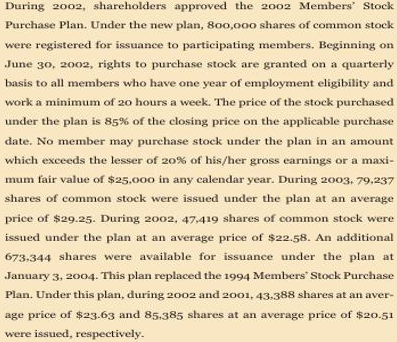

During 20o2, shareholders approved the 20o2 Members Stock
Purchase Plan.Under the new plan, 8oo,ooo shares of common stock
were registered for issuance to participating members. Beginning on
June 3o, 2oo2, rights to purchase stock are granted on a quarterly
basis to all members who have one vear of employment eligibillity and
work a minimum of 2o hours a week. The price of the stock purchased
under the plan is 85% of the closing price on the applicable purchase
date. No member may purchase stock under the plan in an amount
which exceeds the lesser of 2o% of his/her gross earnings or a maxi-
mum fair value of $25.ooo in any calendar year. During 20o3.79.237
shares of common stock were issued under the plan at an average
price of $29.25. During 2002,47,419 shares of common stock were
issued under the plan at an average price of $22.58. An additional
673.344 shares were available for issuance under the plan at
January 3,2004.This plan replaced the 1994 Members Stock Purchase
Plan.Under this plan,during 2002 and 2oo1,43.388 shares at an aver-
age price of $23.63 and 85.385 shares at an average price of $20.51
were issued, respectively.

**8. B8 — title**

Stock-Based Compensation

**9. B9 — text**

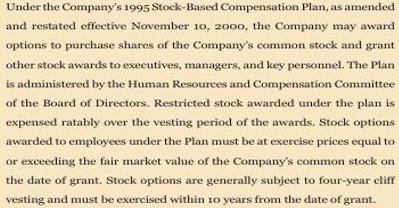

Underthe Company's199s Stock-Based Compensation Plan,as amended
and restated effective November 1o,2ooo, the Company may award
options to purchase shares of the Company's common stock and grant
other stock awards to executives,managers, and key personnel.The Plan
is administered by the Human Resources and Compensation Committee
of the Board of Directors. Restricted stock awarded under the plan is
expensed ratably over the vesting period of the awards.Stock options
awarded to employees under the Plan must be at exercise prices equal to
or exceeding the fair market value of the Companys common stock on
the date of grant.Stock options are generally subject to four-year cliff
vesting andmust beexercised withinioyearsfromthedateofgrant.

**10. B10 — text**

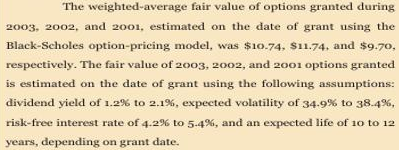

The weighted-average fair value ofoptions granted during
2003.2002.and 2oo1,estimated on the date of grant using the
Black-Scholes option-pricing model,was $1O.74,$11.74,and $9.70,
respectively.The fair value of 2oo3,20o2,and 2oo1 options granted
is estimated on the date of grant using the following assumptions:
dividend yield of 1.2% to 2.1%,expected volatility of 34.9% to 38.4%,
risk-free interest rate of 4.2% to 5.4%,and an expected life of 1o to 12
years, depending on grant date.

**11. B5 — text**

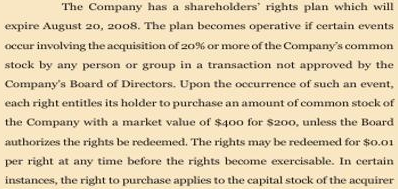

The Company has a shareholders' rights plan which will
expire August 2o, 2oo8. The plan becomes operative if certain events
occur involving the acquisition of 2o% or more of theCompanys common
stock by any person or group in a transaction not approved by the
Company's Board of Directors. Upon the occurrence of such an event.
each right entitles its holder to purchase an amount of common stock of
the Company with a market value of $4oo for $2oo,unless the Board
authorizes the rights be redeemed.The rights may be redeemed for $o.
per right at any time before the rights become exercisable.In certain


**12. B11 — text**

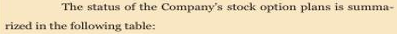

The status of the Company's stock option plans is summa-
rized in the following table:

**13. recovered:0 — residual**

50

**14. B12 — number**

50

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\10\page_0001


**11.png · trang 1 · 37.8s · Hoàn tất: 13 vùng; 8 lượt GLM.**

## Trang 1

**13 vùng · 125 dòng · 8 lượt suy luận GLM**

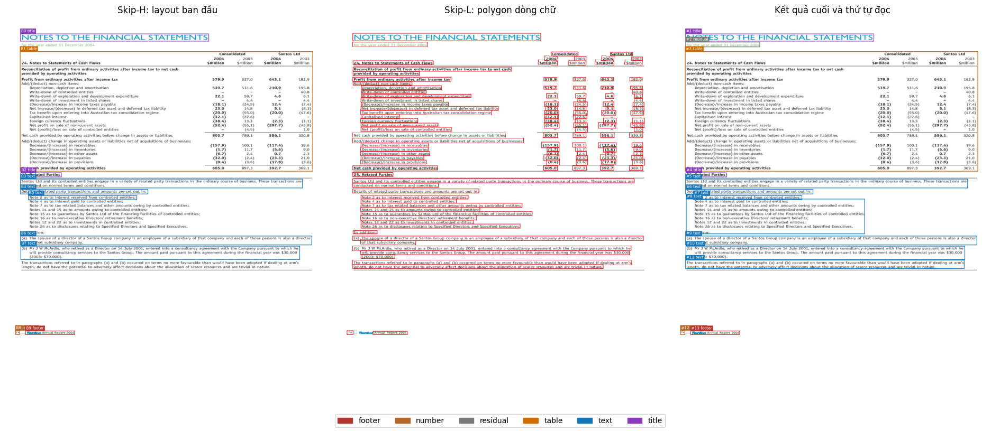

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B0,title,"(47, 51, 642, 75)",B0,1,False,NOTESTOTHE FINANCIALSTATEMENTS
1,2,recovered:2,residual,"(47, 77, 282, 93)",recovered:2,1,True,for the year ended 31 December 2004
2,3,B1,table,"(46, 107, 970, 486)",B1,101,False,Consolidated\nSantos Ltd\n2004\n2004\n2003\n20...
3,4,B2,title,"(48, 490, 177, 504)",B2,1,False,25.Related Parties
4,5,B3,text,"(47, 510, 938, 539)",B3,2,True,Santos Ltd and its controlled entities engage ...
5,6,B4,text,"(47, 543, 450, 558)",B4,1,True,Details of related party transactions and amou...
6,7,B5,text,"(72, 562, 415, 576)",B5,1,True,Note 2 as to interest received from controlled...
7,8,recovered:1,text,"(49, 573, 613, 684)",recovered:1,8,False,Note 4 as to interest paid to controlled entit...
8,9,B6,text,"(47, 690, 967, 719)",B6,2,False,(a) The spouse of a director of a Santos Group...
9,10,B7,text,"(48, 722, 929, 765)",B7,3,True,"(b) MrJ W McArdle, who retired as a Director o..."


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B3,B3,text,0.7416,0.7416,0.0000,insufficient_score_gain_or_confidence
1,KEEP,abstained,B4,B4,text,0.7014,0.7250,0.0236,insufficient_score_gain_or_confidence
2,KEEP,abstained,B5,B5,text,0.7262,0.7262,0.0000,insufficient_score_gain_or_confidence
3,KEEP,abstained,B7,B7,text,0.7507,0.7507,0.0000,insufficient_score_gain_or_confidence
4,RELABEL,accepted,recovered:0,recovered:0,text,0.7550,0.9700,0.2150,glm_residual_classification; body_text_positio...
5,RELABEL,accepted,recovered:1,recovered:1,text,0.7550,0.9656,0.2106,glm_residual_classification; body_text_positio...
6,KEEP,abstained,recovered:2,recovered:2,residual,0.7550,0.7550,0.0000,classification_spatial_mismatch:text; insuffic...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,The transactions referred to in paragraphs (a)...,
1,recovered:1,1,,text,ok,Note 4 as to interest paid to controlled entit...,
2,recovered:2,1,,text,ok,for the year ended 31 December 2004,


... (6 outputs left out)

NOTESTOTHE FINANCIALSTATEMENTS

**2. recovered:2 — residual**

for the year ended 31 December 2004

**3. B1 — table**

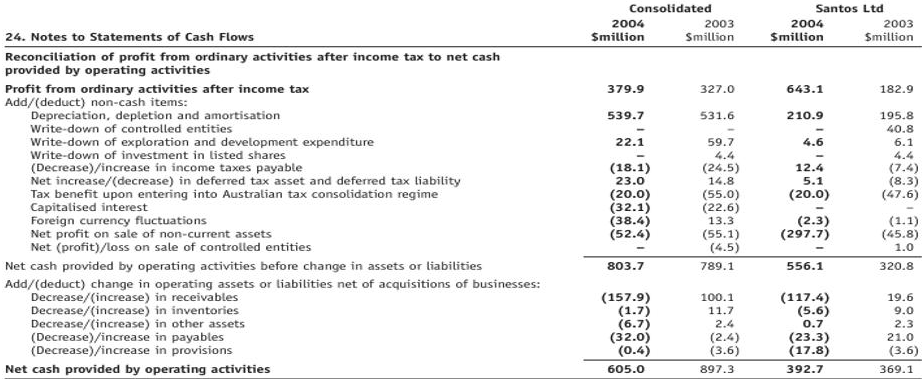

**4. B2 — title**

25.Related Parties

**5. B3 — text**

Santos Ltd and its controlled entities engage in a variety of related party transactions in the ordinary course of business. These transactions are
conducted on normal terms and conditions.

**6. B4 — text**

Details of related party transactions and amounts are set out in:

**7. B5 — text**

Note 2 as to interest received from controlled entities;

**8. recovered:1 — text**

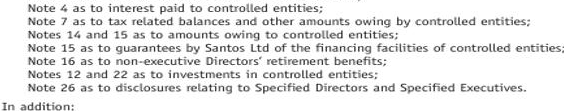

Note 4 as to interest paid to controlled entities;
Note 7 as to tax related balances and other amounts owing by controlled entities;
Notes 14 and 15 as to amounts owing to controlled entities;
Note 15 as to guarantees by Santos Ltd of the financing facilities of controlled entities
Note 16 as to non-executive Directors retirement benefits;
Notes 12 and 22 as to investments in controlled entities;
Note 26 as to disclosures relating to Specified Directors and Specified Executives.
In addition:

**9. B6 — text**

(a) The spouse of a director of a Santos Group company is an employee of a subsidiary of that company and each of those persons is also a director
of that subsidiary company.

**10. B7 — text**

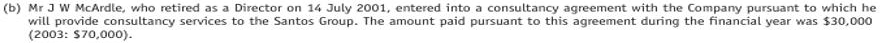

(b) MrJ W McArdle, who retired as a Director on 14 July 20o1, entered into a consultancy agreement with the Company pursuant to which he
will provide consultancy services to the Santos Group.The amount paid pursuant to this agreement during the financial year was $3o,000
(2003:$70,000).

**11. recovered:0 — text**

The transactions referred to in paragraphs (a) and (b) occurred on terms no more favourable than would have been adopted if dealing at arm's
length,do not have the potential to adversely affect decisions about the allocation of scarce resources and are trivial in nature.

**12. B8 — number**

74

**13. B9 — footer**

AnnualReport2004

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\11\page_0001


**13.png · trang 1 · 3.9s · Hoàn tất: 14 vùng; 8 lượt GLM.**

## Trang 1

**14 vùng · 70 dòng · 8 lượt suy luận GLM**

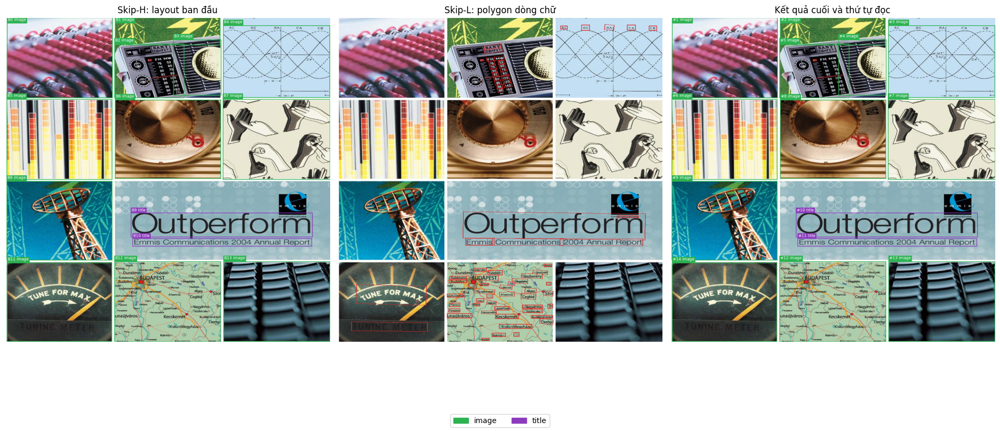

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B0,image,"(5, 0, 338, 254)",B0,0,False,```markdown\n\n```
1,2,B1,image,"(346, 0, 678, 87)",B1,0,False,```markdown\n\n```
2,3,B4,image,"(687, 25, 1024, 253)",B4,5,False,BA|\nBC\nCA\nAC\ncB
3,4,B3,image,"(530, 70, 681, 246)",B3,0,False,100\n120\n140\n160\nXH2
4,5,B2,image,"(344, 83, 564, 254)",B2,19,False,SANY\nIC+FET\nMW\nFM\n53\n76\n60\n78\n70\n80\n...
5,6,B5,image,"(4, 258, 337, 512)",B5,0,False,```markdown\n\n```
6,7,B7,image,"(686, 258, 1025, 512)",B7,0,False,```markdown\n\n```
7,8,B6,image,"(346, 260, 680, 509)",B6,0,False,160
8,9,B8,image,"(4, 517, 337, 767)",B8,0,False,```markdown\n\n```
9,10,B9,title,"(396, 617, 969, 694)",B9,2,False,Outperform\nimunications


### Các thay đổi và quyết định

Không có đề xuất thay đổi.

### Nội dung tài liệu

```markdown

```

```markdown

```

BA|
BC
CA
AC
cB

100
120
140
160
XH2

SANY
IC+FET
MW
FM
53
76
60
78
70
80
80
82
100
84
120
86
140
88
90

```markdown

```

```markdown

```

160

```markdown

```

# Outperform
imunications

# Emmis
Communications
2004AnnualReport

Heves
entendre
oJaszapat
Godoll-
Jaszbereny
BUDAPEST
Budakeszio
Nagykita
Budaors
Te
(15)
®
ecsCs
Monor
Abony
Dunaharaszti
Szol
Albertirsa
Cegled
zazhalonba
0
Bagy.
Dabas
Gardamy
lcne
Us
oNagyk-ros
Lajosmizse
Sewgelyes
Tiszakecske
Yem
unaújvaros
Kecskemet
Kunszentmarton
Csongr
Kiskunfelegyhaza
0
Kisk-rOs
arapcal

```markdown

```

TUNE FOR MAX
TUNING METER

### Crop và nội dung từng vùng

**1. B0 — image**

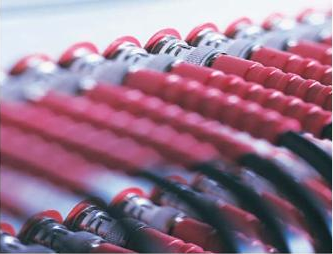

```markdown

```

**2. B1 — image**

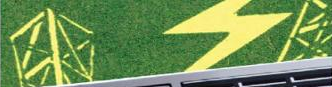

```markdown

```

**3. B4 — image**

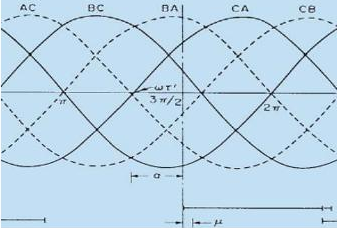

BA|
BC
CA
AC
cB

**4. B3 — image**

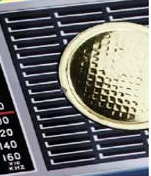

100
120
140
160
XH2

**5. B2 — image**

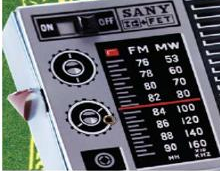

SANY
IC+FET
MW
FM
53
76
60
78
70
80
80
82
100
84
120
86
140
88
90

**6. B5 — image**

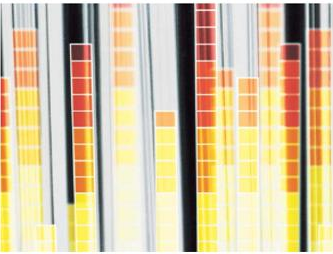

```markdown

```

**7. B7 — image**

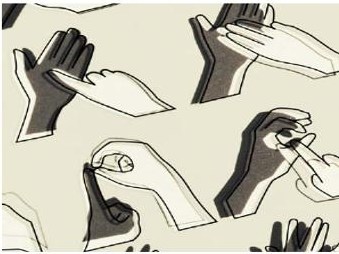

```markdown

```

**8. B6 — image**

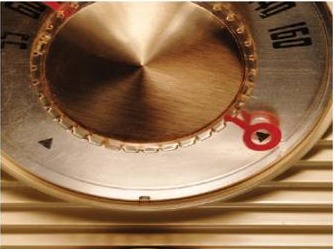

160

**9. B8 — image**

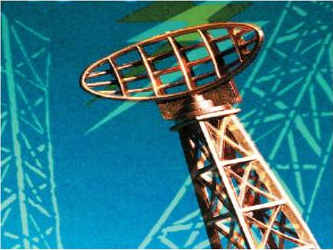

```markdown

```

**10. B9 — title**

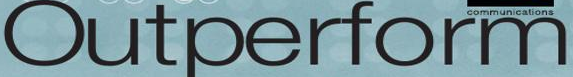

Outperform
imunications

**11. B10 — title**

Emmis
Communications
2004AnnualReport

**12. B12 — image**

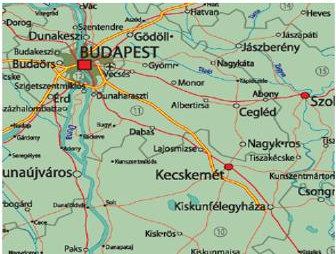

Heves
entendre
oJaszapat
Godoll-
Jaszbereny
BUDAPEST
Budakeszio
Nagykita
Budaors
Te
(15)
®
ecsCs
Monor
Abony
Dunaharaszti
Szol
Albertirsa
Cegled
zazhalonba
0
Bagy.
Dabas
Gardamy
lcne
Us
oNagyk-ros
Lajosmizse
Sewgelyes
Tiszakecske
Yem
unaújvaros
Kecskemet
Kunszentmarton
Csongr
Kiskunfelegyhaza
0
Kisk-rOs
arapcal

**13. B13 — image**

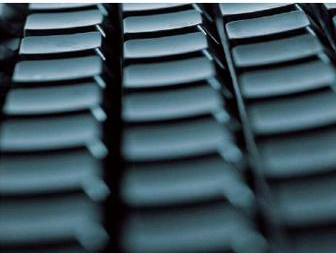

```markdown

```

**14. B11 — image**

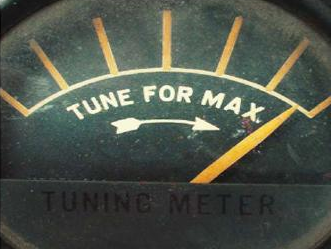

TUNE FOR MAX
TUNING METER

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\13\page_0001


**14.png · trang 1 · 42.4s · Hoàn tất: 2 vùng; 3 lượt GLM.**

## Trang 1

**2 vùng · 4 dòng · 3 lượt suy luận GLM**

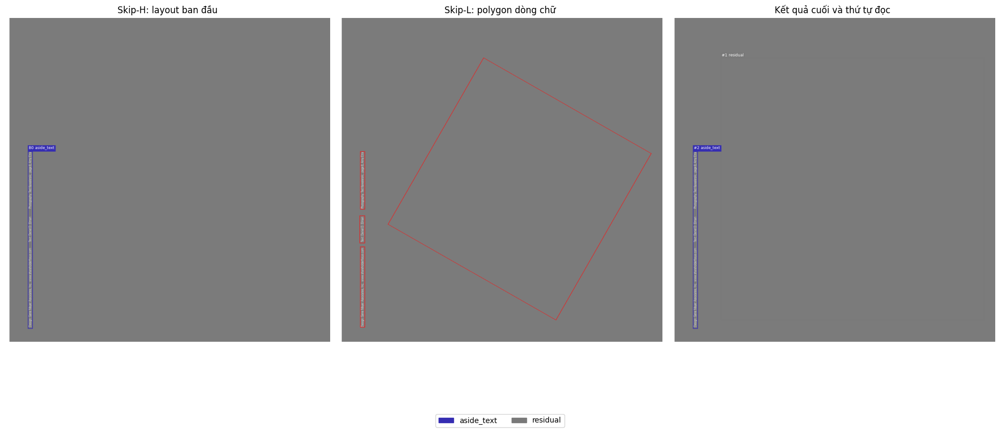

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,recovered:0,residual,"(159, 127, 989, 956)",recovered:0,1,True,The image provided does not contain any text.
1,2,B0,aside_text,"(71, 423, 86, 983)",B0,3,False,"Design: Gene Major Associates, Inc. www.shamho..."


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,recovered:0,recovered:0,residual,0.555,0.555,0.0,independent_transcripts_unavailable; classific...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,verbatim target text,


### Nội dung tài liệu

The image provided does not contain any text.

Design: Gene Major Associates, Inc. www.shamholderfocus.com Text: Daniel D. Emani Photography: Ted Kawaiers; page 8, Amy Etta

### Crop và nội dung từng vùng

**1. recovered:0 — residual**

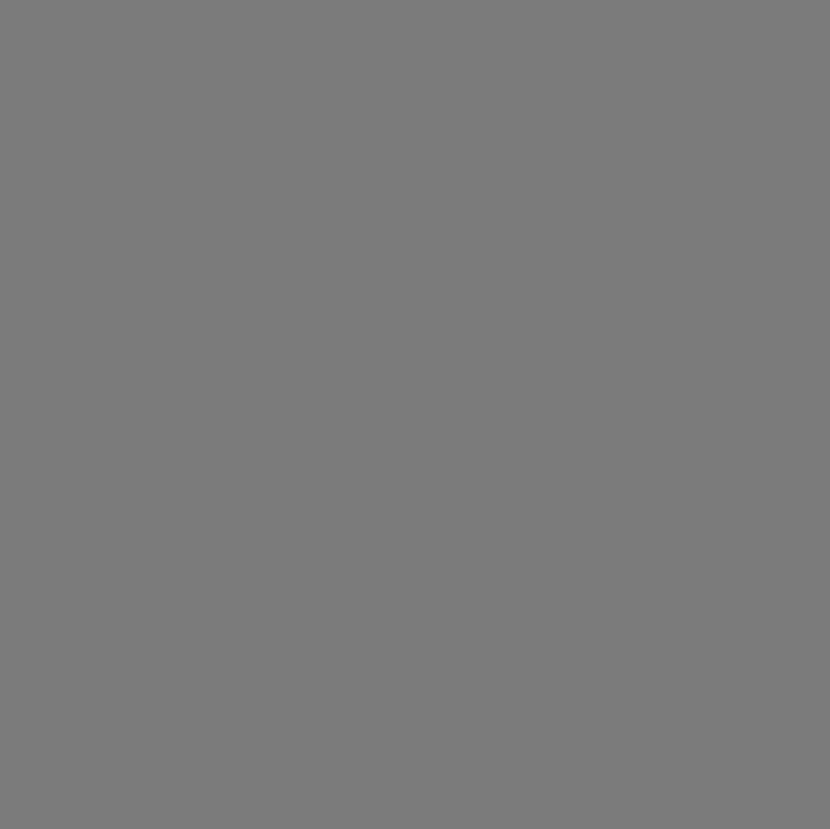

The image provided does not contain any text.

**2. B0 — aside_text**

Design: Gene Major Associates, Inc. www.shamholderfocus.com Text: Daniel D. Emani Photography: Ted Kawaiers; page 8, Amy Etta

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\14\page_0001


**15.png · trang 1 · 14.9s · Hoàn tất: 11 vùng; 8 lượt GLM.**

## Trang 1

**11 vùng · 33 dòng · 8 lượt suy luận GLM**

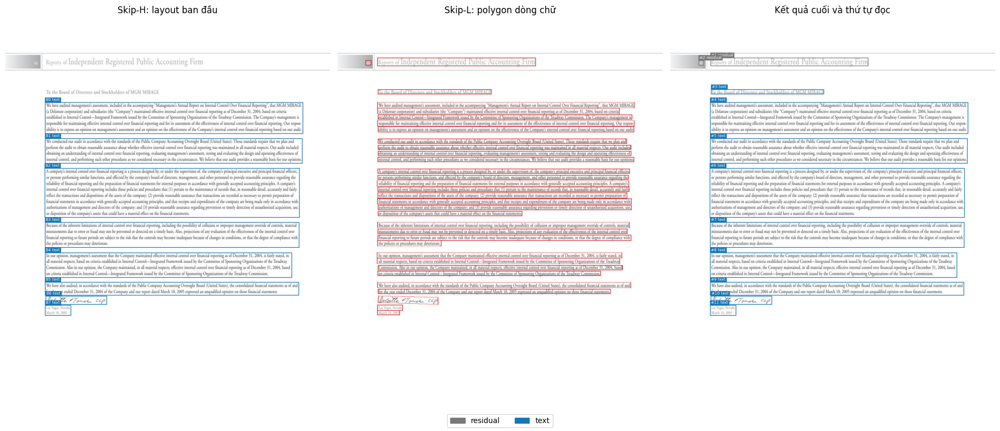

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,recovered:2,residual,"(126, 127, 624, 153)",recovered:2,1,True,Reports of IndependentRegisteredPublicAccounti...
1,2,recovered:1,residual,"(89, 135, 105, 151)",recovered:1,1,True,40
2,3,recovered:0,text,"(128, 227, 484, 242)",recovered:0,1,False,Tothe Board of Directors and Stockholders ofMG...
3,4,B0,text,"(125, 268, 939, 367)",B0,5,True,WehaveauditedgmtemntincudeincomigMaaemtsAnnual...
4,5,B1,text,"(125, 382, 937, 461)",B1,4,False,Weconductedourauditinacordancewihthestandardso...
5,6,B2,text,"(124, 476, 928, 632)",B2,8,False,Acompanysinternalcontroloverfinancialreporting...
6,7,B3,text,"(125, 647, 927, 727)",B3,4,True,Becauseotoocroetiorooor\nmisstatementsduetoerr...
7,8,B4,text,"(125, 743, 904, 822)",B4,4,True,InourongmtmCoeviacotrorfcretoeeirn\nalltalteot...
8,9,B5,text,"(125, 836, 926, 878)",B5,2,False,WehaveaoaudinortttnroublcComAcoutOgorUtethonol...
9,10,B6,text,"(127, 880, 320, 907)",B6,1,True,Decoitle tToute cp


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B0,B0,text,0.7529,0.7529,0.000,content_loss_or_hallucination; insufficient_sc...
1,KEEP,abstained,B3,B3,text,0.7524,0.7524,0.000,content_loss_or_hallucination; insufficient_sc...
2,KEEP,abstained,B4,B4,text,0.7524,0.7524,0.000,content_loss_or_hallucination; insufficient_sc...
3,KEEP,abstained,B6,B6,text,0.7533,0.7533,0.000,content_loss_or_hallucination; insufficient_sc...
4,KEEP,abstained,B7,B7,text,0.7446,0.7446,0.000,insufficient_score_gain_or_confidence
5,RELABEL,accepted,recovered:0,recovered:0,text,0.7550,0.9700,0.215,glm_residual_classification; body_text_positio...
6,KEEP,abstained,recovered:1,recovered:1,residual,0.7550,0.7550,0.000,classification_spatial_mismatch:text; classifi...
7,KEEP,abstained,recovered:2,recovered:2,residual,0.7550,0.7550,0.000,classification_spatial_mismatch:text; insuffic...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,To the Board of Directors and Stockholders of ...,
1,recovered:1,1,,text,ok,verbatim target text,
2,recovered:2,1,,text,ok,Reports of Independent Registered Public Accou...,


... (6 outputs left out)

40

**3. recovered:0 — text**

Tothe Board of Directors and Stockholders ofMGMMIRAGE

**4. B0 — text**

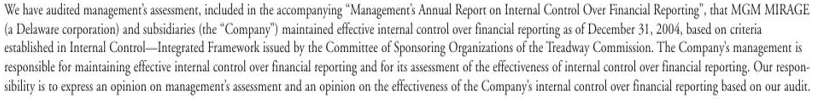

WehaveauditedgmtemntincudeincomigMaaemtsAnnualRernIalCorolOerFncalRrtgatG
（aDelawareorionnbiiieeomanyminedectiveinaorofinaniarortinaoDeb1baeo
establishedinInternalControlIntegraredFrameworkissuedbytheCommitteeofSponsoringOrganizationsoftheTreadwayCommission.TheCompany’smanagementis
responbleotiictrofcetnoitocioiorofrtn
sibilititoxnootanaioohteComsalooliacialrtbraut

**5. B1 — text**

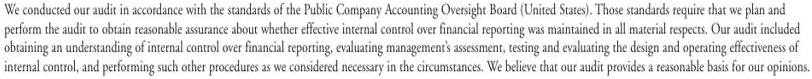

WeconductedourauditinacordancewihthestandardsofthePublicCompanyAccountingOversightBoardUnitedStares).Thosestandardsrequirethatweplanad
performtheaudittoobtainreasonableassuranceaboutwhethereffectiveinternalcontroloverfinancialreportingwasmaintainedinallmaterialrespects.Ourauditincuded
obtaininganundrtandinofinernaconroloverfinancialreortingevaluatingmanagementassessmenttestinandevalutitheesignandoeratinefectivenessof
internacontrolandperormingsuchotherproceduresasweconsiderednecesaryintheircumstancesWebelievethatourauditprovideareasonablebasisforouropinions

**6. B2 — text**

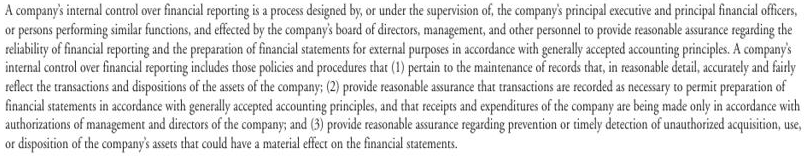

Acompanysinternalcontroloverfinancialreportingisaprocessdesignedbyorunderthesupervisionofthecompanysprincipalexecutiveandprincipalfinanciaofficrs
orpersonsperformingsimilarfunctionsandeffectedbythecompanysboardofdirecors,managementandotherpersonneltoprovidereasonableassuranceregadingthe
reliailitofaaertantreiootouoioaleouy
internacontroloerfinancialreortingincludethosepoliciesandprocedurestha1pertaintothemaintenanceofrecordsthatinreasonabledetailaccuratelyandfarly
reflectettinotiotofhoniblucetieto
financialttmticcoatlcetedoutirileandtharceitanxniureothecomaarbimadnlinace
authorizationsofmanagementanddirectorsofthecompanyand3rovidereasonableassuranceregardingpreventionortimeldetectionofunauthoriedacuisitione
ordispositionofthecompanysassetsthatcouldhaveamaterialeffectonthefinancialstaemen.

**7. B3 — text**

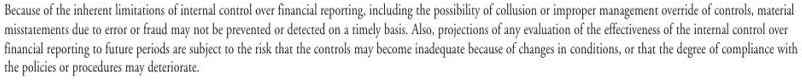

Becauseotoocroetiorooor
misstatementsduetoerrororraudmaynotbepreventedordetectedonatimelybasisAlsoprojectionsofanyevaluationoftheeffectivenessoftheinternacontoov
financiarertitouurerioruttrikhtcoolboinaeubuoaionitiorthathedeococ
thepolicieoroeuema.

**8. B4 — text**

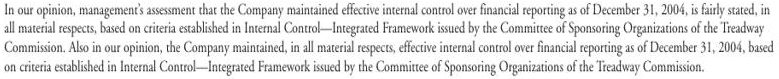

InourongmtmCoeviacotrorfcretoeeirn
alltalteotitbleiInaolIteFraorkueboeofoiitTa
Commission.AlsoinouropiniontheCompanymaintainedinallmaterialrespectsefectiveinternacontroloverfinancialreortingasofDecember31204,based
oncriteriaestablishedinInternalControlIntegratedFrameworkissuedbytheCommiteeofSponsoringOrganizationsoftheTreadwayCommission.

**9. B5 — text**

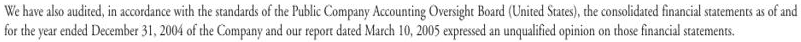

WehaveaoaudinortttnroublcComAcoutOgorUtethonolidenaato
fortheyearendedDecember31,2004oftheCompanyandourreportdatedMarch10,2005expressedanunqualifiedopiniononthosefinancialstatements.

**10. B6 — text**

Decoitle tToute cp

**11. B7 — text**

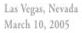

Las Vegas, Nevada
March 10, 2005

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\15\page_0001


**16.png · trang 1 · 270.6s · Hoàn tất: 16 vùng; 13 lượt GLM.**

## Trang 1

**16 vùng · 203 dòng · 13 lượt suy luận GLM**

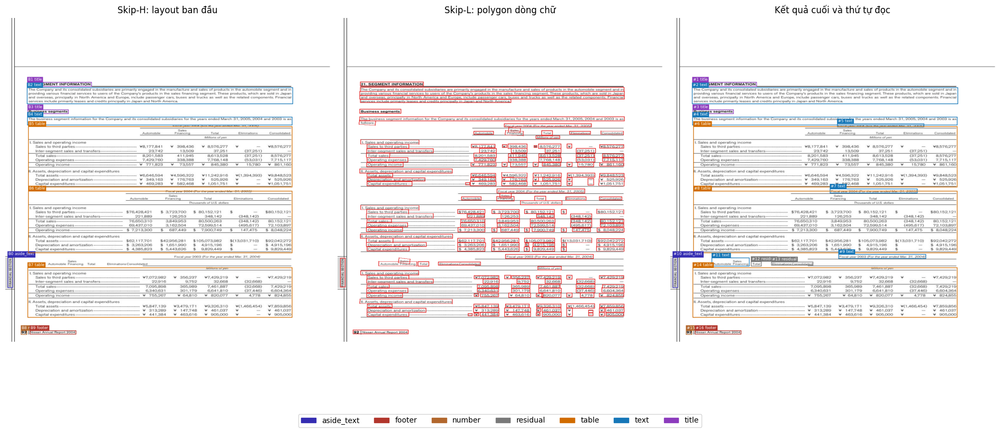

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B1,title,"(69, 204, 272, 218)",B1,1,False,21.SEGMENTINFORMATION
1,2,B2,text,"(68, 221, 907, 273)",B2,4,True,The Company and its consolidated subsidiaries ...
2,3,B3,title,"(70, 291, 199, 304)",B3,1,False,Business segments
3,4,B4,text,"(69, 314, 905, 340)",B4,2,True,The business segment information for the Compa...
4,5,recovered:5,text,"(526, 335, 800, 346)",recovered:5,1,False,Fiscal vear 2oo4 (For the veac ended Mar.3r.2005)
5,6,B5,table,"(72, 344, 905, 536)",B5,64,False,"<table border=""1""><tr><td rowspan=""3""></td><td..."
6,7,recovered:4,text,"(503, 541, 779, 555)",recovered:4,1,False,"Fiscal year 2004 (For the year ended Mar.31,2005)"
7,8,B6,table,"(72, 548, 905, 744)",B6,61,False,"<table border=""1""><tr><td rowspan=""3""></td><td..."
8,9,recovered:3,text,"(530, 748, 806, 762)",recovered:3,1,False,"Fiscal year 2003 (For the year endedMar.31,2004)"
9,10,B0,aside_text,"(7, 758, 23, 854)",B0,1,False,FINANCIAL SECTION


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B2,B2,text,0.7483,0.7483,0.0000,insufficient_score_gain_or_confidence
1,KEEP,abstained,B4,B4,text,0.7376,0.7376,0.0000,insufficient_score_gain_or_confidence
2,KEEP,abstained,recovered:0,recovered:0,residual,0.7550,0.7550,0.0000,classification_spatial_mismatch:text; classifi...
3,KEEP,abstained,recovered:1,recovered:1,residual,0.7550,0.7550,0.0000,classification_spatial_mismatch:text; insuffic...
4,RELABEL,accepted,recovered:2,recovered:2,text,0.7550,0.9700,0.2150,glm_residual_classification; body_text_positio...
5,RELABEL,accepted,recovered:3,recovered:3,text,0.7550,0.9700,0.2150,glm_residual_classification; body_text_positio...
6,RELABEL,accepted,recovered:4,recovered:4,text,0.7550,0.9700,0.2150,glm_residual_classification; body_text_positio...
7,RELABEL,accepted,recovered:5,recovered:5,text,0.7550,0.9486,0.1936,glm_residual_classification; body_text_positio...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,verbatim target text,
1,recovered:1,1,,text,ok,Total,
2,recovered:2,1,,text,ok,Sales\nAutomobile Financing,
3,recovered:3,1,,text,ok,"Fiscal year 2003 (For the year ended Mar. 31, ...",
4,recovered:4,1,,text,ok,"Fiscal year 2004 (For the year ended Mar. 31, ...",
5,recovered:5,1,,text,ok,Fiscal year 2004 (For the veac ended Mar.3r.2005),


... (2 outputs left out)

### Crop và nội dung từng vùng

**1. B1 — title**

21.SEGMENTINFORMATION

**2. B2 — text**

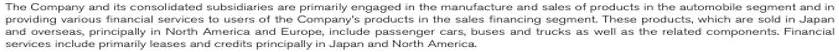

The Company and its consolidated subsidiaries are primarily engaged in the manufacture and sales of products in the automobile segment and in
providing various financial services to users of the Company’s products in the sales financing segment. These products, which are sold in Japan
and overseas,principally in North America and Europe,include passenger cars, buses and trucks as wellas therelatedcomponents.Financial
services include primarily leases and credits principally in Japan and North America.

**3. B3 — title**

Business segments

**4. B4 — text**

The business segment information for the Company and its consolidated subsidiaries for the years ended March 31,2o05,2Oo4 and 2Oo3 is as
follows:

**5. recovered:5 — text**

Fiscal vear 2oo4 (For the veac ended Mar.3r.2005)

**6. B5 — table**

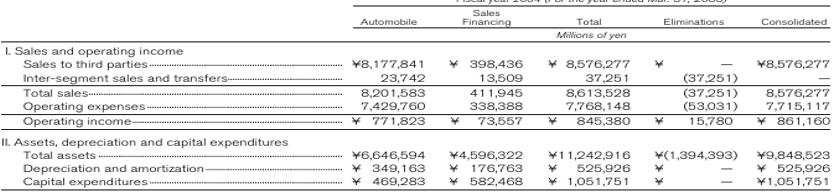

**7. recovered:4 — text**

Fiscal year 2004 (For the year ended Mar.31,2005)

**8. B6 — table**

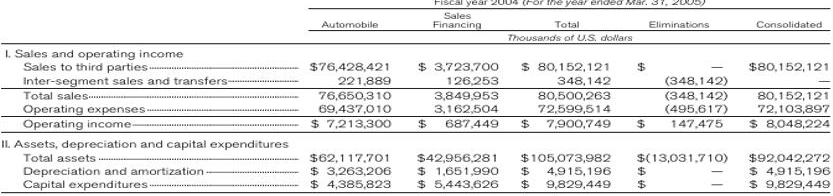

**9. recovered:3 — text**

Fiscal year 2003 (For the year endedMar.31,2004)

**10. B0 — aside_text**

FINANCIAL SECTION

**11. recovered:2 — text**

Sales
Automobile Financing

**12. recovered:1 — residual**

Total

**13. recovered:0 — residual**

Eliminations Consolidated

**14. B7 — table**

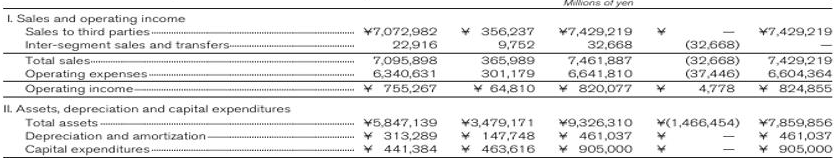

**15. B8 — number**

92

**16. B9 — footer**

92 Nissan Annual Report 2004

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\16\page_0001


**17.png · trang 1 · 34.6s · Hoàn tất: 16 vùng; 11 lượt GLM.**

## Trang 1

**16 vùng · 81 dòng · 11 lượt suy luận GLM**

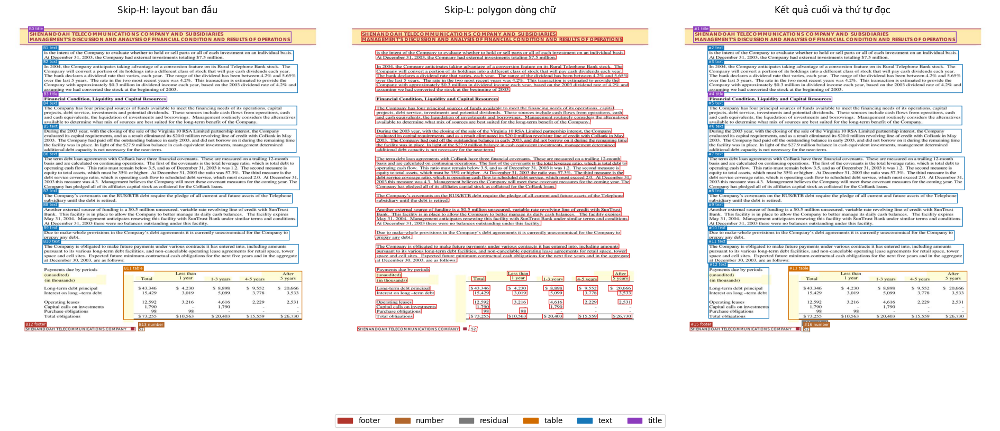

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B0,title,"(72, 44, 902, 79)",B0,2,False,SHENANDOAHTELECOMMUNICATIONSCOMPANYANDSUBSIDIA...
1,2,B1,text,"(117, 104, 909, 136)",B1,2,False,is the intentoftheCompany toevaluate whether t...
2,3,B2,text,"(117, 148, 922, 238)",B2,6,True,"In 2OO4,theCompany anticipates taking advantag..."
3,4,B3,title,"(118, 250, 510, 266)",B3,1,False,"FinancialCondition,LiquidityandCapitalResources"
4,5,B4,text,"(117, 279, 920, 340)",B4,4,False,TheCompanyhasfourprincipalsources offundsavail...
5,6,B5,text,"(118, 352, 918, 427)",B5,5,True,"During the2OO3year,withthe closingofthe saleof..."
6,7,B6,text,"(117, 440, 928, 545)",B6,7,True,The termdebtloan agreements withCoBankhave thr...
7,8,B7,text,"(117, 556, 906, 587)",B7,2,True,The Company's covenants on the RUS/RTB debt re...
8,9,B8,text,"(117, 600, 922, 660)",B8,4,True,Another externalsourceoffunding is a So.5 mill...
9,10,B9,text,"(118, 673, 896, 704)",B9,2,True,Due tomakewhole provisions in the Company’s de...


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B10,B10,text,0.7488,0.7488,0.0000,insufficient_score_gain_or_confidence
1,KEEP,abstained,B2,B2,text,0.7505,0.7505,0.0000,insufficient_score_gain_or_confidence
2,KEEP,abstained,B5,B5,text,0.7475,0.7475,0.0000,insufficient_score_gain_or_confidence
3,KEEP,abstained,B6,B6,text,0.7461,0.7461,0.0000,insufficient_score_gain_or_confidence
4,KEEP,abstained,B7,B7,text,0.7175,0.7218,0.0043,insufficient_score_gain_or_confidence
5,KEEP,abstained,B8,B8,text,0.7483,0.7483,0.0000,insufficient_score_gain_or_confidence
6,KEEP,abstained,B9,B9,text,0.7356,0.7356,0.0000,insufficient_score_gain_or_confidence
7,KEEP,abstained,recovered:0,recovered:0,residual,0.7550,0.7550,0.0000,classification_spatial_mismatch:text; classifi...
8,RELABEL,accepted,recovered:1,recovered:1,text,0.7550,0.9700,0.2150,glm_residual_classification; body_text_positio...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,verbatim target text,
1,recovered:1,1,,text,ok,Payments due by periods\n(unaudited)\n(in thou...,


### Nội dung tài liệu

# SHENANDOAHTELECOMMUNICATIONSCOMPANYANDSUBSIDIARIES
MANAGEMENT'SDISCUSSIONANDANALYSISOFFINANCIALCONDITIONANDRESULTSOFOPERATIONS

is the intentoftheCompany toevaluate whether to holdorsellparts orallofeach investmenton an individualbasis.
AtDecember31,2003,theCompanyhadexternalinvestmentstotaling$7.5million.

In 2OO4,theCompany anticipates taking advantage ofa conversion feature on itsRuralTelephoneBank stock.The
Company willconvertaportionofitsholdingsintoadifferentclassofstockthatwillpay cashdividendseachyear.
The bankdeclares adividendrate that varies,each year.Therange ofthe dividend hasbeenbetween 4.2%and5.65%
overthelast5years．Therateinthetwomostrecentyears was4.2%.Thistransactionisestimatedtoprovidethe
Companywithapproximately $o.3millionindividendincomeeachyear,basedonthe20O3dividendrateof4.2%and
assuming wehadconvertedthe stockatthebeginningof2003.

# FinancialCondition,LiquidityandCapitalResources

TheCompanyhasfourprincipalsources offundsavailable tomeetthefinancing needsofitsoperations,capital
projects,debtserviceinvestmentsandpotentialdividends.Thesesourcesincludecashflowsfromoperationcas
andcashequivalents,theliquidationofinvestmentsandborrowings.Managementroutinelyconsidersthe alternatives
availabletodeterminewhatmixofsourcesarebestsuitedforthelong-termbenefitoftheCompany.

During the2OO3year,withthe closingofthe saleoftheVirginia1ORSALimitedpartnershipinterest,theCompany
evaluateditscapitalrequirements,andasaresulteliminatedits$2O.0millionrevolvinglineofcreditwithCoBankinMay
2003.TheCompanyhadpaidofftheoutstandingbalanceinearly2OO3,anddidnotborrowonitduring theremaining time
the facilitywas in place.Inlightofthe $27.9millionbalancein cash equivalentinvestments,managementdetermined
additionaldebtcapacity is notnecessary for the near-term.

The termdebtloan agreements withCoBankhave threefinancialcovenants.These aremeasuredonatrailing12-month
basisandarecalculatedoncontinuingoperations.Thefirstofthecovenantsisthetotalleverageratio,whichistotaldebtto
operatingcashflow.Thisratiomustremainbelow3.5,andasofDecember31,2003itwas1.2.Thesecondmeasueis
equitytototalassets,whichmustbe35%orhigher.AtDecember31,2003theratiowas57.3%.Thethirdmeasureisthe
debtservicecoverage ratio,whichisoperatingcash flowto scheduleddebt service,whichmustexceed2.o.AtDecember31.
2003thismeasurewas4.3.ManagementbelievestheCompanywillmeetthesecovenantmeasuresforthe coming year.The
CompanyhaspledgedallofitsaffiliatescapitalstockascollateralfortheCoBankloans.

The Company's covenants on the RUS/RTB debt reguire the pledge ofall current and future assets of the Telephonc
subsidiary until the debt is retired.

Another externalsourceoffunding is a So.5 million unsecured,variable rate revolving line ofcredit with SunTrust
Bank.Thisfacility is in place to allow theCompanytobettermanage itsdaily cash balances.The facility expires
May31.2004.Managementanticipatesrenewing thisfacilitywith SunTrustBankunder similar terms andconditions
At December31,2003 there were no balances outstanding underthis facility.

Due tomakewhole provisions in the Company’s debt agreements itis currentlyuneconomicalfortheCompanyto
prepay any debt.

TheCompanyisobligatedtomakefuturepaymentsundervariouscontractsithasenteredinto,includingamounts
pursuanttoitsvariouslong-termdebtfacilities,andnon-cancelableoperatingleaseagreementsforretailspace,tower
space andcellsites.Expectedfuture minimum contractualcashobligationsfor the nextfive yearsandin the aggregate
at December 30,2003.are as follows:

Payments due by periods
(unaudited)
(in thousands)
Long-term debt principal
Intereston long-term det
Operating leases
Capital callson investments
Purchase obligations
Total obligations

<table><tbody><tr><td></td><td colspan="2">Less than1 year</td><td>1-3 years</td><td>4-5 years</td><td>After5 years</td></tr><tr><td></td><td>$43,346</td><td>$4,230</td><td>$8,898</td><td>$9,552</td><td>$20,666</td></tr><tr><td></td><td>15,429</td><td>3,019</td><td>5,099</td><td>3,778</td><td>3,533</td></tr><tr><td></td><td>12,592</td><td>3,216</td><td>4,616</td><td>2,229</td><td>2,531</td></tr><tr><td></td><td>1,790</td><td>-</td><td>1,790</td><td>-</td><td>-</td></tr><tr><td></td><td>98</td><td>98</td><td>-</td><td>-</td><td>-</td></tr><tr><td></td><td>$73,255</td><td>$10,563</td><td>$20,403</td><td>$15,559</td><td>$26,730</td></tr></tbody></table>

52

SHENANDOAH TELECOMMUNICATIONSCOMPANY

52

### Crop và nội dung từng vùng

**1. B0 — title**

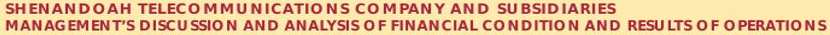

SHENANDOAHTELECOMMUNICATIONSCOMPANYANDSUBSIDIARIES
MANAGEMENT'SDISCUSSIONANDANALYSISOFFINANCIALCONDITIONANDRESULTSOFOPERATIONS

**2. B1 — text**

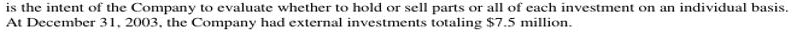

is the intentoftheCompany toevaluate whether to holdorsellparts orallofeach investmenton an individualbasis.
AtDecember31,2003,theCompanyhadexternalinvestmentstotaling$7.5million.

**3. B2 — text**

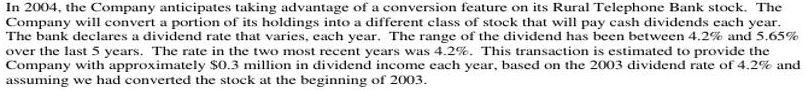

In 2OO4,theCompany anticipates taking advantage ofa conversion feature on itsRuralTelephoneBank stock.The
Company willconvertaportionofitsholdingsintoadifferentclassofstockthatwillpay cashdividendseachyear.
The bankdeclares adividendrate that varies,each year.Therange ofthe dividend hasbeenbetween 4.2%and5.65%
overthelast5years．Therateinthetwomostrecentyears was4.2%.Thistransactionisestimatedtoprovidethe
Companywithapproximately $o.3millionindividendincomeeachyear,basedonthe20O3dividendrateof4.2%and
assuming wehadconvertedthe stockatthebeginningof2003.

**4. B3 — title**

FinancialCondition,LiquidityandCapitalResources

**5. B4 — text**

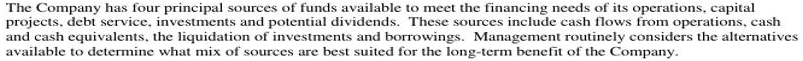

TheCompanyhasfourprincipalsources offundsavailable tomeetthefinancing needsofitsoperations,capital
projects,debtserviceinvestmentsandpotentialdividends.Thesesourcesincludecashflowsfromoperationcas
andcashequivalents,theliquidationofinvestmentsandborrowings.Managementroutinelyconsidersthe alternatives
availabletodeterminewhatmixofsourcesarebestsuitedforthelong-termbenefitoftheCompany.

**6. B5 — text**

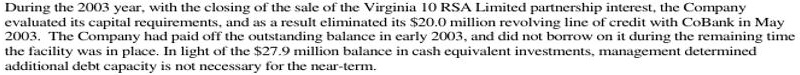

During the2OO3year,withthe closingofthe saleoftheVirginia1ORSALimitedpartnershipinterest,theCompany
evaluateditscapitalrequirements,andasaresulteliminatedits$2O.0millionrevolvinglineofcreditwithCoBankinMay
2003.TheCompanyhadpaidofftheoutstandingbalanceinearly2OO3,anddidnotborrowonitduring theremaining time
the facilitywas in place.Inlightofthe $27.9millionbalancein cash equivalentinvestments,managementdetermined
additionaldebtcapacity is notnecessary for the near-term.

**7. B6 — text**

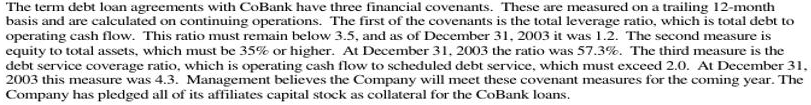

The termdebtloan agreements withCoBankhave threefinancialcovenants.These aremeasuredonatrailing12-month
basisandarecalculatedoncontinuingoperations.Thefirstofthecovenantsisthetotalleverageratio,whichistotaldebtto
operatingcashflow.Thisratiomustremainbelow3.5,andasofDecember31,2003itwas1.2.Thesecondmeasueis
equitytototalassets,whichmustbe35%orhigher.AtDecember31,2003theratiowas57.3%.Thethirdmeasureisthe
debtservicecoverage ratio,whichisoperatingcash flowto scheduleddebt service,whichmustexceed2.o.AtDecember31.
2003thismeasurewas4.3.ManagementbelievestheCompanywillmeetthesecovenantmeasuresforthe coming year.The
CompanyhaspledgedallofitsaffiliatescapitalstockascollateralfortheCoBankloans.

**8. B7 — text**

The Company's covenants on the RUS/RTB debt reguire the pledge ofall current and future assets of the Telephonc
subsidiary until the debt is retired.

**9. B8 — text**

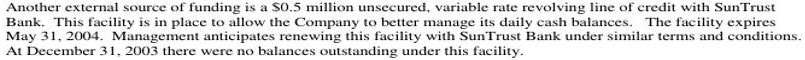

Another externalsourceoffunding is a So.5 million unsecured,variable rate revolving line ofcredit with SunTrust
Bank.Thisfacility is in place to allow theCompanytobettermanage itsdaily cash balances.The facility expires
May31.2004.Managementanticipatesrenewing thisfacilitywith SunTrustBankunder similar terms andconditions
At December31,2003 there were no balances outstanding underthis facility.

**10. B9 — text**

Due tomakewhole provisions in the Company’s debt agreements itis currentlyuneconomicalfortheCompanyto
prepay any debt.

**11. B10 — text**

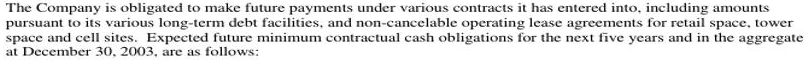

TheCompanyisobligatedtomakefuturepaymentsundervariouscontractsithasenteredinto,includingamounts
pursuanttoitsvariouslong-termdebtfacilities,andnon-cancelableoperatingleaseagreementsforretailspace,tower
space andcellsites.Expectedfuture minimum contractualcashobligationsfor the nextfive yearsandin the aggregate
at December 30,2003.are as follows:

**12. recovered:1 — text**

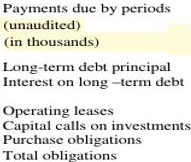

Payments due by periods
(unaudited)
(in thousands)
Long-term debt principal
Intereston long-term det
Operating leases
Capital callson investments
Purchase obligations
Total obligations

**13. B11 — table**

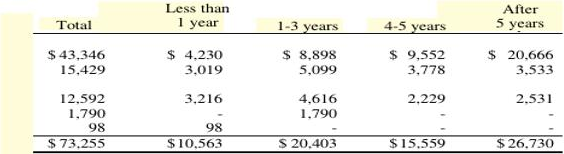

**14. recovered:0 — residual**

52

**15. B12 — footer**

SHENANDOAH TELECOMMUNICATIONSCOMPANY

**16. B13 — number**

52

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\17\page_0001


**18.png · trang 1 · 35.9s · Hoàn tất: 27 vùng; 21 lượt GLM.**

## Trang 1

**27 vùng · 128 dòng · 21 lượt suy luận GLM**

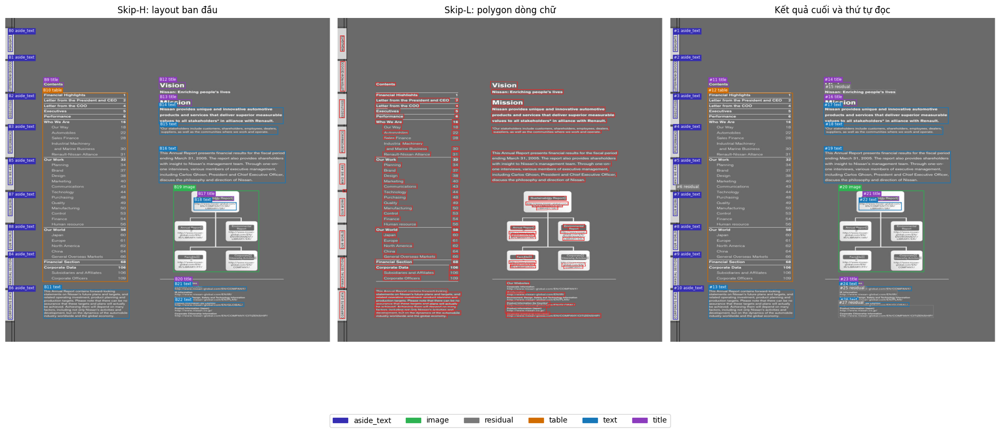

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B0,aside_text,"(8, 53, 23, 108)",B0,1,False,HIGHUGHTS
1,2,B1,aside_text,"(8, 137, 23, 235)",B1,1,False,LETTER FROM CEOICOO
2,3,B2,aside_text,"(8, 259, 22, 319)",B2,1,False,EXECUTIVES
3,4,B3,aside_text,"(8, 356, 22, 429)",B3,1,False,PERFORMANCE
4,5,B5,aside_text,"(8, 463, 23, 529)",B5,1,False,WHO WE ARE
5,6,recovered:2,residual,"(17, 543, 27, 552)",recovered:2,1,True,+
6,7,B7,aside_text,"(8, 570, 22, 627)",B7,1,False,Co
7,8,B8,aside_text,"(8, 672, 23, 734)",B8,1,False,Co
8,9,B4,aside_text,"(8, 759, 24, 854)",B4,1,False,FINANCIAL SECTION
9,10,B6,aside_text,"(8, 866, 23, 954)",B6,1,False,CORPORATE DATA


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B11,B11,text,0.7422,0.7422,0.0,insufficient_score_gain_or_confidence
1,KEEP,abstained,B14,B14,text,0.7371,0.7371,0.0,insufficient_score_gain_or_confidence
2,KEEP,abstained,B15,B15,text,0.7472,0.7472,0.0,insufficient_score_gain_or_confidence
3,KEEP,abstained,B16,B16,text,0.7505,0.7505,0.0,insufficient_score_gain_or_confidence
4,KEEP,abstained,B19,B19,image,0.7550,0.7550,0.0,split_content_loss; content_loss_or_hallucinat...
5,KEEP,abstained,B22,B22,text,0.6907,0.6907,0.0,content_loss_or_hallucination; insufficient_sc...
6,KEEP,abstained,recovered:0,recovered:0,residual,0.7550,0.7550,0.0,independent_transcripts_unavailable; classific...
7,KEEP,abstained,recovered:1,recovered:1,residual,0.7550,0.7550,0.0,classification_transcript_mismatch; insufficie...
8,KEEP,abstained,recovered:2,recovered:2,residual,0.7550,0.7550,0.0,classification_spatial_mismatch:text; classifi...
9,KEEP,abstained,recovered:3,recovered:3,residual,0.7550,0.7550,0.0,classification_spatial_mismatch:text; insuffic...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,Product Information (Japan)\nhttp://www.nissan...,
1,recovered:1,1,,text,ok,verbatim target text,
2,recovered:2,1,,text,ok,verbatim target text,
3,recovered:3,1,,text,ok,Nissan: Enriching people's lives,


... (22 outputs left out)

CORPORATE DATA

**11. B9 — title**

Contents

**12. B10 — table**

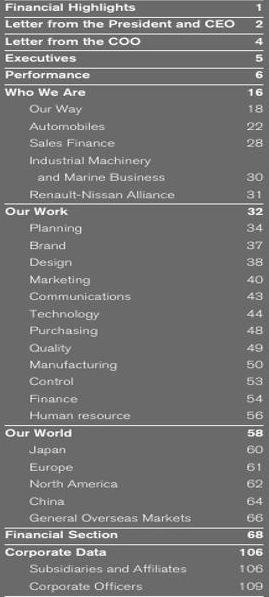

Financial Highlights,1
Letter from the President and CEO,2
Letter from the COO,4
Executives,5
Performance,6
Who We Are,16
Our Way,18
Automobiles,22
Sales Finance,28
Industrial Machinery and Marine Business,30
Renault-Nissan Alliance,31


**13. B11 — text**

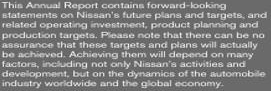

Thin Annual Report containsforward-looking
statements on Nissan's future plans and targets,and
related operating investment, product planning and
production targets.Piease note that there can be no
assurance that these targets and plans will actually
be achieved.Achieving thom will depend on many
factors,including not only Nissan's activiies and
development, but on the dynamics of the automobile
industry woridwide and the global econamy.

**14. B12 — title**

Vision

**15. recovered:3 — residual**

Nissan: Enriching people's lives

**16. B13 — title**

Mission

**17. B14 — text**

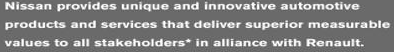

Nissan provides unique and innovative automotive
products and services that deliver superior measurable
values to all stakeholders* in alliance with Renault.

**18. B15 — text**

Our stakeholders include customers,shareholders,employees,dealers
suppliers, as well as the communities where we work and operate.

**19. B16 — text**

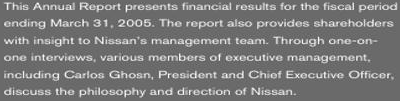

This Annual Report presents financial results for the fiscal period
ending March 31,2005. The report also provides shareholders
with insight to Nissan's management team. Through one-on-
one interviews, various members of executive management.
including Carlos Ghosn, President and Chiof Executive Officer,
discuss the philosophy and direction of Nissan.

**20. B19 — image**

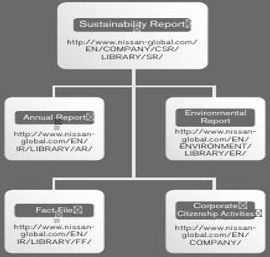

Sustainability Repon
http://www.nissan-giobal.com
Ervironmental
Annual Report
Roport
http://www.nissm
http://ww.nissan
global.com/EN/
IR/LIBRARY/AR/
LIBRARY/ER/
FactEe
http://www.niss
global.com/EN/
global.com/EN/
IR/LIBRARY/FF/
COMPANY/

Đang xem 20/27 crop. Đặt MAX_REGION_PREVIEWS=None để xem toàn bộ.

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\18\page_0001


**19.png · trang 1 · 52.6s · Hoàn tất: 6 vùng; 4 lượt GLM.**

## Trang 1

**6 vùng · 220 dòng · 4 lượt suy luận GLM**

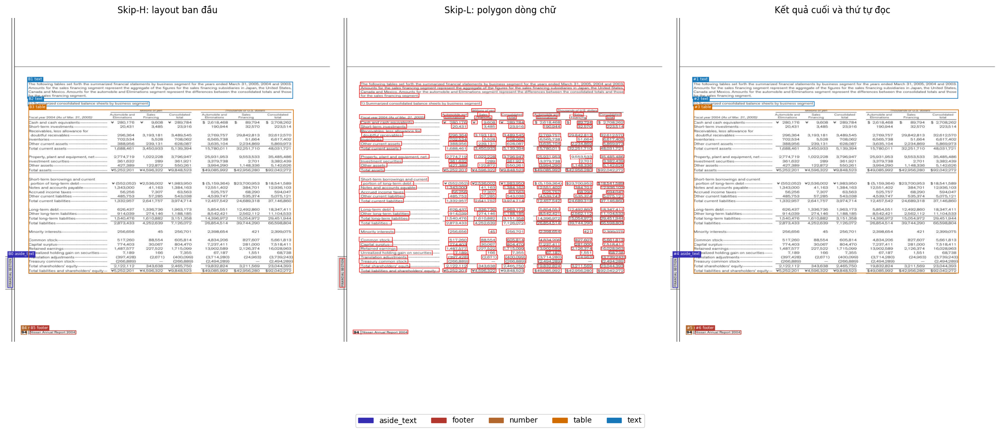

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B1,text,"(69, 203, 907, 256)",B1,4,False,The following tables set forth the summarized ...
1,2,B2,text,"(71, 265, 454, 280)",B2,1,True,1) Summarized consolidated balance sheets by b...
2,3,B3,table,"(73, 291, 909, 808)",B3,213,False,Milions of yen\nThousands of U.S. dodars\nSale...
3,4,B0,aside_text,"(7, 758, 23, 854)",B0,1,False,FINANCIAL SECTION
4,5,B4,number,"(49, 989, 68, 1002)",B4,0,False,94
5,6,B5,footer,"(77, 989, 223, 1001)",B5,1,False,94 Nissan Annual Report 2004


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B2,B2,text,0.7282,0.7282,0.0,insufficient_score_gain_or_confidence


### Cảnh báo
- incomplete:B3
- incomplete:parse:B3:Generation reached max_new_tokens; increase the limit if memory permits.

,hypothesis_id,status,error
0,parse:B3,incomplete,Generation reached max_new_tokens; increase th...


### Nội dung tài liệu

The following tables set forth the summarized financial statements by business segment for the years ended March 31,2oo5,2Oo4 and 2003.
Amounts for the sales financing segment represent the aggregate of the figures for the sales financing subsidiaries in Japan,the United States,
Canada and Mexico.Amounts for the autamobile and Eliminations segment represent the differences between the consolidated totals and those
for the sales financing segment.

1) Summarized consolidated balance sheets by business segment

Milions of yen
Thousands of U.S. dodars
Sales
Automobile and
Consolidated
Sales
Autamobile and
Consolidated
Fiscal year 2004 (As of Mar.31,2005)
Financing
Eliminations
Financing
total
Eliminations
total
￥
9,608
$
￥280.176
￥289.784
$2,618,468
$2,708,262
Cash and cash eguivalents
89.794
Short-term investments
20,431
3,485
23,916
190,944
32.570
223.514
Receivables.less allowance for
doubtful receivables
296,364
3,193,181
3,489,545
2,769,757
29,842.813
32.612.570
6,565,738
5,528
51,664
Inventories
702,534
708,062
6,617,402
239,131
Other current assets
388,956
628,087
3,635,104
2,234,869
5,869,973
1,688,461
Total current assets
3,450,933
5,139,394
15,780,011
32,251,710
48,031,721
9,553,533
2,774,719
Property,plant and equipment, net-
1,022.228
3.796.947
25,931.953
35,485,486
3,379,738
289
Investment securities
2,701
361,632
361.921
3,382,439
Other assets-
122,872
550,261
427.389
3,994,290
1,148,336
5,142,626
Total assets
￥5,252.201
￥4.596.322
￥9.848.523
$92,042,272
$49,085.992
$42.956.280
Short-term borrowings and current
￥(552,052)
portion of long-term debt-
$(5,159,364)
$23,700,953
￥2,536,002
￥1,983,950
$18,541,589
Notes and accounts payable
41,163
1.343.000
1.384.163
12.551.402
384.701
12936.103
Accrued income taxes
7,307
56.256
63.563
525.757
68.290
594.047
Other current liabilities
485,753
57,285
543,038
4.539.747
535.374
5,075,121
Total current liabilities
1,332,957
2.641.757
3.974.714
12,457,542
24,689,318
37,146,860
626,437
Long-term debt-
5.854.551
12.492.860
18.347.411
1,336,736
1,963,173
914,039
Other long-term liabilities
274,146
1,188,185
8,542,421
2,562,112
11,104,533
14,396,972
Total long-term liabilities
1,540,476
1,610,882
3,151,358
15,054,972
29,451,944
7,126,072
4,252,639
Total liabilities
2,873,433
26,854,514
39,744,290
66,598,804
Minority interests
256,656
256,701
45
421
2.399.075
2,398,654
Common stock
517,260
88,554
4.834.206
605.814
827,607
5,661,813
Capital surplus…
774.403
30,067
804.470
7,237,411
7.518.411
281,000
1,487,577
227,522
Retained earnings
1,715,099
13,902,589
2,126,374
16,028,963
Unrealized holding gain on securities
7,189
166
7,355
1,551
67,187
68.738
(397,428)
Translation adjustments
(2,671)
(400,099)
(3,714,280)
（24.963）
(3,739,243)
Treasury common stock
(266,889)
(266,889)
(2,494,289)
（2,494,289
2,122,112
2,465,750
Total shareholdersequity
343,638
19,832,824
3,211,569
23,044,393
Total liabilities and shareholders'equity.…
￥9,848,523
￥5,252.201
$49,085,992
$42,956,280
$92,042,272
￥4,596,322

FINANCIAL SECTION

94

94 Nissan Annual Report 2004

### Crop và nội dung từng vùng

**1. B1 — text**

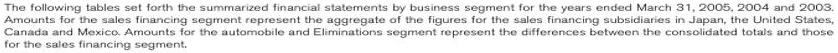

The following tables set forth the summarized financial statements by business segment for the years ended March 31,2oo5,2Oo4 and 2003.
Amounts for the sales financing segment represent the aggregate of the figures for the sales financing subsidiaries in Japan,the United States,
Canada and Mexico.Amounts for the autamobile and Eliminations segment represent the differences between the consolidated totals and those
for the sales financing segment.

**2. B2 — text**

1) Summarized consolidated balance sheets by business segment

**3. B3 — table**

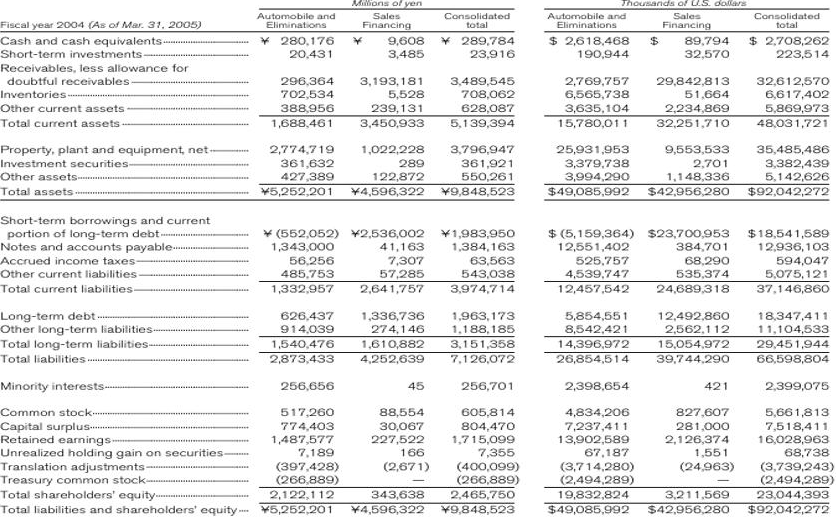

**4. B0 — aside_text**

FINANCIAL SECTION

**5. B4 — number**

94

**6. B5 — footer**

94 Nissan Annual Report 2004

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\19\page_0001


**20.png · trang 1 · 11.5s · Hoàn tất: 8 vùng; 6 lượt GLM.**

## Trang 1

**8 vùng · 39 dòng · 6 lượt suy luận GLM**

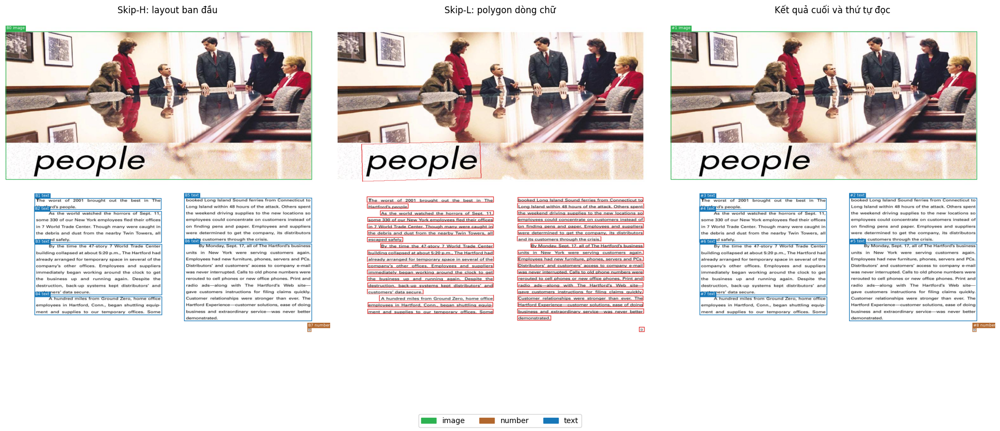

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B0,image,"(1, 44, 967, 512)",B0,1,False,people
1,2,B5,text,"(564, 570, 967, 711)",B5,7,True,booked Long lsland Sound ferries from Connecti...
2,3,B1,text,"(92, 571, 492, 607)",B1,2,True,The worst of 2001 brought out the best in The\...
3,4,B2,text,"(91, 612, 493, 711)",B2,5,True,"As the world watched the horrors of Sept. 11,\..."
4,5,B6,text,"(564, 715, 967, 959)",B6,12,True,"By Monday, Sept. 17,all of The Hartford's busi..."
5,6,B3,text,"(92, 716, 494, 877)",B3,8,True,By the time the 47-story 7 World Trade Center\...
6,7,B4,text,"(92, 882, 494, 940)",B4,3,True,"A hundred miles from Ground Zero, home office\..."
7,8,B7,number,"(953, 981, 965, 993)",B7,1,False,9


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B1,B1,text,0.7029,0.7231,0.0202,insufficient_score_gain_or_confidence
1,KEEP,abstained,B2,B2,text,0.7450,0.7450,0.0000,insufficient_score_gain_or_confidence
2,KEEP,abstained,B3,B3,text,0.7456,0.7456,0.0000,insufficient_score_gain_or_confidence
3,KEEP,abstained,B4,B4,text,0.7238,0.7242,0.0004,insufficient_score_gain_or_confidence
4,KEEP,abstained,B5,B5,text,0.7479,0.7479,0.0000,insufficient_score_gain_or_confidence
5,KEEP,abstained,B6,B6,text,0.7505,0.7505,0.0000,insufficient_score_gain_or_confidence


### Nội dung tài liệu

people

booked Long lsland Sound ferries from Connecticut to
Long lsland within 48 hours of the attack. Others spent
the weekend driving supplies to the new locations so
employees could concentrate on customers instead of
on finding pens and paper. Employees and suppliers
were determined to get the company, its distributors
and its customers through the crisis.

The worst of 2001 brought out the best in The
Hartford's people

As the world watched the horrors of Sept. 11,
some 33o of our New York employees fled their offices
in 7 World Trade Center. Though many were caught in
the debris and dust from the nearby Twin Towers, all
escaped safely.

By Monday, Sept. 17,all of The Hartford's business
units in New York were serving customers again.
Employees had new furniture, phones, servers and PCs.
Distributors' and customers'access to company e-mail
was never interrupted. Calls to old phone numbers were
rerouted to cell phones or new office phones. Print and
radio ads-along with The Hartford's Web site—
gave customers instructions for filing claims quickly.
Customer relationships were stronger than ever. The
Hartford Experience-customer solutions, ease of doing
business and extraordinary service-was never better
demonstrated.

By the time the 47-story 7 World Trade Center
building collapsed at about 5:2O p.m., The Hartford had
already arranged for temporary space in several of the
company's other offices. Employees and suppliers
immediately began working around the clock to get
the business up and running again. Despite the
destruction, back-up systems kept distributors' and
customers' data secure.

A hundred miles from Ground Zero, home office
employees in Hartford, Conn., began shuttling equip-
ment and supplies to our temporary offices. Some

9

### Crop và nội dung từng vùng

**1. B0 — image**

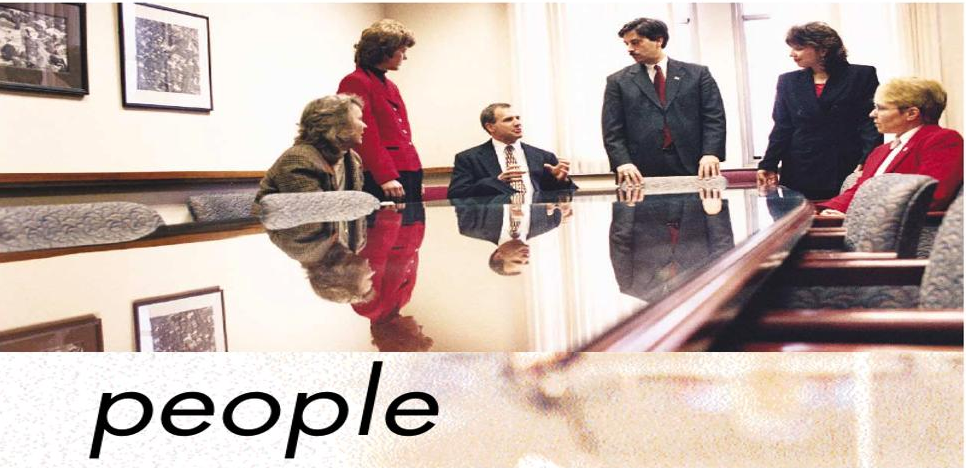

people

**2. B5 — text**

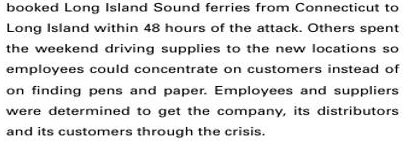

booked Long lsland Sound ferries from Connecticut to
Long lsland within 48 hours of the attack. Others spent
the weekend driving supplies to the new locations so
employees could concentrate on customers instead of
on finding pens and paper. Employees and suppliers
were determined to get the company, its distributors
and its customers through the crisis.

**3. B1 — text**

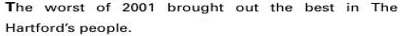

The worst of 2001 brought out the best in The
Hartford's people

**4. B2 — text**

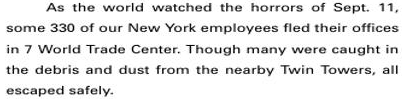

As the world watched the horrors of Sept. 11,
some 33o of our New York employees fled their offices
in 7 World Trade Center. Though many were caught in
the debris and dust from the nearby Twin Towers, all
escaped safely.

**5. B6 — text**

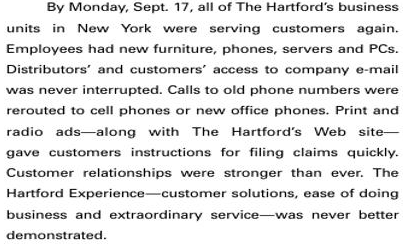

By Monday, Sept. 17,all of The Hartford's business
units in New York were serving customers again.
Employees had new furniture, phones, servers and PCs.
Distributors' and customers'access to company e-mail
was never interrupted. Calls to old phone numbers were
rerouted to cell phones or new office phones. Print and
radio ads-along with The Hartford's Web site—
gave customers instructions for filing claims quickly.
Customer relationships were stronger than ever. The
Hartford Experience-customer solutions, ease of doing
business and extraordinary service-was never better
demonstrated.

**6. B3 — text**

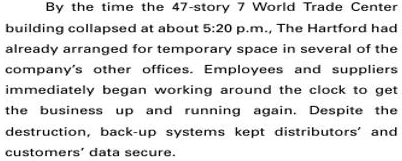

By the time the 47-story 7 World Trade Center
building collapsed at about 5:2O p.m., The Hartford had
already arranged for temporary space in several of the
company's other offices. Employees and suppliers
immediately began working around the clock to get
the business up and running again. Despite the
destruction, back-up systems kept distributors' and
customers' data secure.

**7. B4 — text**

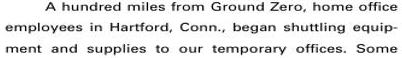

A hundred miles from Ground Zero, home office
employees in Hartford, Conn., began shuttling equip-
ment and supplies to our temporary offices. Some

**8. B7 — number**

9

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\20\page_0001


**21.png · trang 1 · 13.1s · Hoàn tất: 10 vùng; 9 lượt GLM.**

## Trang 1

**10 vùng · 40 dòng · 9 lượt suy luận GLM**

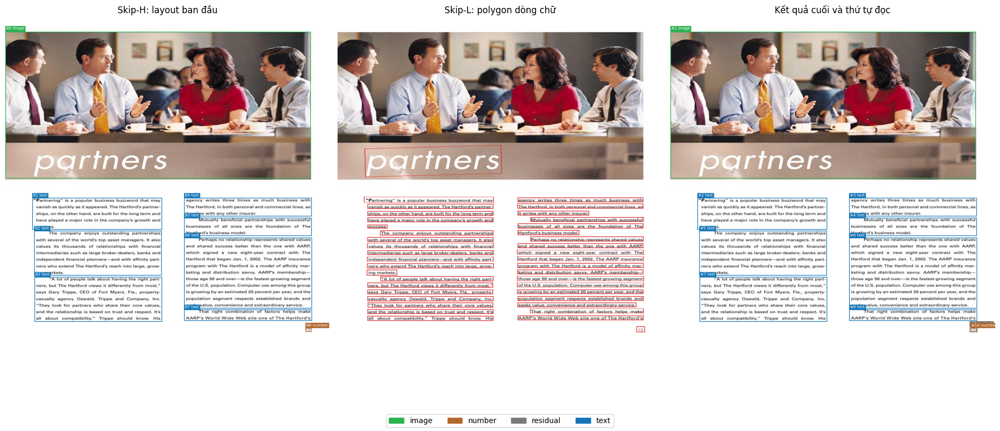

### Thông tin vùng

,order,id,label,bbox,sources,lines,needs_review,content
0,1,B0,image,"(0, 45, 963, 508)",B0,1,False,partners
1,2,B1,text,"(85, 570, 494, 670)",B1,5,True,"""Partnering"" is a popular business buzzword th..."
2,3,B4,text,"(564, 570, 966, 628)",B4,3,True,agency writes three times as much business wit...
3,4,B5,text,"(564, 633, 966, 690)",B5,3,True,Mutually beneficial partnerships with successf...
4,5,B2,text,"(91, 674, 493, 815)",B2,7,True,The company enjoys outstanding partnerships\nw...
5,6,B6,text,"(564, 696, 967, 919)",B6,11,True,Perhaps no relationship represents shared valu...
6,7,B3,text,"(92, 820, 494, 961)",B3,7,True,"""A lot of people talk about having the right p..."
7,8,B7,text,"(564, 923, 967, 958)",B7,2,True,That right combination of factors helps make\n...
8,9,recovered:0,residual,"(944, 976, 968, 994)",recovered:0,1,True,13
9,10,B8,number,"(947, 981, 966, 993)",B8,0,False,13


### Các thay đổi và quyết định

,action,status,sources,target,label,baseline_score,score,gain,reasons
0,KEEP,abstained,B1,B1,text,0.7403,0.7403,0.0000,insufficient_score_gain_or_confidence
1,KEEP,abstained,B2,B2,text,0.7514,0.7514,0.0000,insufficient_score_gain_or_confidence
2,KEEP,abstained,B3,B3,text,0.7479,0.7479,0.0000,insufficient_score_gain_or_confidence
3,KEEP,abstained,B4,B4,text,0.7461,0.7461,0.0000,insufficient_score_gain_or_confidence
4,KEEP,abstained,B5,B5,text,0.7371,0.7371,0.0000,insufficient_score_gain_or_confidence
5,KEEP,abstained,B6,B6,text,0.7459,0.7459,0.0000,insufficient_score_gain_or_confidence
6,KEEP,abstained,B7,B7,text,0.7113,0.7250,0.0137,insufficient_score_gain_or_confidence
7,KEEP,abstained,recovered:0,recovered:0,residual,0.7550,0.7550,0.0000,classification_spatial_mismatch:text; classifi...


### Nhãn GLM đề xuất cho vùng chưa có nhãn

,region,attempt,normalization,proposed_label,status,text,error
0,recovered:0,1,,text,ok,verbatim target text,


### Nội dung tài liệu

partners

"Partnering" is a popular business buzzword that may
vanish as quickly as it appeared. The Hartford's partner-
ships, on the other hand,are built for the long term and
have played a major role in the company's growth and
success.

agency writes three times as much business with
The Hartford, in both personal and commercial lines.as
it writes with any other insurer.

Mutually beneficial partnerships with successful
businesses of all sizes are the foundation of The
Hartford's business model.

The company enjoys outstanding partnerships
with several of the world's top asset managers.It also
values its thousands of relationships with financial
intermediaries such as large broker-dealers, banks and
independent financial planners-and with affinity part-
ners who extend The Hartford's reach into large, grow-
ing markets.

Perhaps no relationship represents shared values
and shared success better than the one with AARP,
which signed a new eight-year contract with The
Hartford that began Jan.1,2002. The AARP insurance
program with The Hartford is a model of affinity mar-
keting and distribution savvy. AARP's membership—
those age 50 and over—is the fastest-growing segment
of the U.S.population. Computer use among this group
is growing by an estimated 2o percent per year,and the
population segment respects established brands and
seeks value, convenience and extraordinary service.

"A lot of people talk about having the right part-
ners, but The Hartford views it differently from most,"
says Gary Trippe,CEO of Fort Myers,Fla.,property-
casualty agency Oswald, Trippe and Company, Inc.
"They look for partners who share their core values,
and the relationship is based on trust and respect. It's
all about compatibility.”Trippe should know.His

That right combination of factors helps make
AARP's World Wide Web site one of The Hartford's

13

13

### Crop và nội dung từng vùng

**1. B0 — image**

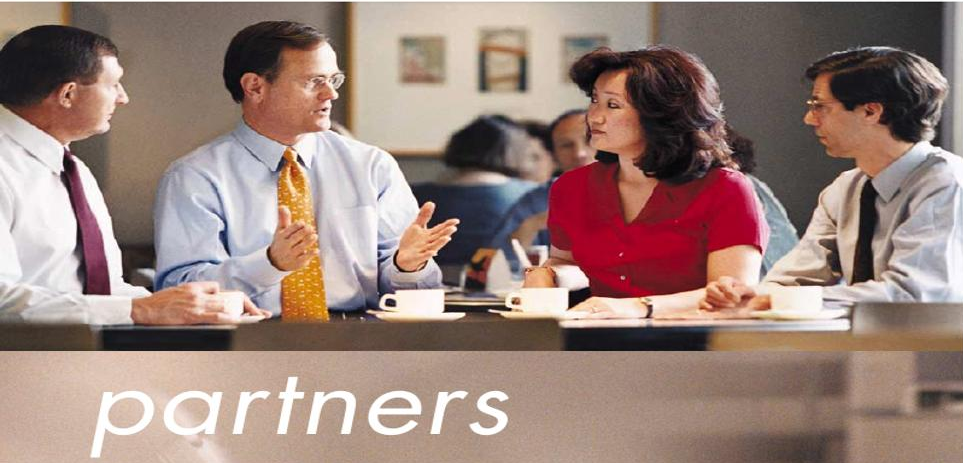

partners

**2. B1 — text**

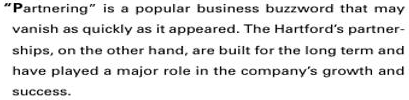

"Partnering" is a popular business buzzword that may
vanish as quickly as it appeared. The Hartford's partner-
ships, on the other hand,are built for the long term and
have played a major role in the company's growth and
success.

**3. B4 — text**

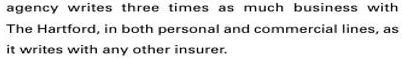

agency writes three times as much business with
The Hartford, in both personal and commercial lines.as
it writes with any other insurer.

**4. B5 — text**

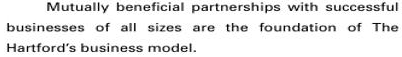

Mutually beneficial partnerships with successful
businesses of all sizes are the foundation of The
Hartford's business model.

**5. B2 — text**

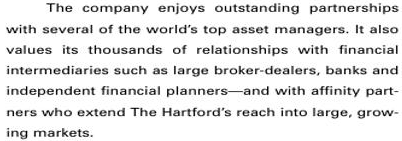

The company enjoys outstanding partnerships
with several of the world's top asset managers.It also
values its thousands of relationships with financial
intermediaries such as large broker-dealers, banks and
independent financial planners-and with affinity part-
ners who extend The Hartford's reach into large, grow-
ing markets.

**6. B6 — text**

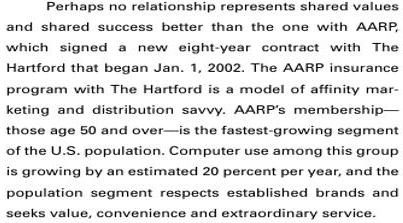

Perhaps no relationship represents shared values
and shared success better than the one with AARP,
which signed a new eight-year contract with The
Hartford that began Jan.1,2002. The AARP insurance
program with The Hartford is a model of affinity mar-
keting and distribution savvy. AARP's membership—
those age 50 and over—is the fastest-growing segment
of the U.S.population. Computer use among this group
is growing by an estimated 2o percent per year,and the
population segment respects established brands and
seeks value, convenience and extraordinary service.

**7. B3 — text**

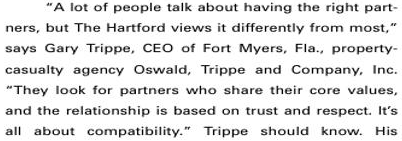

"A lot of people talk about having the right part-
ners, but The Hartford views it differently from most,"
says Gary Trippe,CEO of Fort Myers,Fla.,property-
casualty agency Oswald, Trippe and Company, Inc.
"They look for partners who share their core values,
and the relationship is based on trust and respect. It's
all about compatibility.”Trippe should know.His

**8. B7 — text**

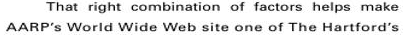

That right combination of factors helps make
AARP's World Wide Web site one of The Hartford's

**9. recovered:0 — residual**

13

**10. B8 — number**

13

Đã lưu: D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\21\page_0001


In [10]:
import time
from html import escape
from src.notebook_visuals import display_page_result, export_page_result
from src.adapters.paddle_worker import PaddleEnvironmentError

results, summary_records, stage_events, exported_paths = [], [], [], []
processed_pages = 0
try:
    for page in document_pages:
        document_path = page.source_path
        processed_pages += 1
        started = time.perf_counter()
        status = display(Markdown(f"**{escape(document_path.name)} · trang {page.page_number}: bắt đầu…**"), display_id=True)
        def on_progress(stage, message):
            elapsed = time.perf_counter() - started
            stage_events.append({"tài liệu": document_path.name, "trang": page.page_number, "giai đoạn": stage,
                                 "giây từ đầu trang": round(elapsed, 3), "thông báo": message})
            status.update(Markdown(f"**{escape(document_path.name)} · trang {page.page_number} · {elapsed:.1f}s · {escape(message)}**"))
        try:
            page_config = config | {"document_id": document_path.stem, "page_index": page.page_number - 1}
            result = await parse_page(page.image, page_config, *adapters, progress_callback=on_progress)
            elapsed = time.perf_counter() - started
            results.append(result)
            display_page_result(page.image, result, max_region_previews=MAX_REGION_PREVIEWS,
                                mock_mode=MOCK_MODE)
            output = export_page_result(page.image, result, OUTPUT_ROOT, document_path.stem) if SAVE_OUTPUTS else None
            if output is not None:
                exported_paths.append(str(output))
                print("Đã lưu:", output)
            summary_records.append({"tài liệu": document_path.name, "trang": page.page_number, "chế độ": "MOCK" if MOCK_MODE else "REAL",
                "trạng thái": "có cảnh báo" if result.warnings else "hoàn tất", "giây suy luận": round(elapsed, 2),
                "vùng": len(result.final_regions), "lượt GLM": result.glm_requests,
                "residual còn lại": sum(r.label_final in ("residual", "unknown", "unlabeled", "") for r in result.final_regions),
                "đổi nhãn được chấp nhận": sum(r.action == "RELABEL" and r.status == "accepted" for r in result.revisions),
                "cảnh báo": len(result.warnings), "thư mục": str(output or "không lưu")})
        except Exception as exc:
            elapsed = time.perf_counter() - started
            status.update(Markdown(f"**{escape(document_path.name)} · trang {page.page_number} lỗi: {escape(str(exc))}**"))
            summary_records.append({"tài liệu": document_path.name, "trang": page.page_number, "chế độ": "MOCK" if MOCK_MODE else "REAL",
                "trạng thái": "LỖI", "giây suy luận": round(elapsed, 2), "lỗi": str(exc)})
            if isinstance(exc, PaddleEnvironmentError):
                raise  # Stop on DLL/import failure instead of repeating it for every page.
finally:
    page_iterator.close()
if not processed_pages:
    raise RuntimeError("Danh sách trang đã chạy hết. Chạy lại cell nạp ảnh/PDF rồi chạy cell này.")


## 6. Tổng hợp và vị trí kết quả

In [11]:
display(pd.DataFrame(summary_records))
display(Markdown("### Nhật ký tiến độ từng giai đoạn"))
display(pd.DataFrame(stage_events))
if exported_paths:
    print("Các thư mục đã xuất:")
    print("\n".join(exported_paths))
print("results chứa các PageParseResult để tiếp tục phân tích.")


,tài liệu,trang,chế độ,trạng thái,giây suy luận,vùng,lượt GLM,residual còn lại,đổi nhãn được chấp nhận,cảnh báo,thư mục
0,1.png,1,REAL,hoàn tất,23.26,8,7,1,1,0,D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chu...
1,2.png,1,REAL,hoàn tất,55.31,12,10,1,1,0,D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chu...
2,3.png,1,REAL,hoàn tất,36.26,20,18,2,0,0,D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chu...
3,4.png,1,REAL,hoàn tất,17.84,16,12,1,0,0,D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chu...
4,5.png,1,REAL,hoàn tất,106.75,18,16,1,1,0,D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chu...
5,6.png,1,REAL,hoàn tất,107.55,12,8,0,0,0,D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chu...
6,7.png,1,REAL,hoàn tất,18.10,17,13,5,1,0,D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chu...
7,8.png,1,REAL,hoàn tất,44.61,12,9,1,1,0,D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chu...
8,9.png,1,REAL,hoàn tất,77.11,21,15,0,0,0,D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chu...
9,10.png,1,REAL,hoàn tất,42.03,14,11,1,0,0,D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chu...


### Nhật ký tiến độ từng giai đoạn

,tài liệu,trang,giai đoạn,giây từ đầu trang,thông báo
0,1.png,1,spatial,0.004,Đang phát hiện layout và các dòng chữ…
1,1.png,1,light_ocr,9.965,Đang nhận dạng từng dòng bằng PaddleOCR…
2,1.png,1,graph,13.740,"Đã dựng graph: 8 vùng, 33 dòng chữ."
3,1.png,1,recognition,13.742,Đang nhận dạng 2 vùng cần GLM…
4,1.png,1,residual_classification,15.657,Đang đưa vùng chưa có nhãn qua GLM phân loại v...
...,...,...,...,...,...
155,21.png,1,recognition,1.671,Đang nhận dạng 1 vùng cần GLM…
156,21.png,1,residual_classification,1.985,Đang đưa vùng chưa có nhãn qua GLM phân loại v...
157,21.png,1,semantic,2.538,Đang kiểm chứng giả thuyết: 7 crop.
158,21.png,1,assembly,13.100,Đang kiểm tra ràng buộc và lắp ráp kết quả…


Các thư mục đã xuất:
D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\1\page_0001
D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\2\page_0001
D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\3\page_0001
D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\4\page_0001
D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\5\page_0001
D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\6\page_0001
D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\7\page_0001
D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\8\page_0001
D:\Học kì 1 năm 4\Đồ án chuyên ngành\Do-an-chuyen-nganh-261\method2\outputs\notebook_residual_glm\9

## 7. Báo cáo định lượng trên DocLayNet

Cell chỉ đọc prediction đã lưu, không chạy lại mô hình. So sánh baseline và final
trên cùng snapshot; mặc định gộp Title + Section-header ở cả hai phía (10 lớp).
Accuracy là accuracy phân loại trên bbox đã ghép, không phải accuracy OCR.
Chỉ số thuộc tập ảnh đang có; chưa thể so trực tiếp với benchmark Docling/M2Doc
khác dataset, split hoặc protocol. Không tự tạo mAP khi thiếu confidence phù hợp.

In [ ]:
# Cell độc lập: chạy được trên kernel mới, không cần nạp mô hình.
import sys
from pathlib import Path
from datetime import datetime, timezone, timedelta
from IPython.display import display, Markdown, HTML
import pandas as pd

report_candidates = [p for base in (Path.cwd(), *Path.cwd().parents)
                     for p in (base, base / "method2")]
METHOD2_ROOT = next((p.resolve() for p in report_candidates
                    if (p / "src/evaluation/notebook_report.py").is_file()
                    and (p / "configs/default.yaml").is_file()), None)
if METHOD2_ROOT is None:
    raise RuntimeError("Mở notebook từ thư mục repository hoặc method2 để tìm kết quả đã lưu.")
if str(METHOD2_ROOT) not in sys.path:
    sys.path.insert(0, str(METHOD2_ROOT))
report_src = sys.modules.get("src")
if report_src is not None and (getattr(report_src, "__file__", None) is None or
        Path(report_src.__file__).resolve().parent != METHOD2_ROOT / "src"):
    raise RuntimeError("Kernel đã nạp package src khác. Restart Kernel rồi chạy riêng cell báo cáo này.")
from importlib import reload
from src.evaluation import notebook_report as layout_report
layout_report = reload(layout_report)  # Chỉ nạp lại helper báo cáo, không nạp lại torch/model.
evaluate_saved_notebook = layout_report.evaluate_saved_notebook

RUN_LAYOUT_EVALUATION = True
EVAL_MERGED_HEADINGS = True
EVAL_IOU = 0.5  # Bảng tổng hợp có cả 0.5 và 0.75; bảng từng lớp dùng giá trị này.
EVAL_SAMPLE_DIR = Path(globals().get("DOCLAYNET_SAMPLE_DIR", METHOD2_ROOT / "outputs/doclaynet_sample_test"))
EVAL_SPLIT = globals().get("DOCLAYNET_SPLIT", "test")
EVAL_ANNOTATIONS = EVAL_SAMPLE_DIR / "annotations" / f"{EVAL_SPLIT}.json"
EVAL_IMAGES = EVAL_SAMPLE_DIR / "images"
EVAL_PREDICTIONS = Path(globals().get("OUTPUT_ROOT", METHOD2_ROOT / "outputs/notebook_residual_glm"))
EVAL_REPORT = None
if globals().get("MOCK_MODE", False):
    display(Markdown("**MOCK: bỏ qua báo cáo chất lượng thật.**"))
elif not RUN_LAYOUT_EVALUATION or not globals().get("USE_DOCLAYNET_SAMPLE", True):
    display(Markdown("Bỏ qua đánh giá. Cần prediction và GT DocLayNet cùng tập ảnh."))
elif not EVAL_ANNOTATIONS.is_file():
    display(Markdown("Chưa có annotation GT. Chạy cell tải mẫu DocLayNet trước."))
elif not EVAL_PREDICTIONS.is_dir() or not any(EVAL_PREDICTIONS.glob("*/page_*/result.json")):
    display(Markdown(f"Chưa có kết quả đã lưu tại `{EVAL_PREDICTIONS}`. Sửa EVAL_PREDICTIONS đến thư mục kết quả cần xem."))
else:
    EVAL_OUTPUT = METHOD2_ROOT / "outputs/evaluation" / ("notebook_" +
        datetime.now(timezone(timedelta(hours=7))).strftime("%Y%m%d_%H%M%S_%f"))
    EVAL_REPORT, metric_table, class_table = evaluate_saved_notebook(
        EVAL_ANNOTATIONS, EVAL_PREDICTIONS, EVAL_OUTPUT,
        merged_headings=EVAL_MERGED_HEADINGS, iou=EVAL_IOU)
    print(f"Đã đánh giá {EVAL_REPORT['image_count']} ảnh thật; GT: {EVAL_REPORT['ground_truth_boxes']} vùng; "
          f"final: {EVAL_REPORT['final_boxes']} vùng.")
    print("Taxonomy:", "10 lớp (gộp Heading)" if EVAL_MERGED_HEADINGS else "11 lớp DocLayNet gốc")
    import matplotlib.pyplot as plt
    metric_figure = layout_report.layout_metrics_figure(
        EVAL_REPORT, merged_headings=EVAL_MERGED_HEADINGS, iou=EVAL_IOU)
    try:
        metric_figure.savefig(EVAL_OUTPUT / "layout_metrics.png", dpi=160, bbox_inches="tight")
        metric_figure.savefig(EVAL_OUTPUT / "layout_metrics.svg", bbox_inches="tight")
        display(metric_figure)
    finally:
        plt.close(metric_figure)
    display(metric_table.style.format({c: "{:.2f}" for c in metric_table if "(%)" in c}, na_rep="—"))
    display(Markdown(f"**Theo từng lớp — final, IoU ≥ {EVAL_IOU}:**"))
    display(class_table.style.format({c: "{:.2f}" for c in class_table if "(%)" in c}))
    display(pd.DataFrame(EVAL_REPORT["metrics"][str(EVAL_IOU)][
        "final_headings_merged" if EVAL_MERGED_HEADINGS else "final_literal"]["top_confusions"]))
    print("Nhãn chưa mapping (vẫn tính FP):", EVAL_REPORT["unmapped_labels"])
    print("Ảnh/kết quả bị loại khỏi snapshot:", len(EVAL_REPORT["excluded"]))
    print("Đã lưu báo cáo JSON, Markdown và CSV tại:", EVAL_OUTPUT)


## 8. So sánh ảnh final với nhãn thật

Chạy sau cell báo cáo. Mặc định xem tối đa 3 ảnh từ đúng snapshot đã đánh giá;
đổi `GT_COMPARE_DOCUMENTS` thành `["1", "5", "15"]` để chọn ảnh cụ thể.
Bên trái là dự đoán cuối, bên phải là annotation GT. `Text [residual]` vẫn là
nhãn residual được mapping khi đánh giá, không phải một RELABEL đã chấp nhận.

In [ ]:
from IPython.display import display, Markdown

GT_COMPARE_MAX_IMAGES = 3
GT_COMPARE_DOCUMENTS = None  # Ví dụ: ["1", "5", "15"]
if globals().get("EVAL_REPORT") is None:
    display(Markdown("Chạy cell báo cáo trên kết quả thật trước để có snapshot và GT."))
else:
    from src.evaluation.notebook_report import final_gt_figures
    import matplotlib.pyplot as plt
    comparison_dir = EVAL_OUTPUT / "gt_comparisons"
    comparison_dir.mkdir(parents=True, exist_ok=True)
    for document, figure in final_gt_figures(
            EVAL_REPORT, EVAL_IMAGES, EVAL_OUTPUT / "snapshot",
            merged_headings=EVAL_MERGED_HEADINGS,
            max_images=GT_COMPARE_MAX_IMAGES, documents=GT_COMPARE_DOCUMENTS):
        try:
            figure.savefig(comparison_dir / f"{document}_final_vs_gt.png", dpi=120, bbox_inches="tight")
            display(figure)
        finally:
            plt.close(figure)
    print("Đã lưu ảnh so sánh tại:", comparison_dir)


## 9. COCO mAP, AP50 và strict Micro-F1 từ src/common

Cell chạy riêng được, chỉ đọc snapshot/kết quả đã lưu. Gọi trực tiếp
`src/common/metrics.py::coco_map` và `evaluate(require_same_category=True)`.
COCO mAP trung bình IoU 0.50:0.95; AP50 ở IoU 0.50; strict Micro-F1 dùng
`COCO_STRICT_IOU`. Cả baseline/final dùng cùng tập ảnh và taxonomy.

**Score final là proxy kế thừa**, không phải xác suất GLM: lấy min score layout
của các vùng nguồn; với residual dùng min score detector dòng chữ. Không dùng
score mặc định của recovered, không tạo score 1.0. Thiếu score đo được thì AP
ghi N/A. Nhãn Unmapped bị loại khỏi COCO AP theo yêu cầu hàm, nhưng vẫn tính FP
trong strict Micro-F1. Vì chính sách score khác nhau, không coi AP final là
confidence đã hiệu chuẩn hoặc benchmark trực tiếp với Docling/M2Doc.

In [ ]:
import sys
from pathlib import Path
from datetime import datetime, timezone, timedelta
from importlib import reload
from IPython.display import display, Markdown
import pandas as pd

coco_candidates = [p for base in (Path.cwd(), *Path.cwd().parents)
                   for p in (base, base / "method2")]
COCO_ROOT = next((p.resolve() for p in coco_candidates
                  if (p / "src/evaluation/coco_report.py").is_file()
                  and (p / "configs/default.yaml").is_file()), None)
if COCO_ROOT is None:
    raise RuntimeError("Mở notebook từ repository hoặc method2.")
if str(COCO_ROOT) not in sys.path:
    sys.path.insert(0, str(COCO_ROOT))
coco_src = sys.modules.get("src")
if coco_src is not None and (getattr(coco_src, "__file__", None) is None or
        Path(coco_src.__file__).resolve().parent != COCO_ROOT / "src"):
    raise RuntimeError("Kernel nạp package src khác; Restart Kernel rồi chạy riêng cell này.")
from src.evaluation import coco_report as coco_helpers
from src.evaluation.notebook_report import evaluate_saved_notebook
coco_helpers = reload(coco_helpers)

RUN_COCO_EVALUATION = True
COCO_MERGED_HEADINGS = globals().get("EVAL_MERGED_HEADINGS", True)
COCO_STRICT_IOU = 0.5
COCO_ANNOTATIONS = Path(globals().get("EVAL_ANNOTATIONS", COCO_ROOT / "outputs/doclaynet_sample_test/annotations/test.json"))
COCO_PREDICTIONS = Path(globals().get("EVAL_PREDICTIONS", globals().get("OUTPUT_ROOT", COCO_ROOT / "outputs/notebook_residual_glm")))
COCO_REPORT = None
if globals().get("MOCK_MODE", False):
    display(Markdown("**MOCK: bỏ qua COCO AP chất lượng thật.**"))
elif not RUN_COCO_EVALUATION:
    display(Markdown("Đã tắt cell COCO evaluation."))
elif not COCO_ANNOTATIONS.is_file() or not COCO_PREDICTIONS.is_dir():
    display(Markdown("Thiếu GT/kết quả. Sửa COCO_ANNOTATIONS và COCO_PREDICTIONS đến dữ liệu đã lưu."))
else:
    COCO_OUTPUT = COCO_ROOT / "outputs/evaluation" / ("coco_notebook_" +
        datetime.now(timezone(timedelta(hours=7))).strftime("%Y%m%d_%H%M%S_%f"))
    if globals().get("EVAL_REPORT") is not None and "EVAL_OUTPUT" in globals():
        COCO_INPUT_REPORT = EVAL_REPORT
        COCO_SNAPSHOT = Path(EVAL_OUTPUT) / "snapshot"
    else:
        COCO_INPUT_REPORT, _, _ = evaluate_saved_notebook(
            COCO_ANNOTATIONS, COCO_PREDICTIONS, COCO_OUTPUT,
            merged_headings=COCO_MERGED_HEADINGS, iou=0.5)
        COCO_SNAPSHOT = COCO_OUTPUT / "snapshot"
    COCO_REPORT, coco_table, coco_class_table = coco_helpers.evaluate_coco_snapshot(
        COCO_INPUT_REPORT, COCO_SNAPSHOT, COCO_OUTPUT,
        merged_headings=COCO_MERGED_HEADINGS, strict_iou=COCO_STRICT_IOU)
    print("Ảnh thật:", COCO_REPORT["image_count"], "|", COCO_REPORT["taxonomy"])
    display(coco_table.style.format({c: "{:.2f}" for c in coco_table if "(%)" in c}, na_rep="N/A"))
    display(Markdown("**AP theo lớp (N/A nếu không có GT):**"))
    display(coco_class_table.style.format({c: "{:.2f}" for c in coco_class_table if "(%)" in c}, na_rep="N/A"))
    for method, detail in COCO_REPORT["modes"].items():
        print(method, "| score:", detail["score_policy"], "| AP loại Unmapped:", detail["ap_excluded_unmapped"])
        if detail["ap_error"]:
            print("AP chưa tính được:", detail["ap_error"])
    print("Nếu thiếu pycocotools, chạy riêng: %pip install pycocotools")
    print("Đã lưu COCO JSON và CSV:", COCO_OUTPUT)


### Giải phóng mô hình (tùy chọn)

Chỉ bật khi đã chạy xong hoặc muốn đổi model/device. Sau khi giải phóng, chạy lại cell khởi tạo
trước khi chạy tài liệu khác. Không cần Restart Kernel nếu các thư viện không thay đổi.

In [12]:
RELEASE_MODELS = False
if RELEASE_MODELS and "adapters" in globals():
    close_adapters(adapters)
    del adapters
    adapters_key = None
    gc.collect()
    print("Đã giải phóng mô hình.")
